In [ ]:

# Our first environment check

import sys
import platform

print("PROJECT: Cross-Event Flood Mapping")
print("-----------------------------------")

print("Python version:", sys.version)
print("Operating system:", platform.system())

print("Environment setup started successfully!")


PROJECT: Cross-Event Flood Mapping
-----------------------------------
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Operating system: Linux
Environment setup started successfully!


In [ ]:

# ==========================================
# STEP 1: CHECK PYTORCH AND GPU
# ==========================================

import torch

print("PyTorch version:", torch.__version__)

print("--------------------------------")

if torch.cuda.is_available():

    print("SUCCESS: GPU is available!")

    print("GPU name:", torch.cuda.get_device_name(0))

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print("GPU memory:", round(gpu_memory, 2), "GB")

else:

    print("GPU is NOT available.")
    print("Please check your Colab runtime settings.")


PyTorch version: 2.14.1+cu130
--------------------------------
SUCCESS: GPU is available!
GPU name: Tesla T4
GPU memory: 14.56 GB


In [ ]:

# ==========================================
# STEP 2: CONNECT GOOGLE DRIVE
# ==========================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully!")


Mounted at /content/drive
Google Drive connected successfully!


In [ ]:

# ==========================================
# STEP 3: CREATE PROJECT FOLDERS
# ==========================================

import os

# Main project directory
PROJECT_DIR = "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"

# Folders required for our project
folders = [
    "data/raw",
    "data/processed",
    "data/splits",
    "checkpoints",
    "logs",
    "results",
    "notebooks"
]

# Create all folders
for folder in folders:

    path = os.path.join(PROJECT_DIR, folder)

    os.makedirs(path, exist_ok=True)

    print("Created:", folder)

print("\nPROJECT WORKSPACE CREATED SUCCESSFULLY!")


Created: data/raw
Created: data/processed
Created: data/splits
Created: checkpoints
Created: logs
Created: results
Created: notebooks

PROJECT WORKSPACE CREATED SUCCESSFULLY!


In [ ]:

# Verify project workspace

print("Project directory exists:",
      os.path.exists(PROJECT_DIR))

print("\nProject folders:")

for item in sorted(os.listdir(PROJECT_DIR)):
    print(" -", item)


Project directory exists: True

Project folders:
 - checkpoints
 - data
 - logs
 - notebooks
 - results


In [ ]:

!gsutil ls gs://sen1floods11/v1.1/splits/flood_handlabeled/


Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_bolivia_data.csv
gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_test_data.csv
gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_train_data.csv
gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_valid_data.csv


In [ ]:

# Download the four dataset split files

!gsutil -m cp gs://sen1floods11/v1.1/splits/flood_handlabeled/*.csv "/content/drive/MyDrive/CrossEventFloodMapping_MemberA/data/splits/"


Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_bolivia_data.csv...
Copying gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_test_data.csv...
Copying gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_train_data.csv...
Copying gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_valid_data.csv...
- [4/4 files][ 23.5 KiB/ 23.5 KiB] 100% Done                                    
Operation completed over 4 objects/23.5 KiB.                                     


In [ ]:

# Check downloaded files

!ls -lh "/content/drive/MyDrive/CrossEventFloodMapping_MemberA/data/splits/"


total 25K
-rw------- 1 root root  834 Nov  7 04:35 flood_bolivia_data.csv
-rw------- 1 root root 4.8K Nov  7 04:35 flood_test_data.csv
-rw------- 1 root root  14K Nov  7 04:35 flood_train_data.csv
-rw------- 1 root root 4.7K Nov  7 04:35 flood_valid_data.csv


In [ ]:

import os

# Create a folder for flood labels
label_folder = "/content/drive/MyDrive/CrossEventFloodMapping_MemberA/data/LabelHand"

os.makedirs(label_folder, exist_ok=True)

# Download flood labels
!gsutil -m rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/ "/content/drive/MyDrive/CrossEventFloodMapping_MemberA/data/LabelHand/"


Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.

both the source and destination. Your crcmod installation isn't using the
module's C extension, so checksumming will run very slowly. If this is your
first rsync since updating gsutil, this rsync can take significantly longer than
usual. For help installing the extension, please see "gsutil help crcmod".

Building synchronization state...
Starting synchronization...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/Bolivia_233925_LabelHand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/Bolivia_195474_LabelHand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/Bolivia_103757_LabelHand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/L

In [ ]:

# Download Sentinel-1 training images

!mkdir -p "/content/drive/MyDrive/CrossEventFloodMapping_MemberA/data/raw/S1Hand"

!gsutil -m rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/ "/content/drive/MyDrive/CrossEventFloodMapping_MemberA/data/raw/S1Hand/"


Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.

both the source and destination. Your crcmod installation isn't using the
module's C extension, so checksumming will run very slowly. If this is your
first rsync since updating gsutil, this rsync can take significantly longer than
usual. For help installing the extension, please see "gsutil help crcmod".

Building synchronization state...
Starting synchronization...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_290290_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_233925_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_242570_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_2301

In [ ]:

# Check the number of downloaded satellite images and labels

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

s1_folder = PROJECT_DIR / "data/raw/S1Hand"
label_folder = PROJECT_DIR / "data/LabelHand"

s1_files = list(s1_folder.glob("*.tif"))
label_files = list(label_folder.glob("*.tif"))

print("Satellite images (S1Hand):", len(s1_files))
print("Flood labels (LabelHand):", len(label_files))

print("\nDataset verification completed!")


Satellite images (S1Hand): 446
Flood labels (LabelHand): 446

Dataset verification completed!


In [ ]:

# Check whether satellite images match their labels

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

s1_folder = PROJECT_DIR / "data/raw/S1Hand"
label_folder = PROJECT_DIR / "data/LabelHand"

# Get all filenames without their layer suffix
s1_names = {
    p.name.replace("_S1Hand.tif", "")
    for p in s1_folder.glob("*_S1Hand.tif")
}

label_names = {
    p.name.replace("_LabelHand.tif", "")
    for p in label_folder.glob("*_LabelHand.tif")
}

# Compare the filenames
matching = s1_names & label_names

print("Matching image-label pairs:", len(matching))
print("Images without labels:", len(s1_names - label_names))
print("Labels without images:", len(label_names - s1_names))

print("\nFirst 5 matching chips:")

for name in sorted(matching)[:5]:
    print(name)


Matching image-label pairs: 446
Images without labels: 0
Labels without images: 0

First 5 matching chips:
Bolivia_103757
Bolivia_129334
Bolivia_195474
Bolivia_23014
Bolivia_233925


In [ ]:

# ==========================================
# INSPECT OUR DATASET SPLIT FILES
# ==========================================

import pandas as pd

split_folder = PROJECT_DIR / "data/splits"

files = [
    "flood_train_data.csv",
    "flood_valid_data.csv",
    "flood_test_data.csv",
    "flood_bolivia_data.csv"
]

for filename in files:

    print("\n==============================")
    print(filename)
    print("==============================")

    df = pd.read_csv(split_folder / filename)

    print("Number of rows:", len(df))

    print("Columns:", df.columns.tolist())

    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))



flood_train_data.csv
Number of rows: 251
Columns: ['Ghana_103272_S1Hand.tif', 'Ghana_103272_LabelHand.tif']

First 3 rows:
Ghana_103272_S1Hand.tif Ghana_103272_LabelHand.tif
 Ghana_24858_S1Hand.tif  Ghana_24858_LabelHand.tif
Ghana_147015_S1Hand.tif Ghana_147015_LabelHand.tif
Ghana_953791_S1Hand.tif Ghana_953791_LabelHand.tif

flood_valid_data.csv
Number of rows: 88
Columns: ['Ghana_5079_S1Hand.tif', 'Ghana_5079_LabelHand.tif']

First 3 rows:
  Ghana_5079_S1Hand.tif   Ghana_5079_LabelHand.tif
Ghana_895194_S1Hand.tif Ghana_895194_LabelHand.tif
Ghana_868803_S1Hand.tif Ghana_868803_LabelHand.tif
Ghana_142312_S1Hand.tif Ghana_142312_LabelHand.tif

flood_test_data.csv
Number of rows: 89
Columns: ['Ghana_313799_S1Hand.tif', 'Ghana_313799_LabelHand.tif']

First 3 rows:
 Ghana_313799_S1Hand.tif  Ghana_313799_LabelHand.tif
Ghana_1078550_S1Hand.tif Ghana_1078550_LabelHand.tif
  Ghana_97059_S1Hand.tif   Ghana_97059_LabelHand.tif
 Ghana_359826_S1Hand.tif  Ghana_359826_LabelHand.tif

flood_bolivia_

In [ ]:

# ==========================================
# CORRECTLY READ SEN1FLOODS11 CSV FILES
# ==========================================

import pandas as pd

split_folder = PROJECT_DIR / "data/splits"

files = [
    "flood_train_data.csv",
    "flood_valid_data.csv",
    "flood_test_data.csv",
    "flood_bolivia_data.csv"
]

split_data = {}

for filename in files:

    df = pd.read_csv(
        split_folder / filename,
        header=None,
        names=["satellite_image", "flood_label"]
    )

    split_data[filename] = df

    print(filename, ":", len(df), "image pairs")

print("\nTOTAL DATASET IMAGES:")

total = sum(len(df) for df in split_data.values())

print(total)


flood_train_data.csv : 252 image pairs
flood_valid_data.csv : 89 image pairs
flood_test_data.csv : 90 image pairs
flood_bolivia_data.csv : 15 image pairs

TOTAL DATASET IMAGES:
446


Satellite image: Ghana_103272_S1Hand.tif
Flood label: Ghana_103272_LabelHand.tif

Satellite image shape: (2, 512, 512)
Label shape: (512, 512)

Satellite data type: float32
Label data type: int16

VV range: -39.311333 to 8.5869255

VH range: -47.37703 to -1.3846467

Unique label values: [-1  0  1]


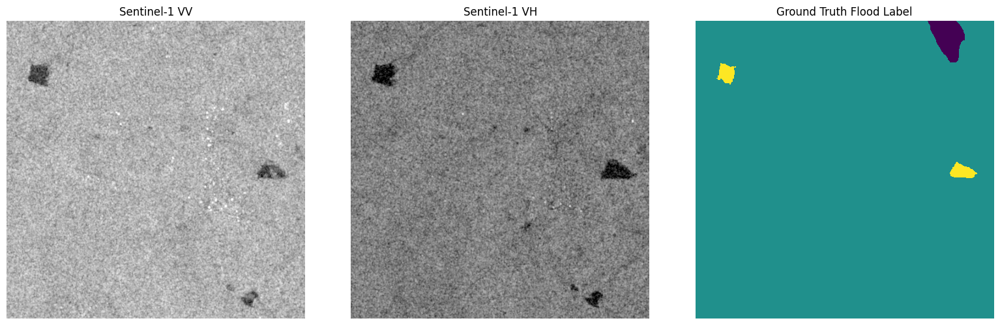

In [ ]:

# ==========================================
# OPEN OUR FIRST SATELLITE IMAGE AND LABEL
# ==========================================

import sys
import importlib.util
import subprocess

# Install rasterio if it is not already available
if importlib.util.find_spec("rasterio") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "rasterio"
    ])

import rasterio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# 1. Locate our project folders

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

s1_folder = PROJECT_DIR / "data/raw/S1Hand"
label_folder = PROJECT_DIR / "data/LabelHand"
split_folder = PROJECT_DIR / "data/splits"


# 2. Read the training CSV

train_df = pd.read_csv(
    split_folder / "flood_train_data.csv",
    header=None,
    names=["satellite_image", "flood_label"]
)


# 3. Select the first image and its matching label

sample = train_df.iloc[0]

s1_path = s1_folder / sample["satellite_image"].strip()
label_path = label_folder / sample["flood_label"].strip()


# 4. Open the satellite image

with rasterio.open(s1_path) as src:
    satellite = src.read()


# 5. Open the corresponding flood label

with rasterio.open(label_path) as src:
    label = src.read(1)


# 6. Print basic information

print("Satellite image:", sample["satellite_image"])
print("Flood label:", sample["flood_label"])

print("\nSatellite image shape:", satellite.shape)
print("Label shape:", label.shape)

print("\nSatellite data type:", satellite.dtype)
print("Label data type:", label.dtype)

print("\nVV range:",
      np.nanmin(satellite[0]),
      "to",
      np.nanmax(satellite[0]))

print("\nVH range:",
      np.nanmin(satellite[1]),
      "to",
      np.nanmax(satellite[1]))

print("\nUnique label values:", np.unique(label))


# 7. Display all three images

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(
    satellite[0],
    cmap="gray",
    vmin=-30,
    vmax=0
)
axes[0].set_title("Sentinel-1 VV")

axes[1].imshow(
    satellite[1],
    cmap="gray",
    vmin=-30,
    vmax=0
)
axes[1].set_title("Sentinel-1 VH")

axes[2].imshow(
    label,
    cmap="viridis",
    vmin=-1,
    vmax=1,
    interpolation="nearest"
)
axes[2].set_title("Ground Truth Flood Label")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# ==========================================
# COUNT WATER AND NON-WATER PIXELS
# ==========================================

import numpy as np

# Count how many times each label appears
values, counts = np.unique(label, return_counts=True)

total_pixels = label.size

print("TOTAL PIXELS:", total_pixels)
print("--------------------------------")

for value, count in zip(values, counts):

    percentage = (count / total_pixels) * 100

    if value == -1:
        name = "No Data"
    elif value == 0:
        name = "Non-Water"
    elif value == 1:
        name = "Water"

    print(name)
    print("Pixel count:", count)
    print("Percentage:", round(percentage, 2), "%")
    print("--------------------------------")


TOTAL PIXELS: 262144
--------------------------------
No Data
Pixel count: 2875
Percentage: 1.1 %
--------------------------------
Non-Water
Pixel count: 257711
Percentage: 98.31 %
--------------------------------
Water
Pixel count: 1558
Percentage: 0.59 %
--------------------------------


In [ ]:

# ==========================================
# CHECK LABEL DISTRIBUTION ACROSS TRAINING DATA
# ==========================================

import pandas as pd
import numpy as np
import rasterio
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

label_folder = PROJECT_DIR / "data/LabelHand"

train_df = pd.read_csv(
    PROJECT_DIR / "data/splits/flood_train_data.csv",
    header=None,
    names=["satellite_image", "flood_label"]
)

# Count pixels across all training labels
pixel_counts = {-1: 0, 0: 0, 1: 0}

print("Analysing training labels...")

for filename in train_df["flood_label"]:

    with rasterio.open(label_folder / filename.strip()) as src:
        mask = src.read(1)

    for value in pixel_counts:
        pixel_counts[value] += int(np.count_nonzero(mask == value))

# Calculate total and valid pixels
total_pixels = sum(pixel_counts.values())
valid_pixels = pixel_counts[0] + pixel_counts[1]

print("\nTRAINING DATA LABEL DISTRIBUTION")
print("--------------------------------")

for value, name in [
    (-1, "No Data"),
    (0, "Non-Water"),
    (1, "Water")
]:

    count = pixel_counts[value]
    percentage = count / total_pixels * 100

    print(f"{name}: {count:,} pixels ({percentage:.2f}%)")

print("--------------------------------")
print("Total pixels:", f"{total_pixels:,}")
print("Valid labelled pixels:", f"{valid_pixels:,}")

print(
    "Water percentage among valid pixels:",
    round(pixel_counts[1] / valid_pixels * 100, 2),
    "%"
)

print("\nTRAINING LABEL ANALYSIS COMPLETED!")


Analysing training labels...

TRAINING DATA LABEL DISTRIBUTION
--------------------------------
No Data: 8,756,881 pixels (13.26%)
Non-Water: 51,856,372 pixels (78.50%)
Water: 5,447,035 pixels (8.25%)
--------------------------------
Total pixels: 66,060,288
Valid labelled pixels: 57,303,407
Water percentage among valid pixels: 9.51 %

TRAINING LABEL ANALYSIS COMPLETED!


In [ ]:

# ==========================================
# VERIFY ALL TRAINING IMAGE-LABEL FILES
# ==========================================

import pandas as pd
import rasterio
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

s1_folder = PROJECT_DIR / "data/raw/S1Hand"
label_folder = PROJECT_DIR / "data/LabelHand"

train_df = pd.read_csv(
    PROJECT_DIR / "data/splits/flood_train_data.csv",
    header=None,
    names=["satellite_image", "flood_label"]
)

correct = 0
errors = []

print("Checking all training image-label pairs...")

for _, row in train_df.iterrows():

    s1_path = s1_folder / row["satellite_image"].strip()
    label_path = label_folder / row["flood_label"].strip()

    try:
        with rasterio.open(s1_path) as s1:
            s1_shape = (s1.count, s1.height, s1.width)
            s1_dtype = s1.dtypes

        with rasterio.open(label_path) as label:
            label_shape = (label.height, label.width)

        if s1_shape == (2, 512, 512) and label_shape == (512, 512):
            correct += 1
        else:
            errors.append((
                row["satellite_image"],
                s1_shape,
                label_shape
            ))

    except Exception as e:
        errors.append((row["satellite_image"], str(e)))

print("\n========== VERIFICATION RESULTS ==========")

print("Total training pairs:", len(train_df))
print("Correct pairs:", correct)
print("Problematic pairs:", len(errors))

if len(errors) == 0:
    print("\nALL TRAINING FILES PASSED THE CHECK!")
else:
    print("\nFiles requiring attention:")
    for error in errors[:10]:
        print(error)


Checking all training image-label pairs...

========== VERIFICATION RESULTS ==========
Total training pairs: 252
Correct pairs: 252
Problematic pairs: 0

ALL TRAINING FILES PASSED THE CHECK!


In [ ]:

# ==========================================
# CHECK SATELLITE IMAGE DATA
# ==========================================

import pandas as pd
import numpy as np
import rasterio
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

train_df = pd.read_csv(
    PROJECT_DIR / "data/splits/flood_train_data.csv",
    header=None,
    names=["satellite_image", "flood_label"]
)

# Select our first training image
filename = train_df.iloc[0]["satellite_image"].strip()

image_path = PROJECT_DIR / "data/raw/S1Hand" / filename

# Open the satellite image
with rasterio.open(image_path) as src:

    image = src.read()

    print("Image:", filename)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Number of bands:", src.count)
    print("Data type:", src.dtypes)
    print("No-data value:", src.nodata)

    print("\nBAND INFORMATION")
    print("--------------------------")

    for i, name in enumerate(["VV", "VH"]):

        band = image[i]
        valid = np.isfinite(band)

        print("\n", name)
        print("Minimum:", np.nanmin(band))
        print("Maximum:", np.nanmax(band))
        print("Mean:", np.nanmean(band))
        print("Invalid pixels:", np.count_nonzero(~valid))

print("\nIMAGE CHECK COMPLETED!")


Image: Ghana_103272_S1Hand.tif
Width: 512
Height: 512
Number of bands: 2
Data type: ('float32', 'float32')
No-data value: nan

BAND INFORMATION
--------------------------

 VV
Minimum: -39.311333
Maximum: 8.5869255
Mean: -9.208067
Invalid pixels: 0

 VH
Minimum: -47.37703
Maximum: -1.3846467
Mean: -15.214209
Invalid pixels: 0

IMAGE CHECK COMPLETED!


In [ ]:

# ==========================================
# CALCULATE TRAINING DATA NORMALIZATION
# ==========================================

import json
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

s1_folder = PROJECT_DIR / "data/raw/S1Hand"

train_df = pd.read_csv(
    PROJECT_DIR / "data/splits/flood_train_data.csv",
    header=None,
    names=["satellite_image", "flood_label"]
)

# Store totals separately for VV and VH
pixel_sum = np.zeros(2, dtype=np.float64)
pixel_sum_sq = np.zeros(2, dtype=np.float64)
pixel_count = np.zeros(2, dtype=np.int64)

print("Calculating mean and standard deviation...")
print("Images to process:", len(train_df))

for i, filename in enumerate(train_df["satellite_image"]):

    image_path = s1_folder / filename.strip()

    with rasterio.open(image_path) as src:
        image = src.read()

        nodata = src.nodata

    for band in range(2):

        values = image[band].astype(np.float64)

        valid = np.isfinite(values)

        if nodata is not None and np.isfinite(nodata):
            valid &= values != nodata

        valid_values = values[valid]

        pixel_sum[band] += valid_values.sum()
        pixel_sum_sq[band] += np.square(valid_values).sum()
        pixel_count[band] += valid_values.size

    if (i + 1) % 50 == 0:
        print(f"Processed {i + 1}/252 images")

# Calculate mean and population standard deviation
means = pixel_sum / pixel_count

variances = pixel_sum_sq / pixel_count - means**2

stds = np.sqrt(np.maximum(variances, 0))

# Display results
print("\nNORMALIZATION RESULTS")
print("----------------------------")

for i, name in enumerate(["VV", "VH"]):

    print(f"\n{name}")
    print("Mean:", round(means[i], 6))
    print("Standard deviation:", round(stds[i], 6))
    print("Valid pixels:", f"{pixel_count[i]:,}")

# Save values for later use
stats = {
    "mean": means.tolist(),
    "std": stds.tolist(),
    "bands": ["VV", "VH"],
    "source": "Sen1Floods11 training split only"
}

output_file = PROJECT_DIR / "data/processed/normalization_stats.json"

with open(output_file, "w") as f:
    json.dump(stats, f, indent=4)

print("\nNormalization values saved successfully!")
print(output_file)


Calculating mean and standard deviation...
Images to process: 252
Processed 50/252 images
Processed 100/252 images
Processed 150/252 images
Processed 200/252 images
Processed 250/252 images

NORMALIZATION RESULTS
----------------------------

VV
Mean: -10.392862
Standard deviation: 4.038801
Valid pixels: 64,735,152

VH
Mean: -17.241102
Standard deviation: 4.753971
Valid pixels: 64,735,152

Normalization values saved successfully!
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/data/processed/normalization_stats.json


In [ ]:

# ==========================================
# MEMBER A: DERIVE ROBUST SAR CLIPPING LIMITS
# ==========================================

import numpy as np
import pandas as pd
import rasterio

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

S1_DIR = PROJECT_DIR / "data/raw/S1Hand"
CLEAN_DIR = PROJECT_DIR / "data/processed/clean_splits"

# Use the exact cleaned training split
train_df = pd.read_csv(
    CLEAN_DIR / "train_clean.csv",
    dtype=str
)

rng = np.random.default_rng(42)

samples = [[], []]
SAMPLES_PER_IMAGE = 20000

print("DERIVING TRAINING-ONLY CLIPPING LIMITS")
print("--------------------------------------")
print("Training images:", len(train_df))

for i, filename in enumerate(train_df["satellite_image"]):

    image_path = S1_DIR / filename.strip()

    with rasterio.open(image_path) as src:
        image = src.read().astype(np.float32)
        nodata = src.nodata

    # Keep pixels valid in both VV and VH
    valid = np.isfinite(image).all(axis=0)

    if nodata is not None and np.isfinite(nodata):
        valid &= np.all(image != nodata, axis=0)

    for band in range(2):

        values = image[band][valid]

        if values.size == 0:
            continue

        n = min(SAMPLES_PER_IMAGE, values.size)

        sampled = rng.choice(
            values,
            size=n,
            replace=False
        )

        samples[band].append(sampled)

    if (i + 1) % 50 == 0:
        print(f"Processed {i + 1}/{len(train_df)} images")

# Estimate global channel-wise clipping limits
print("\nPROPOSED CLIPPING LIMITS")
print("--------------------------------------")

clip_values = {}

for band, name in enumerate(["VV", "VH"]):

    pooled = np.concatenate(samples[band])

    lower, upper = np.percentile(
        pooled, [1, 99]
    )

    clip_values[name] = [float(lower), float(upper)]

    print(f"\n{name}")
    print("1st percentile:", round(lower, 4), "dB")
    print("99th percentile:", round(upper, 4), "dB")
    print("Sampled valid pixels:", f"{len(pooled):,}")

print("\nCLIPPING LIMIT INSPECTION COMPLETED!")
print("No existing files were modified.")


DERIVING TRAINING-ONLY CLIPPING LIMITS
--------------------------------------
Training images: 251
Processed 50/251 images
Processed 100/251 images
Processed 150/251 images
Processed 200/251 images
Processed 250/251 images

PROPOSED CLIPPING LIMITS
--------------------------------------

VV
1st percentile: -23.8216 dB
99th percentile: -2.4397 dB
Sampled valid pixels: 5,020,000

VH
1st percentile: -34.0875 dB
99th percentile: -9.5387 dB
Sampled valid pixels: 5,020,000

CLIPPING LIMIT INSPECTION COMPLETED!
No existing files were modified.


In [ ]:

# ==========================================
# MEMBER A: FINAL CLIPPED NORMALIZATION
# ==========================================

import json
import numpy as np
import pandas as pd
import rasterio

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

S1_DIR = PROJECT_DIR / "data/raw/S1Hand"
CLEAN_DIR = PROJECT_DIR / "data/processed/clean_splits"

# Use cleaned training data ONLY
train_df = pd.read_csv(
    CLEAN_DIR / "train_clean.csv",
    dtype=str
)

# Proposed limits from the previous diagnostic cell
CLIP_MIN = np.array([-23.8216, -34.0875], dtype=np.float64)
CLIP_MAX = np.array([-2.4397, -9.5387], dtype=np.float64)

pixel_sum = np.zeros(2, dtype=np.float64)
pixel_sum_sq = np.zeros(2, dtype=np.float64)
pixel_count = np.zeros(2, dtype=np.int64)

print("CALCULATING CLIPPED NORMALIZATION STATISTICS")
print("--------------------------------------------")
print("Training images:", len(train_df))

for i, filename in enumerate(train_df["satellite_image"]):

    image_path = S1_DIR / filename.strip()

    with rasterio.open(image_path) as src:
        image = src.read().astype(np.float64)
        nodata = src.nodata

    # Common valid mask for both VV and VH
    valid = np.isfinite(image).all(axis=0)

    if nodata is not None and np.isfinite(nodata):
        valid &= np.all(image != nodata, axis=0)

    for band in range(2):

        values = image[band][valid]

        # Clip before normalization
        values = np.clip(
            values,
            CLIP_MIN[band],
            CLIP_MAX[band]
        )

        pixel_sum[band] += values.sum(dtype=np.float64)
        pixel_sum_sq[band] += np.square(values).sum(dtype=np.float64)
        pixel_count[band] += values.size

    if (i + 1) % 50 == 0:
        print(f"Processed {i + 1}/{len(train_df)} images")

# Calculate population mean and standard deviation
means = pixel_sum / pixel_count

variances = (
    pixel_sum_sq / pixel_count - means**2
)

stds = np.sqrt(np.maximum(variances, 0))

if np.any(stds <= 0) or np.any(pixel_count == 0):
    raise ValueError("Invalid normalization statistics!")

# Prepare preprocessing configuration
stats = {
    "mean": means.tolist(),
    "std": stds.tolist(),
    "bands": ["VV", "VH"],
    "clip_min": CLIP_MIN.tolist(),
    "clip_max": CLIP_MAX.tolist(),
    "percentiles": [1, 99],
    "training_images": len(train_df),
    "source": "Cleaned training split only",
    "standard_deviation": "population"
}

# Save separately; preserve original statistics
output_file = (
    PROJECT_DIR /
    "data/processed/normalization_stats_clipped.json"
)

with open(output_file, "w") as f:
    json.dump(stats, f, indent=4)

print("\nFINAL CLIPPED NORMALIZATION RESULTS")
print("--------------------------------------------")

for i, name in enumerate(["VV", "VH"]):

    print(f"\n{name}")
    print("Clipping:", CLIP_MIN[i], "to", CLIP_MAX[i])
    print("Mean:", round(means[i], 6))
    print("Standard deviation:", round(stds[i], 6))
    print("Valid pixels:", f"{pixel_count[i]:,}")

print("\nNew statistics saved at:")
print(output_file)

print("\nCLIPPED NORMALIZATION COMPLETED!")


CALCULATING CLIPPED NORMALIZATION STATISTICS
--------------------------------------------
Training images: 251
Processed 50/251 images
Processed 100/251 images
Processed 150/251 images
Processed 200/251 images
Processed 250/251 images

FINAL CLIPPED NORMALIZATION RESULTS
--------------------------------------------

VV
Clipping: -23.8216 to -2.4397
Mean: -10.399012
Standard deviation: 3.880121
Valid pixels: 64,473,008

VH
Clipping: -34.0875 to -9.5387
Mean: -17.21706
Standard deviation: 4.482825
Valid pixels: 64,473,008

New statistics saved at:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/data/processed/normalization_stats_clipped.json

CLIPPED NORMALIZATION COMPLETED!


In [ ]:

# ==========================================
# MEMBER A: BUILD THE FLOOD DATASET CLASS
# ==========================================

import json
import torch
import numpy as np
import pandas as pd
import rasterio

from pathlib import Path
from torch.utils.data import Dataset


# 1. PROJECT PATHS

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

S1_DIR = PROJECT_DIR / "data/raw/S1Hand"
LABEL_DIR = PROJECT_DIR / "data/LabelHand"
SPLIT_DIR = PROJECT_DIR / "data/splits"


# 2. LOAD TRAINING CSV

train_df = pd.read_csv(
    SPLIT_DIR / "flood_train_data.csv",
    header=None,
    names=["satellite_image", "flood_label"]
)


# 3. LOAD NORMALIZATION VALUES

with open(
    PROJECT_DIR / "data/processed/normalization_stats.json",
    "r"
) as f:

    stats = json.load(f)

MEAN = np.array(stats["mean"], dtype=np.float32)
STD = np.array(stats["std"], dtype=np.float32)


# 4. CREATE OUR DATASET CLASS

class FloodDataset(Dataset):

    def __init__(self, dataframe):

        self.dataframe = dataframe.reset_index(drop=True)


    def __len__(self):

        return len(self.dataframe)


    def __getitem__(self, index):

        # Get filenames
        row = self.dataframe.iloc[index]

        image_path = S1_DIR / row["satellite_image"].strip()
        label_path = LABEL_DIR / row["flood_label"].strip()


        # Read satellite image
        with rasterio.open(image_path) as src:

            image = src.read().astype(np.float32)
            nodata = src.nodata


        # Identify valid satellite pixels
        valid_sar = np.isfinite(image).all(axis=0)

        if nodata is not None:

            if np.isnan(nodata):
                valid_sar &= ~np.isnan(image).any(axis=0)

            else:
                valid_sar &= np.all(image != nodata, axis=0)


        # Read corresponding flood label
        with rasterio.open(label_path) as src:

            label = src.read(1).astype(np.int16)


        # Ignore pixels with missing labels
        valid_mask = (label != -1) & valid_sar


        # Convert water pixels to 1
        target = (label == 1).astype(np.float32)


        # Normalize VV and VH
        image = (
            image - MEAN[:, None, None]
        ) / STD[:, None, None]


        # Replace invalid satellite pixels with zero
        image[:, ~valid_sar] = 0.0


        # Convert everything into PyTorch tensors

        image = torch.from_numpy(
            np.ascontiguousarray(image)
        )

        target = torch.from_numpy(
            np.ascontiguousarray(target[None, :, :])
        )

        valid_mask = torch.from_numpy(
            np.ascontiguousarray(valid_mask[None, :, :])
        )

        return image, target, valid_mask


# 5. CREATE OUR TRAINING DATASET

train_dataset = FloodDataset(train_df)

print("Dataset created successfully!")
print("Number of training images:", len(train_dataset))


# 6. TEST ONE SAMPLE

image, mask, valid_mask = train_dataset[0]

print("\nFIRST SAMPLE INFORMATION")
print("--------------------------------")

print("Image shape:", image.shape)
print("Label shape:", mask.shape)
print("Valid mask shape:", valid_mask.shape)

print("\nImage type:", image.dtype)
print("Label type:", mask.dtype)
print("Valid pixels:", valid_mask.sum().item())

print("\nDATASET CLASS WORKING SUCCESSFULLY!")


Dataset created successfully!
Number of training images: 252

FIRST SAMPLE INFORMATION
--------------------------------
Image shape: torch.Size([2, 512, 512])
Label shape: torch.Size([1, 512, 512])
Valid mask shape: torch.Size([1, 512, 512])

Image type: torch.float32
Label type: torch.float32
Valid pixels: 259269

DATASET CLASS WORKING SUCCESSFULLY!


In [ ]:

# ==========================================
# BUILD OUR FIRST PYTORCH DATALOADER
# ==========================================

from torch.utils.data import DataLoader

# Create the training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Load the first batch
images, labels, valid_masks = next(iter(train_loader))

# Display batch information
print("DATALOADER WORKING SUCCESSFULLY!")
print("----------------------------------")

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Valid masks shape:", valid_masks.shape)

print("\nImage data type:", images.dtype)
print("Label data type:", labels.dtype)
print("Mask data type:", valid_masks.dtype)

print("\nNumber of images in this batch:", images.shape[0])

print("\nUnique label values:",
      torch.unique(labels[valid_masks]))

print("\nFIRST BATCH LOADED SUCCESSFULLY!")


DATALOADER WORKING SUCCESSFULLY!
----------------------------------
Images shape: torch.Size([4, 2, 512, 512])
Labels shape: torch.Size([4, 1, 512, 512])
Valid masks shape: torch.Size([4, 1, 512, 512])

Image data type: torch.float32
Label data type: torch.float32
Mask data type: torch.bool

Number of images in this batch: 4

Unique label values: tensor([0., 1.])

FIRST BATCH LOADED SUCCESSFULLY!


In [ ]:

# ==========================================
# CREATE VALIDATION AND TEST DATALOADERS
# ==========================================

# 1. Read validation CSV
valid_df = pd.read_csv(
    SPLIT_DIR / "flood_valid_data.csv",
    header=None,
    names=["satellite_image", "flood_label"]
)

# 2. Read testing CSV
test_df = pd.read_csv(
    SPLIT_DIR / "flood_test_data.csv",
    header=None,
    names=["satellite_image", "flood_label"]
)


# 3. Create separate datasets
valid_dataset = FloodDataset(valid_df)

test_dataset = FloodDataset(test_df)


# 4. Create validation DataLoader
valid_loader = DataLoader(
    valid_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)


# 5. Create testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)


# 6. Verify everything
print("DATASET AND DATALOADER SUMMARY")
print("--------------------------------")

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Testing images:", len(test_dataset))

print("\nNumber of training batches:", len(train_loader))
print("Number of validation batches:", len(valid_loader))
print("Number of testing batches:", len(test_loader))


# 7. Load one validation batch
val_images, val_labels, val_masks = next(iter(valid_loader))

print("\nVALIDATION BATCH SHAPES")
print("Images:", val_images.shape)
print("Labels:", val_labels.shape)
print("Masks:", val_masks.shape)

print("\nALL DATALOADERS CREATED SUCCESSFULLY!")


DATASET AND DATALOADER SUMMARY
--------------------------------
Training images: 252
Validation images: 89
Testing images: 90

Number of training batches: 63
Number of validation batches: 23
Number of testing batches: 23

VALIDATION BATCH SHAPES
Images: torch.Size([4, 2, 512, 512])
Labels: torch.Size([4, 1, 512, 512])
Masks: torch.Size([4, 1, 512, 512])

ALL DATALOADERS CREATED SUCCESSFULLY!


In [ ]:

# Check the testing DataLoader

test_images, test_labels, test_masks = next(iter(test_loader))

print("TEST DATALOADER CHECK")
print("----------------------------")

print("Images:", test_images.shape)
print("Labels:", test_labels.shape)
print("Masks:", test_masks.shape)

print("All image values finite:",
      torch.isfinite(test_images).all().item())

print("Valid pixels:", test_masks.sum().item())

print("Unique labels:",
      torch.unique(test_labels[test_masks]))

print("\nTEST DATALOADER WORKING!")


TEST DATALOADER CHECK
----------------------------
Images: torch.Size([4, 2, 512, 512])
Labels: torch.Size([4, 1, 512, 512])
Masks: torch.Size([4, 1, 512, 512])
All image values finite: True
Valid pixels: 796146
Unique labels: tensor([0., 1.])

TEST DATALOADER WORKING!


In [ ]:

%pip install -q segmentation-models-pytorch==0.6.0


In [ ]:

# Check U-Net library installation

import segmentation_models_pytorch as smp

print("Library installed successfully!")
print("Version:", smp.__version__)


Library installed successfully!
Version: 0.6.0


In [ ]:

# ==========================================
# BUILD OUR FIRST U-NET MODEL
# ==========================================

import torch
import segmentation_models_pytorch as smp

# 1. Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


# 2. Create U-Net with ResNet-34 encoder

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=2,
    classes=1,
    activation=None
)

# 3. Move model to GPU
model = model.to(device)

print("\nU-Net model created successfully!")

print("Architecture: U-Net")
print("Encoder: ResNet-34")
print("Input channels: 2 (VV + VH)")
print("Output channels: 1")


# 4. Test the model with one satellite image

sample_images, _, _ = next(iter(train_loader))

sample_input = sample_images[:1].to(device)

model.eval()

with torch.inference_mode():

    prediction = model(sample_input)


# 5. Display output information

print("\nMODEL TEST RESULTS")
print("-----------------------------")

print("Input shape:", sample_input.shape)
print("Output shape:", prediction.shape)

print("Output data type:", prediction.dtype)

print("\nU-NET FORWARD PASS SUCCESSFUL!")


Using device: cuda


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            


U-Net model created successfully!
Architecture: U-Net
Encoder: ResNet-34
Input channels: 2 (VV + VH)
Output channels: 1

MODEL TEST RESULTS
-----------------------------
Input shape: torch.Size([1, 2, 512, 512])
Output shape: torch.Size([1, 1, 512, 512])
Output data type: torch.float32

U-NET FORWARD PASS SUCCESSFUL!


In [ ]:

# ==========================================
# MEMBER A: BCE + DICE LOSS
# ==========================================

import torch
import torch.nn.functional as F


def bce_dice_loss(logits, targets, valid_masks):

    # Convert valid mask to float
    valid = valid_masks.float()

    # 1. BINARY CROSS-ENTROPY LOSS

    bce_map = F.binary_cross_entropy_with_logits(
        logits,
        targets,
        reduction="none"
    )

    # Ignore invalid pixels
    bce_loss = (
        (bce_map * valid).sum()
        / valid.sum().clamp_min(1)
    )


    # 2. DICE LOSS

    probabilities = torch.sigmoid(logits)

    intersection = (
        probabilities * targets * valid
    ).sum(dim=(1, 2, 3))

    denominator = (
        (probabilities + targets) * valid
    ).sum(dim=(1, 2, 3))

    dice_score = (
        (2.0 * intersection + 1.0)
        / (denominator + 1.0)
    )

    dice_loss = (1.0 - dice_score).mean()


    # 3. COMBINE BOTH LOSSES

    total_loss = 0.5 * bce_loss + 0.5 * dice_loss

    return total_loss, bce_loss, dice_loss


print("BCE + Dice Loss implemented successfully!")


BCE + Dice Loss implemented successfully!


In [ ]:

# ==========================================
# TEST BCE + DICE LOSS
# ==========================================

# Get one training batch
images, labels, valid_masks = next(iter(train_loader))

# Move data to GPU
images = images.to(device)
labels = labels.to(device)
valid_masks = valid_masks.to(device)

# Set model to evaluation mode for this test
model.eval()

# Clear old gradients
model.zero_grad(set_to_none=True)

# Make predictions
logits = model(images)

# Calculate losses
total_loss, bce, dice = bce_dice_loss(
    logits,
    labels,
    valid_masks
)

print("LOSS FUNCTION TEST")
print("--------------------------")

print("BCE Loss:", bce.item())
print("Dice Loss:", dice.item())
print("Combined Loss:", total_loss.item())

# Check that the loss is valid
assert torch.isfinite(total_loss).item()

# Check that gradients can flow through the model
total_loss.backward()

gradients_ok = all(
    parameter.grad is None
    or torch.isfinite(parameter.grad).all().item()
    for parameter in model.parameters()
)

print("Gradient check:", gradients_ok)

# Clear test gradients
model.zero_grad(set_to_none=True)

print("\nLOSS FUNCTION WORKING SUCCESSFULLY!")


LOSS FUNCTION TEST
--------------------------
BCE Loss: 0.5013308525085449
Dice Loss: 0.8472226858139038
Combined Loss: 0.6742767691612244
Gradient check: True

LOSS FUNCTION WORKING SUCCESSFULLY!


In [ ]:

# ==========================================
# SET UP THE ADAMW OPTIMIZER
# ==========================================

import torch

# Create optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

# Count trainable parameters
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("OPTIMIZER CREATED SUCCESSFULLY!")
print("--------------------------------")

print("Optimizer: AdamW")
print("Learning rate:", 0.0001)
print("Weight decay:", 0.0001)

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)

print("\nMODEL IS READY FOR TRAINING!")


OPTIMIZER CREATED SUCCESSFULLY!
--------------------------------
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Trainable parameters: 24,433,233

MODEL IS READY FOR TRAINING!


In [ ]:

# ==========================================
# PREPARE OUR TRAINING WORKSPACE
# ==========================================

from pathlib import Path

# Create folders
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
LOG_DIR = PROJECT_DIR / "logs"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

# File locations
BEST_MODEL_PATH = CHECKPOINT_DIR / "best_unet_resnet34.pth"

TRAINING_HISTORY_PATH = LOG_DIR / "training_history.csv"

# Initial training settings
NUM_EPOCHS = 1  # First run: only one epoch
BATCH_SIZE = 4
LEARNING_RATE = 0.0001
WEIGHT_DECAY = 0.0001

print("TRAINING WORKSPACE READY!")
print("----------------------------")

print("Epochs for initial test:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)

print("\nBest model will be saved at:")
print(BEST_MODEL_PATH)

print("\nTraining history will be saved at:")
print(TRAINING_HISTORY_PATH)


TRAINING WORKSPACE READY!
----------------------------
Epochs for initial test: 1
Batch size: 4
Learning rate: 0.0001

Best model will be saved at:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/checkpoints/best_unet_resnet34.pth

Training history will be saved at:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/logs/training_history.csv


In [ ]:

# ==========================================
# FIRST U-NET TRAINING RUN
# ONE EPOCH
# ==========================================

import torch
import torch.nn.functional as F
import pandas as pd

from tqdm.auto import tqdm


# 1. DEFINE THE FINAL LOSS FUNCTION

def bce_dice_loss(logits, targets, valid_masks):

    logits = logits.float()
    targets = targets.float()
    valid = valid_masks.float()

    # Binary Cross-Entropy
    bce_map = F.binary_cross_entropy_with_logits(
        logits,
        targets,
        reduction="none"
    )

    bce = (
        (bce_map * valid).sum()
        / valid.sum().clamp_min(1)
    )

    # Dice Loss
    probabilities = torch.sigmoid(logits)

    intersection = (
        probabilities * targets * valid
    ).sum(dim=(1, 2, 3))

    denominator = (
        (probabilities + targets) * valid
    ).sum(dim=(1, 2, 3))

    dice_score = (
        (2 * intersection + 1)
        / (denominator + 1)
    )

    dice = (1 - dice_score).mean()

    total = 0.5 * bce + 0.5 * dice

    return total, bce, dice


# 2. PREPARE MIXED PRECISION

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)


# 3. TRAINING

print("STARTING U-NET TRAINING...")

model.train()

train_loss_sum = 0.0
train_count = 0

for images, labels, masks in tqdm(
    train_loader,
    desc="Training"
):

    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)
    masks = masks.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type=device.type,
        dtype=torch.float16,
        enabled=(device.type == "cuda")
    ):

        logits = model(images)

        loss, bce, dice = bce_dice_loss(
            logits,
            labels,
            masks
        )

    scaler.scale(loss).backward()

    scaler.step(optimizer)
    scaler.update()

    batch_size = images.size(0)

    train_loss_sum += loss.item() * batch_size
    train_count += batch_size


train_loss = train_loss_sum / train_count


# 4. VALIDATION

print("\nVALIDATING MODEL...")

model.eval()

valid_loss_sum = 0.0
valid_count = 0

with torch.inference_mode():

    for images, labels, masks in tqdm(
        valid_loader,
        desc="Validation"
    ):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            logits = model(images)

            loss, _, _ = bce_dice_loss(
                logits,
                labels,
                masks
            )

        batch_size = images.size(0)

        valid_loss_sum += loss.item() * batch_size
        valid_count += batch_size


valid_loss = valid_loss_sum / valid_count


# 5. SAVE MODEL CHECKPOINT

checkpoint = {
    "epoch": 1,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "validation_loss": valid_loss,
    "normalization_mean": MEAN.tolist(),
    "normalization_std": STD.tolist()
}

torch.save(checkpoint, BEST_MODEL_PATH)


# 6. SAVE TRAINING HISTORY

history = pd.DataFrame([{
    "epoch": 1,
    "train_loss": train_loss,
    "validation_loss": valid_loss
}])

history.to_csv(
    TRAINING_HISTORY_PATH,
    index=False
)


# 7. DISPLAY RESULTS

print("\n================================")
print("FIRST TRAINING RUN COMPLETED")
print("================================")

print("Training images:", train_count)
print("Validation images:", valid_count)

print("Training loss:", round(train_loss, 5))
print("Validation loss:", round(valid_loss, 5))

print("\nModel saved at:")
print(BEST_MODEL_PATH)

print("\nTraining history saved successfully!")

print("\nU-NET TRAINING SUCCESSFUL!")


STARTING U-NET TRAINING...


Training:   0%|          | 0/63 [00:00<?, ?it/s]


VALIDATING MODEL...


Validation:   0%|          | 0/23 [00:00<?, ?it/s]


FIRST TRAINING RUN COMPLETED
Training images: 252
Validation images: 89
Training loss: 0.69139
Validation loss: 0.57022

Model saved at:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/checkpoints/best_unet_resnet34.pth

Training history saved successfully!

U-NET TRAINING SUCCESSFUL!


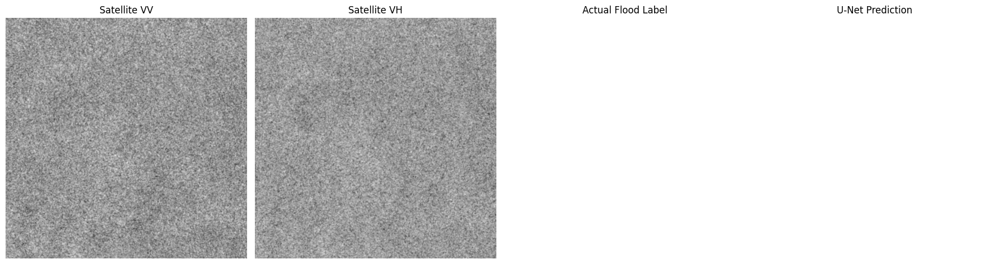

Visualization completed!
Prediction threshold: 0.5


In [ ]:

# ==========================================
# VISUALIZE OUR FIRST U-NET PREDICTION
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import torch

# Get one validation batch
vis_images, vis_labels, vis_masks = next(iter(valid_loader))

# Move images to GPU
input_images = vis_images.to(device)

# Generate predictions
model.eval()

with torch.inference_mode():
    logits = model(input_images)
    probabilities = torch.sigmoid(logits)

# Select the first image
vv = vis_images[0, 0].numpy()
vh = vis_images[0, 1].numpy()

actual = vis_labels[0, 0].numpy()

valid = vis_masks[0, 0].numpy().astype(bool)

predicted = (
    probabilities[0, 0].cpu().numpy() >= 0.5
).astype(np.float32)

# Hide pixels without valid labels
actual_display = np.where(valid, actual, np.nan)
predicted_display = np.where(valid, predicted, np.nan)

# Display four images
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(vv, cmap="gray", vmin=-3, vmax=3)
axes[0].set_title("Satellite VV")

axes[1].imshow(vh, cmap="gray", vmin=-3, vmax=3)
axes[1].set_title("Satellite VH")

axes[2].imshow(
    actual_display,
    cmap="viridis",
    vmin=0,
    vmax=1
)
axes[2].set_title("Actual Flood Label")

axes[3].imshow(
    predicted_display,
    cmap="viridis",
    vmin=0,
    vmax=1
)
axes[3].set_title("U-Net Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Visualization completed!")
print("Prediction threshold: 0.5")


In [ ]:

# Check why the label and prediction look blank

print("VALIDATION IMAGE CHECK")
print("------------------------------")

print("Total pixels:", valid.size)
print("Valid pixels:", int(valid.sum()))
print("Invalid pixels:", int((~valid).sum()))

print("\nOriginal label values:")
print(np.unique(actual, return_counts=True))

if valid.sum() > 0:
    print("\nLabels among valid pixels:")
    print(np.unique(actual[valid], return_counts=True))
else:
    print("\nWARNING: This image has no valid labelled pixels!")

print("\nPrediction probability range:")
print("Minimum:", probabilities[0, 0].min().item())
print("Maximum:", probabilities[0, 0].max().item())


VALIDATION IMAGE CHECK
------------------------------
Total pixels: 262144
Valid pixels: 0
Invalid pixels: 262144

Original label values:
(array([0.], dtype=float32), array([262144]))


Prediction probability range:
Minimum: 0.056202445179224014
Maximum: 0.8275375962257385


In [ ]:

# Inspect the validation image that appeared blank

row = valid_df.iloc[0]

s1_path = S1_DIR / row["satellite_image"].strip()
label_path = LABEL_DIR / row["flood_label"].strip()

print("SATELLITE IMAGE:", s1_path.name)
print("FLOOD LABEL:", label_path.name)

# Read the original satellite image
with rasterio.open(s1_path) as src:
    raw_image = src.read().astype(np.float32)
    nodata = src.nodata

print("\nSATELLITE IMAGE INFORMATION")
print("No-data value:", nodata)

for i, name in enumerate(["VV", "VH"]):
    band = raw_image[i]
    finite = np.isfinite(band)

    print("\n", name)
    print("Finite pixels:", int(finite.sum()))
    print("Invalid pixels:", int((~finite).sum()))

    if finite.any():
        print("Minimum:", band[finite].min())
        print("Maximum:", band[finite].max())

# Read the original flood label
with rasterio.open(label_path) as src:
    raw_label = src.read(1)

print("\nFLOOD LABEL VALUES:")
print(np.unique(raw_label, return_counts=True))

# Check satellite validity using our current rule
valid_sar = np.isfinite(raw_image).all(axis=0)

if nodata is not None:
    if np.isnan(nodata):
        valid_sar &= ~np.isnan(raw_image).any(axis=0)
    else:
        valid_sar &= np.all(raw_image != nodata, axis=0)

print("\nVALID SATELLITE PIXELS:", int(valid_sar.sum()))

print("\nIMAGE INSPECTION COMPLETED!")


SATELLITE IMAGE: Ghana_5079_S1Hand.tif
FLOOD LABEL: Ghana_5079_LabelHand.tif

SATELLITE IMAGE INFORMATION
No-data value: nan

 VV
Finite pixels: 262144
Invalid pixels: 0
Minimum: -19.357038
Maximum: -0.011350544

 VH
Finite pixels: 262144
Invalid pixels: 0
Minimum: -32.190178
Maximum: -6.5972958

FLOOD LABEL VALUES:
(array([-1], dtype=int16), array([262144]))

VALID SATELLITE PIXELS: 262144

IMAGE INSPECTION COMPLETED!


Searching validation images...

Found a usable image!
Image index: 1
Valid pixels: 252706


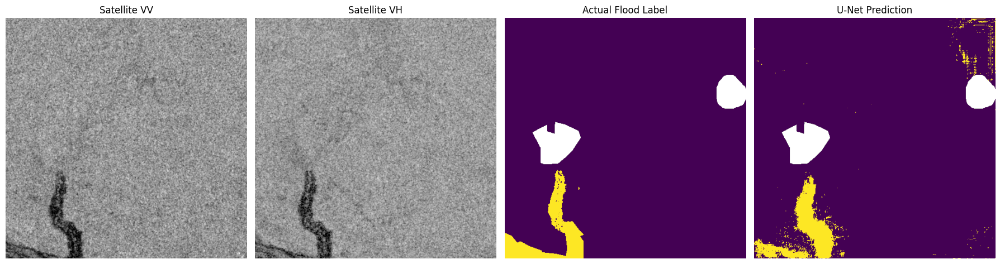


Selected image:
Ghana_895194_S1Hand.tif

Actual label distribution:
(array([0., 1.], dtype=float32), array([244009,   8697]))

VISUALIZATION COMPLETED!


In [ ]:

# ==========================================
# FIND A VALIDATION IMAGE WITH USABLE LABELS
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import torch

selected_index = None

print("Searching validation images...")

# Look through validation images until we find
# one that contains valid labelled pixels.

for i in range(len(valid_dataset)):

    image, target, valid_mask = valid_dataset[i]

    valid_count = int(valid_mask.sum().item())

    if valid_count > 0:
        selected_index = i
        print("\nFound a usable image!")
        print("Image index:", i)
        print("Valid pixels:", valid_count)
        break

if selected_index is None:

    print("No usable validation image found.")

else:

    # Load the selected image
    image, target, valid_mask = valid_dataset[selected_index]

    # Run U-Net prediction
    model.eval()

    with torch.inference_mode():

        logits = model(image.unsqueeze(0).to(device))

        prediction = torch.sigmoid(logits)[0, 0]
        prediction = prediction.cpu().numpy()

    # Convert tensors into NumPy arrays
    vv = image[0].numpy()
    vh = image[1].numpy()

    actual = target[0].numpy()
    valid = valid_mask[0].numpy()

    predicted = (prediction >= 0.5).astype(np.float32)

    # Hide unlabelled pixels
    actual = np.where(valid, actual, np.nan)
    predicted = np.where(valid, predicted, np.nan)

    # Display all four images
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    axes[0].imshow(vv, cmap="gray", vmin=-3, vmax=3)
    axes[0].set_title("Satellite VV")

    axes[1].imshow(vh, cmap="gray", vmin=-3, vmax=3)
    axes[1].set_title("Satellite VH")

    axes[2].imshow(actual, cmap="viridis", vmin=0, vmax=1)
    axes[2].set_title("Actual Flood Label")

    axes[3].imshow(predicted, cmap="viridis", vmin=0, vmax=1)
    axes[3].set_title("U-Net Prediction")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print("\nSelected image:")
    print(valid_df.iloc[selected_index]["satellite_image"])

    print("\nActual label distribution:")
    print(np.unique(target[0].numpy()[valid], return_counts=True))

    print("\nVISUALIZATION COMPLETED!")


In [ ]:

# ==========================================
# CHECK LABEL QUALITY ACROSS ALL DATA SPLITS
# ==========================================

import pandas as pd
import numpy as np
import rasterio

split_files = {
    "Training": "flood_train_data.csv",
    "Validation": "flood_valid_data.csv",
    "Testing": "flood_test_data.csv",
    "Bolivia": "flood_bolivia_data.csv"
}

print("CHECKING ALL DATASET LABELS")
print("============================")

for split_name, filename in split_files.items():

    df = pd.read_csv(
        SPLIT_DIR / filename,
        header=None,
        names=["satellite_image", "flood_label"]
    )

    empty = 0
    partially_labelled = 0
    images_with_water = 0

    total_water = 0
    total_nonwater = 0
    total_nodata = 0

    for label_name in df["flood_label"]:

        path = LABEL_DIR / label_name.strip()

        with rasterio.open(path) as src:
            label = src.read(1)

        water = int(np.sum(label == 1))
        nonwater = int(np.sum(label == 0))
        nodata = int(np.sum(label == -1))

        total_water += water
        total_nonwater += nonwater
        total_nodata += nodata

        if water + nonwater == 0:
            empty += 1

        else:
            partially_labelled += 1

        if water > 0:
            images_with_water += 1

    print(f"\n{split_name}")
    print("----------------------------")
    print("Total images:", len(df))
    print("Completely unlabelled:", empty)
    print("Images with valid labels:", partially_labelled)
    print("Images containing water:", images_with_water)
    print("Water pixels:", f"{total_water:,}")
    print("Non-water pixels:", f"{total_nonwater:,}")
    print("No-data pixels:", f"{total_nodata:,}")

print("\nLABEL QUALITY CHECK COMPLETED!")


CHECKING ALL DATASET LABELS

Training
----------------------------
Total images: 252
Completely unlabelled: 1
Images with valid labels: 251
Images containing water: 219
Water pixels: 5,447,035
Non-water pixels: 51,856,372
No-data pixels: 8,756,881

Validation
----------------------------
Total images: 89
Completely unlabelled: 3
Images with valid labels: 86
Images containing water: 77
Water pixels: 2,237,605
Non-water pixels: 18,057,120
No-data pixels: 3,036,091

Testing
----------------------------
Total images: 90
Completely unlabelled: 1
Images with valid labels: 89
Images containing water: 83
Water pixels: 2,566,101
Non-water pixels: 17,951,266
No-data pixels: 3,075,593

Bolivia
----------------------------
Total images: 15
Completely unlabelled: 0
Images with valid labels: 15
Images containing water: 15
Water pixels: 454,864
Non-water pixels: 2,412,951
No-data pixels: 1,064,345

LABEL QUALITY CHECK COMPLETED!


In [ ]:

# ==========================================
# CLEAN DATASET SPLITS
# REMOVE COMPLETELY UNLABELLED IMAGES
# ==========================================

import pandas as pd
import numpy as np
import rasterio

from pathlib import Path
from torch.utils.data import DataLoader

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

SPLIT_DIR = PROJECT_DIR / "data/splits"
LABEL_DIR = PROJECT_DIR / "data/LabelHand"

CLEAN_DIR = PROJECT_DIR / "data/processed/clean_splits"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

# Original CSV files
split_files = {
    "train": "flood_train_data.csv",
    "valid": "flood_valid_data.csv",
    "test": "flood_test_data.csv",
    "bolivia": "flood_bolivia_data.csv"
}

clean_splits = {}

print("CLEANING DATASET...")
print("--------------------------------")

for split_name, filename in split_files.items():

    df = pd.read_csv(
        SPLIT_DIR / filename,
        header=None,
        names=["satellite_image", "flood_label"],
        dtype=str
    )

    keep_indices = []

    for i, row in df.iterrows():

        label_path = LABEL_DIR / row["flood_label"].strip()

        with rasterio.open(label_path) as src:
            label = src.read(1)

        # A usable pixel must be either water (1)
        # or non-water (0).
        valid_pixels = np.count_nonzero(
            (label == 0) | (label == 1)
        )

        if valid_pixels > 0:
            keep_indices.append(i)

    # Keep only images with at least one valid label
    clean_df = df.iloc[keep_indices].copy().reset_index(drop=True)

    clean_splits[split_name] = clean_df

    # Save separate cleaned CSV
    clean_path = CLEAN_DIR / f"{split_name}_clean.csv"

    clean_df.to_csv(clean_path, index=False)

    print(
        split_name.upper(),
        ":", len(clean_df),
        "usable images;",
        len(df) - len(clean_df),
        "removed"
    )

print("--------------------------------")
print("CLEANED DATASETS SAVED!")


CLEANING DATASET...
--------------------------------
TRAIN : 251 usable images; 1 removed
VALID : 86 usable images; 3 removed
TEST : 89 usable images; 1 removed
BOLIVIA : 15 usable images; 0 removed
--------------------------------
CLEANED DATASETS SAVED!


In [ ]:

# ==========================================
# RECREATE DATALOADERS USING CLEAN DATA
# ==========================================

import pandas as pd
from torch.utils.data import DataLoader

CLEAN_DIR = PROJECT_DIR / "data/processed/clean_splits"

# 1. Load cleaned CSV files
train_df = pd.read_csv(CLEAN_DIR / "train_clean.csv", dtype=str)
valid_df = pd.read_csv(CLEAN_DIR / "valid_clean.csv", dtype=str)
test_df = pd.read_csv(CLEAN_DIR / "test_clean.csv", dtype=str)

# 2. Create cleaned datasets
train_dataset = FloodDataset(train_df)
valid_dataset = FloodDataset(valid_df)
test_dataset = FloodDataset(test_df)

# 3. Create new DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# 4. Check effective valid pixels in every image
def count_empty_images(dataset):

    empty = 0

    for i in range(len(dataset)):
        _, _, mask = dataset[i]

        if mask.sum().item() == 0:
            empty += 1

    return empty

train_empty = count_empty_images(train_dataset)
valid_empty = count_empty_images(valid_dataset)
test_empty = count_empty_images(test_dataset)

# 5. Display results
print("CLEAN DATALOADER SUMMARY")
print("--------------------------------")

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Testing images:", len(test_dataset))

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Testing batches:", len(test_loader))

print("\nImages with zero effective valid pixels:")
print("Training:", train_empty)
print("Validation:", valid_empty)
print("Testing:", test_empty)

print("\nCLEAN DATALOADERS CREATED!")


CLEAN DATALOADER SUMMARY
--------------------------------
Training images: 251
Validation images: 86
Testing images: 89

Training batches: 63
Validation batches: 22
Testing batches: 23

Images with zero effective valid pixels:
Training: 0
Validation: 0
Testing: 1

CLEAN DATALOADERS CREATED!


In [ ]:

# ==========================================
# IDENTIFY THE UNUSABLE TEST IMAGE
# ==========================================

print("CHECKING TEST IMAGES...")
print("--------------------------------")

for i in range(len(test_dataset)):

    image, label, valid_mask = test_dataset[i]

    valid_pixels = int(valid_mask.sum().item())

    if valid_pixels == 0:

        row = test_df.iloc[i]

        print("PROBLEMATIC TEST IMAGE FOUND!")

        print("Image:", row["satellite_image"])
        print("Label:", row["flood_label"])

        print("Image shape:", image.shape)
        print("Label shape:", label.shape)

        print("Valid pixels:", valid_pixels)

        print("\nChecking original satellite values...")

        import rasterio
        import numpy as np

        path = S1_DIR / row["satellite_image"].strip()

        with rasterio.open(path) as src:

            raw = src.read()

            print("No-data value:", src.nodata)

            for band, name in enumerate(["VV", "VH"]):

                values = raw[band]
                finite = np.isfinite(values)

                print("\n", name)
                print("Finite pixels:", int(finite.sum()))
                print("Invalid pixels:", int((~finite).sum()))

        break

print("\nTEST IMAGE INSPECTION COMPLETED!")


CHECKING TEST IMAGES...
--------------------------------
PROBLEMATIC TEST IMAGE FOUND!
Image: Paraguay_34417_S1Hand.tif
Label: Paraguay_34417_LabelHand.tif
Image shape: torch.Size([2, 512, 512])
Label shape: torch.Size([1, 512, 512])
Valid pixels: 0

Checking original satellite values...
No-data value: nan

 VV
Finite pixels: 0
Invalid pixels: 262144

 VH
Finite pixels: 0
Invalid pixels: 262144

TEST IMAGE INSPECTION COMPLETED!


In [ ]:

# ==========================================
# FINAL TEST DATASET CLEANING
# ==========================================

from torch.utils.data import DataLoader
from pathlib import Path

# Find test images with usable pixels
keep_indices = []
excluded_images = []

for i in range(len(test_dataset)):

    _, _, mask = test_dataset[i]

    if mask.any().item():
        keep_indices.append(i)

    else:
        excluded_images.append(
            test_df.iloc[i]["satellite_image"]
        )


# Create the final evaluation dataframe
test_eval_df = (
    test_df.iloc[keep_indices]
    .reset_index(drop=True)
)

# Save a separate final test CSV
TEST_EVAL_PATH = (
    PROJECT_DIR
    / "data/processed/clean_splits/test_evaluable.csv"
)

test_eval_df.to_csv(TEST_EVAL_PATH, index=False)


# Recreate test dataset and DataLoader
test_dataset = FloodDataset(test_eval_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


# Verify the final test dataset
remaining_empty = sum(
    int(not test_dataset[i][2].any().item())
    for i in range(len(test_dataset))
)

print("FINAL TEST DATASET")
print("--------------------------------")

print("Usable test images:", len(test_dataset))
print("Excluded images:", len(excluded_images))

print("\nExcluded filenames:")
for name in excluded_images:
    print(name)

print("\nImages with zero valid pixels:", remaining_empty)

print("Test batches:", len(test_loader))

print("\nFinal test CSV saved at:")
print(TEST_EVAL_PATH)

print("\nFINAL TEST DATASET READY!")


FINAL TEST DATASET
--------------------------------
Usable test images: 88
Excluded images: 1

Excluded filenames:
Paraguay_34417_S1Hand.tif

Images with zero valid pixels: 0
Test batches: 22

Final test CSV saved at:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/data/processed/clean_splits/test_evaluable.csv

FINAL TEST DATASET READY!


In [ ]:

# ==========================================
# INITIALISE FRESH U-NET FOR FINAL TRAINING
# ==========================================

import torch
import segmentation_models_pytorch as smp
from pathlib import Path

# 1. Set random seed for reproducibility
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# 2. Select GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 3. Create a fresh U-Net
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=2,
    classes=1,
    activation=None
)

model = model.to(device)

# 4. Create a fresh AdamW optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

# 5. Prepare mixed precision training
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

# 6. Create separate paths for final experiment
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
LOG_DIR = PROJECT_DIR / "logs"

CHECKPOINT_DIR.mkdir(exist_ok=True)
LOG_DIR.mkdir(exist_ok=True)

BEST_MODEL_PATH = (
    CHECKPOINT_DIR / "best_unet_resnet34_clean.pth"
)

TRAINING_HISTORY_PATH = (
    LOG_DIR / "training_history_clean.csv"
)

# 7. Display information
parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("FRESH U-NET INITIALISED!")
print("--------------------------------")

print("Architecture: U-Net")
print("Encoder: ResNet-34")
print("Pretrained weights: ImageNet")
print("Input channels: 2")
print("Output channels: 1")
print("Device:", device)

print("Trainable parameters:", f"{parameters:,}")

print("\nTraining images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Testing images:", len(test_dataset))

print("\nFresh optimizer: AdamW")
print("Learning rate: 0.0001")

print("\nFinal checkpoint location:")
print(BEST_MODEL_PATH)

print("\nREADY FOR FINAL TRAINING!")


FRESH U-NET INITIALISED!
--------------------------------
Architecture: U-Net
Encoder: ResNet-34
Pretrained weights: ImageNet
Input channels: 2
Output channels: 1
Device: cuda
Trainable parameters: 24,433,233

Training images: 251
Validation images: 86
Testing images: 88

Fresh optimizer: AdamW
Learning rate: 0.0001

Final checkpoint location:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/checkpoints/best_unet_resnet34_clean.pth

READY FOR FINAL TRAINING!


In [ ]:

# ==================================================
# CROSS-EVENT FLOOD MAPPING
# FINAL U-NET TRAINING
# ==================================================

import torch
import pandas as pd
import numpy as np

from tqdm.auto import tqdm


# 1. TRAINING SETTINGS

NUM_EPOCHS = 25
EARLY_STOPPING_PATIENCE = 7

best_val_loss = float("inf")
epochs_without_improvement = 0

history_records = []

LATEST_MODEL_PATH = (
    CHECKPOINT_DIR / "latest_unet_resnet34_clean.pth"
)


# 2. LEARNING RATE SCHEDULER

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=0.000001
)


# 3. MIXED PRECISION SCALER

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)


# 4. START TRAINING

print("STARTING FINAL U-NET TRAINING")
print("--------------------------------")
print("Maximum epochs:", NUM_EPOCHS)
print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Batch size:", 4)


for epoch in range(1, NUM_EPOCHS + 1):

    # ==========================================
    # TRAINING PHASE
    # ==========================================

    model.train()

    train_loss_sum = 0.0
    train_count = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{NUM_EPOCHS} - Training"
    )

    for images, labels, masks in train_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            logits = model(images)

            loss, bce, dice = bce_dice_loss(
                logits,
                labels,
                masks
            )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Non-finite training loss at epoch {epoch}"
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)
        scaler.update()

        batch_size = images.size(0)

        train_loss_sum += loss.item() * batch_size
        train_count += batch_size

    train_loss = train_loss_sum / train_count


    # ==========================================
    # VALIDATION PHASE
    # ==========================================

    model.eval()

    valid_loss_sum = 0.0
    valid_count = 0

    valid_bar = tqdm(
        valid_loader,
        desc=f"Epoch {epoch}/{NUM_EPOCHS} - Validation"
    )

    with torch.inference_mode():

        for images, labels, masks in valid_bar:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                logits = model(images)

                loss, _, _ = bce_dice_loss(
                    logits,
                    labels,
                    masks
                )

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    f"Non-finite validation loss at epoch {epoch}"
                )

            batch_size = images.size(0)

            valid_loss_sum += loss.item() * batch_size
            valid_count += batch_size

    valid_loss = valid_loss_sum / valid_count


    # ==========================================
    # UPDATE LEARNING RATE
    # ==========================================

    scheduler.step(valid_loss)

    current_lr = optimizer.param_groups[0]["lr"]


    # ==========================================
    # RECORD TRAINING HISTORY
    # ==========================================

    history_records.append({

        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": valid_loss,
        "learning_rate": current_lr

    })

    pd.DataFrame(history_records).to_csv(
        TRAINING_HISTORY_PATH,
        index=False
    )


    # ==========================================
    # SAVE BEST MODEL
    # ==========================================

    improved = valid_loss < best_val_loss

    if improved:

        best_val_loss = valid_loss
        epochs_without_improvement = 0

        checkpoint = {

            "epoch": epoch,

            "model_state_dict": model.state_dict(),

            "optimizer_state_dict": optimizer.state_dict(),

            "scheduler_state_dict": scheduler.state_dict(),

            "scaler_state_dict": scaler.state_dict(),

            "best_validation_loss": best_val_loss,

            "normalization_mean": MEAN.tolist(),

            "normalization_std": STD.tolist(),

            "architecture": "Unet",

            "encoder": "resnet34",

            "input_channels": 2,

            "output_channels": 1

        }

        torch.save(
            checkpoint,
            BEST_MODEL_PATH
        )

        print("Best model updated and saved!")

    else:

        epochs_without_improvement += 1


    # ==========================================
    # SAVE LATEST CHECKPOINT
    # ==========================================

    latest_checkpoint = {

        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_validation_loss": best_val_loss

    }

    torch.save(
        latest_checkpoint,
        LATEST_MODEL_PATH
    )


    # ==========================================
    # DISPLAY EPOCH RESULTS
    # ==========================================

    print("\n================================")
    print(f"EPOCH {epoch}/{NUM_EPOCHS} COMPLETED")
    print("================================")

    print("Training loss:", round(train_loss, 5))
    print("Validation loss:", round(valid_loss, 5))
    print("Best validation loss:", round(best_val_loss, 5))
    print("Learning rate:", current_lr)

    print(
        "Early stopping counter:",
        epochs_without_improvement,
        "/",
        EARLY_STOPPING_PATIENCE
    )


    # ==========================================
    # EARLY STOPPING
    # ==========================================

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:

        print("\nEARLY STOPPING TRIGGERED!")
        print("Validation loss stopped improving.")

        break


# ==================================================
# TRAINING FINISHED
# ==================================================

# Load the best-performing checkpoint back into model
best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.eval()

# Save final training history
history_df = pd.DataFrame(history_records)

history_df.to_csv(
    TRAINING_HISTORY_PATH,
    index=False
)

print("\n================================")
print("FINAL TRAINING COMPLETED!")
print("================================")

print("Epochs completed:", len(history_records))

print(
    "Best epoch:",
    best_checkpoint["epoch"]
)

print(
    "Best validation loss:",
    round(best_checkpoint["best_validation_loss"], 5)
)

print("\nBest model:", BEST_MODEL_PATH)
print("Latest model:", LATEST_MODEL_PATH)

print("Training history:", TRAINING_HISTORY_PATH)

print("\nU-NET TRAINING FINISHED SUCCESSFULLY!")


STARTING FINAL U-NET TRAINING
--------------------------------
Maximum epochs: 25
Training images: 251
Validation images: 86
Batch size: 4


Epoch 1/25 - Training:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 1/25 - Validation:   0%|          | 0/22 [00:00<?, ?it/s]

Best model updated and saved!

EPOCH 1/25 COMPLETED
Training loss: 0.7533
Validation loss: 0.66982
Best validation loss: 0.66982
Learning rate: 0.0001
Early stopping counter: 0 / 7


Epoch 2/25 - Training:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 2/25 - Validation:   0%|          | 0/22 [00:00<?, ?it/s]

... (66 outputs left out)


EPOCH 24/25 COMPLETED
Training loss: 0.28902
Validation loss: 0.34442
Best validation loss: 0.34369
Learning rate: 5e-05
Early stopping counter: 1 / 7


Epoch 25/25 - Training:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 25/25 - Validation:   0%|          | 0/22 [00:00<?, ?it/s]


EPOCH 25/25 COMPLETED
Training loss: 0.28569
Validation loss: 0.34505
Best validation loss: 0.34369
Learning rate: 5e-05
Early stopping counter: 2 / 7

FINAL TRAINING COMPLETED!
Epochs completed: 25
Best epoch: 23
Best validation loss: 0.34369

Best model: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/checkpoints/best_unet_resnet34_clean.pth
Latest model: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/checkpoints/latest_unet_resnet34_clean.pth
Training history: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/logs/training_history_clean.csv

U-NET TRAINING FINISHED SUCCESSFULLY!


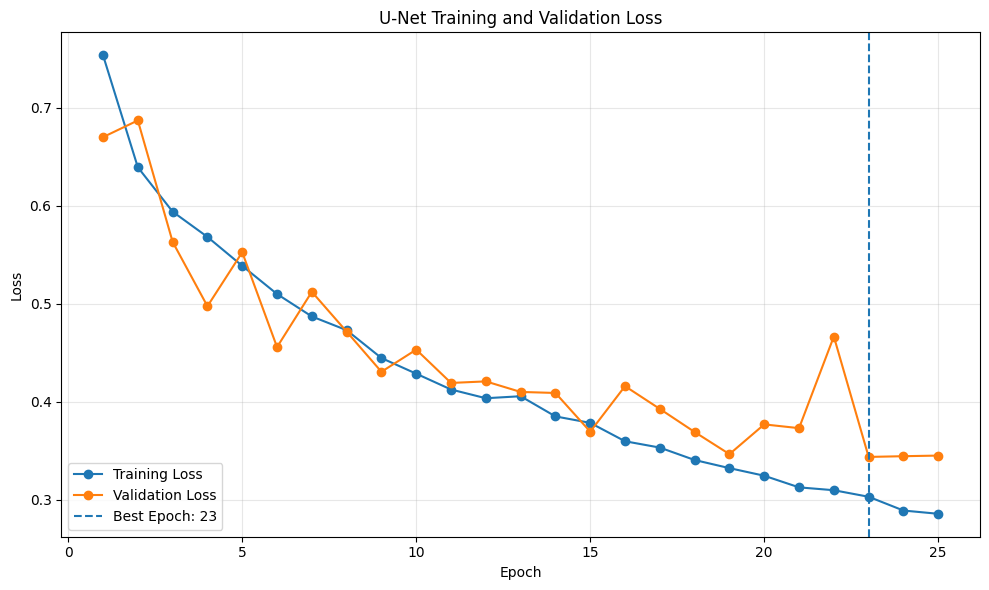

TRAINING ANALYSIS
--------------------------------
Total epochs: 25
Best epoch: 23
Best validation loss: 0.34369

Training graph saved at:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/logs/training_validation_loss.png

TRAINING GRAPH GENERATED!


In [ ]:

# ==========================================
# VISUALISE FINAL TRAINING PERFORMANCE
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Load training history
history_df = pd.read_csv(TRAINING_HISTORY_PATH)

# 2. Find the best epoch
best_index = history_df["validation_loss"].idxmin()

best_epoch = int(
    history_df.loc[best_index, "epoch"]
)

best_val_loss = history_df.loc[
    best_index, "validation_loss"
]

# 3. Plot training and validation loss
plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["validation_loss"],
    marker="o",
    label="Validation Loss"
)

# Mark the best epoch
plt.axvline(
    x=best_epoch,
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("U-Net Training and Validation Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# 4. Save the graph
GRAPH_PATH = LOG_DIR / "training_validation_loss.png"

plt.savefig(
    GRAPH_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Display summary
print("TRAINING ANALYSIS")
print("--------------------------------")

print("Total epochs:", len(history_df))
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 5))

print("\nTraining graph saved at:")
print(GRAPH_PATH)

print("\nTRAINING GRAPH GENERATED!")


In [ ]:

# ==================================================
# GLOBAL MODEL EVALUATION ON UNSEEN TEST DATA
# ==================================================

import torch
import numpy as np
import json

# 1. LOAD THE BEST CHECKPOINT (EPOCH 23)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best model loaded!")
print("Best epoch:", checkpoint["epoch"])


# 2. PREPARE CONFUSION MATRIX COUNTS

TP = 0  # Correctly predicted water
FP = 0  # Incorrectly predicted water
TN = 0  # Correctly predicted non-water
FN = 0  # Missed water pixels

THRESHOLD = 0.5


# 3. EVALUATE TEST DATASET

print("\nEvaluating unseen test images...")

with torch.inference_mode():

    for images, labels, masks in test_loader:

        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device).bool()

        # Predict flood probabilities
        logits = model(images)

        probabilities = torch.sigmoid(logits)

        predictions = probabilities >= THRESHOLD

        actual = labels >= 0.5

        # Evaluate ONLY valid pixels
        TP += torch.sum(
            predictions & actual & masks
        ).item()

        FP += torch.sum(
            predictions & (~actual) & masks
        ).item()

        TN += torch.sum(
            (~predictions) & (~actual) & masks
        ).item()

        FN += torch.sum(
            (~predictions) & actual & masks
        ).item()


# 4. CALCULATE METRICS

def safe_divide(a, b):
    return a / b if b != 0 else 0.0


total_pixels = TP + FP + TN + FN

precision = safe_divide(TP, TP + FP)

recall = safe_divide(TP, TP + FN)

dice = safe_divide(
    2 * TP,
    2 * TP + FP + FN
)

iou = safe_divide(
    TP,
    TP + FP + FN
)

accuracy = safe_divide(
    TP + TN,
    total_pixels
)

specificity = safe_divide(
    TN,
    TN + FP
)


# 5. DISPLAY RESULTS

print("\n================================")
print("GLOBAL MODEL TEST RESULTS")
print("================================")

print("Best checkpoint epoch:", checkpoint["epoch"])

print("\nCONFUSION MATRIX")
print("--------------------------------")
print("True Positives:", TP)
print("False Positives:", FP)
print("True Negatives:", TN)
print("False Negatives:", FN)

print("\nEVALUATION METRICS")
print("--------------------------------")

print("IoU:", round(iou, 5))
print("Dice:", round(dice, 5))
print("Precision:", round(precision, 5))
print("Recall:", round(recall, 5))
print("Accuracy:", round(accuracy, 5))
print("Specificity:", round(specificity, 5))

print("\nTotal valid pixels:", total_pixels)

print("\nPrediction threshold:", THRESHOLD)


# 6. SAVE RESULTS

test_results = {

    "checkpoint_epoch": int(checkpoint["epoch"]),
    "threshold": THRESHOLD,

    "true_positives": int(TP),
    "false_positives": int(FP),
    "true_negatives": int(TN),
    "false_negatives": int(FN),

    "iou": iou,
    "dice": dice,
    "precision": precision,
    "recall": recall,
    "accuracy": accuracy,
    "specificity": specificity,

    "total_valid_pixels": int(total_pixels)

}

METRICS_PATH = LOG_DIR / "global_test_metrics.json"

with open(METRICS_PATH, "w") as f:
    json.dump(test_results, f, indent=4)

print("\nResults saved at:")
print(METRICS_PATH)

print("\nGLOBAL MODEL EVALUATION COMPLETED!")


Best model loaded!
Best epoch: 23

Evaluating unseen test images...

GLOBAL MODEL TEST RESULTS
Best checkpoint epoch: 23

CONFUSION MATRIX
--------------------------------
True Positives: 1910481
False Positives: 390018
True Negatives: 17538933
False Negatives: 604527

EVALUATION METRICS
--------------------------------
IoU: 0.65765
Dice: 0.79347
Precision: 0.83046
Recall: 0.75963
Accuracy: 0.95135
Specificity: 0.97825

Total valid pixels: 20443959

Prediction threshold: 0.5

Results saved at:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/logs/global_test_metrics.json

GLOBAL MODEL EVALUATION COMPLETED!


In [ ]:

# ==========================================
# PER-IMAGE TEST PERFORMANCE ANALYSIS
# ==========================================

import torch
import numpy as np
import pandas as pd

# Load best checkpoint again
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

THRESHOLD = 0.5

image_results = []

sample_index = 0

print("CALCULATING PER-IMAGE METRICS...")

with torch.inference_mode():

    for images, labels, masks in test_loader:

        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device).bool()

        logits = model(images)

        predictions = (
            torch.sigmoid(logits) >= THRESHOLD
        )

        actual = labels >= 0.5

        for j in range(images.shape[0]):

            valid = masks[j]

            pred = predictions[j]
            target = actual[j]

            tp = (pred & target & valid).sum().item()
            fp = (pred & ~target & valid).sum().item()
            tn = (~pred & ~target & valid).sum().item()
            fn = (~pred & target & valid).sum().item()

            precision = (
                tp / (tp + fp)
                if tp + fp > 0 else np.nan
            )

            recall = (
                tp / (tp + fn)
                if tp + fn > 0 else np.nan
            )

            dice = (
                2 * tp / (2 * tp + fp + fn)
                if 2 * tp + fp + fn > 0 else np.nan
            )

            iou = (
                tp / (tp + fp + fn)
                if tp + fp + fn > 0 else np.nan
            )

            accuracy = (
                (tp + tn) / (tp + tn + fp + fn)
                if tp + tn + fp + fn > 0 else np.nan
            )

            filename = test_eval_df.iloc[
                sample_index
            ]["satellite_image"]

            image_results.append({

                "image": filename,
                "valid_pixels": tp + fp + tn + fn,
                "iou": iou,
                "dice": dice,
                "precision": precision,
                "recall": recall,
                "accuracy": accuracy

            })

            sample_index += 1


# Create results table
per_image_df = pd.DataFrame(image_results)

# Save results
PER_IMAGE_PATH = (
    LOG_DIR / "per_image_test_metrics.csv"
)

per_image_df.to_csv(
    PER_IMAGE_PATH,
    index=False
)


# Display macro averages
metric_columns = [
    "iou",
    "dice",
    "precision",
    "recall",
    "accuracy"
]

print("\nPER-IMAGE MACRO AVERAGES")
print("--------------------------------")

print(
    per_image_df[metric_columns]
    .mean()
    .round(5)
)

print("\nLOWEST 5 IMAGE IoU SCORES")

print(
    per_image_df
    .nsmallest(5, "iou")[
        ["image", "iou", "dice", "recall"]
    ].to_string(index=False)
)

print("\nHIGHEST 5 IMAGE IoU SCORES")

print(
    per_image_df
    .nlargest(5, "iou")[
        ["image", "iou", "dice", "recall"]
    ].to_string(index=False)
)

print("\nImages evaluated:", len(per_image_df))

print("\nResults saved at:")
print(PER_IMAGE_PATH)

print("\nPER-IMAGE EVALUATION COMPLETED!")


CALCULATING PER-IMAGE METRICS...

PER-IMAGE MACRO AVERAGES
--------------------------------
iou          0.41235
dice         0.51501
precision    0.60897
recall       0.55719
accuracy     0.94972
dtype: float64

LOWEST 5 IMAGE IoU SCORES
                     image  iou  dice  recall
    Ghana_97059_S1Hand.tif  0.0   0.0     NaN
    India_44475_S1Hand.tif  0.0   0.0     NaN
Pakistan_528249_S1Hand.tif  0.0   0.0     NaN
 Paraguay_40936_S1Hand.tif  0.0   0.0     NaN
 Paraguay_80102_S1Hand.tif  0.0   0.0     0.0

HIGHEST 5 IMAGE IoU SCORES
                      image      iou     dice   recall
Sri-Lanka_534068_S1Hand.tif 0.995804 0.997897 0.998974
Sri-Lanka_713926_S1Hand.tif 0.948319 0.973474 0.987616
      USA_905409_S1Hand.tif 0.935610 0.966734 0.950233
  Nigeria_812045_S1Hand.tif 0.917869 0.957176 0.961566
 Paraguay_790830_S1Hand.tif 0.916423 0.956389 0.969606

Images evaluated: 88

Results saved at:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/logs/per_image_test_metrics.csv


INVESTIGATING WORST-PERFORMING IMAGES
-------------------------------------

Image: Ghana_97059_S1Hand.tif
Actual water pixels: 0
Predicted water pixels: 372
Correct water pixels: 0

Image: India_44475_S1Hand.tif
Actual water pixels: 0
Predicted water pixels: 186
Correct water pixels: 0

Image: Pakistan_528249_S1Hand.tif
Actual water pixels: 0
Predicted water pixels: 364
Correct water pixels: 0

Image: Paraguay_40936_S1Hand.tif
Actual water pixels: 0
Predicted water pixels: 14281
Correct water pixels: 0

Image: Paraguay_80102_S1Hand.tif
Actual water pixels: 22
Predicted water pixels: 77
Correct water pixels: 0


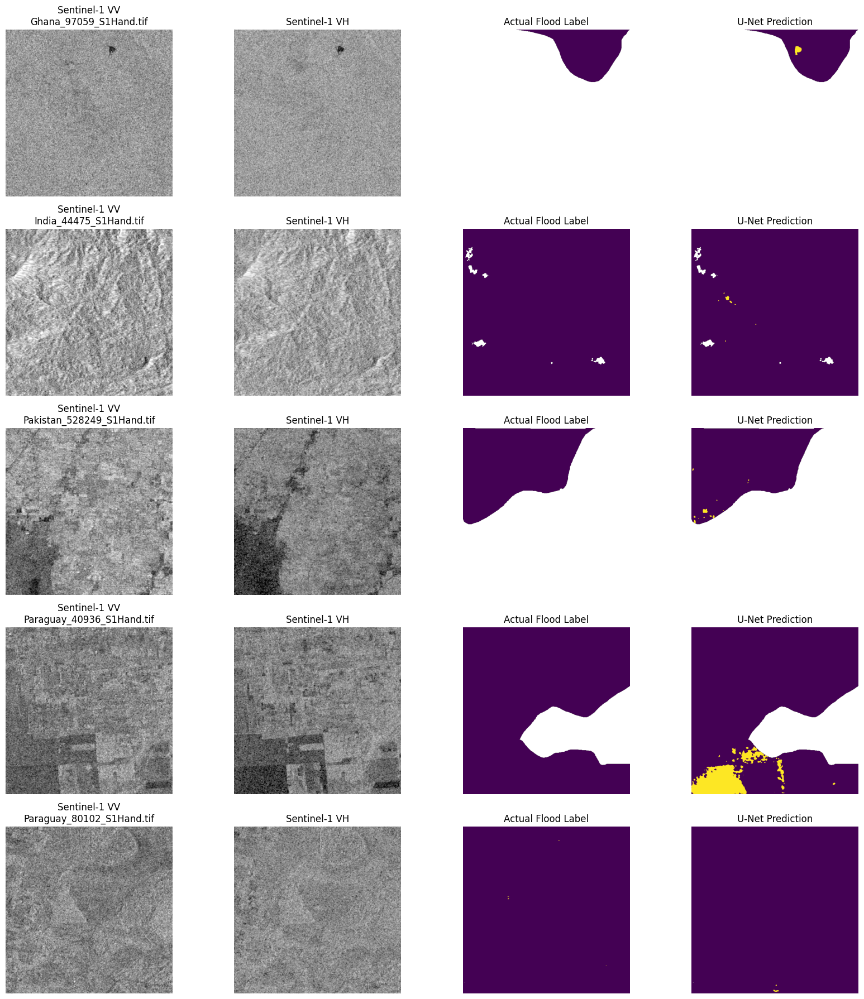


Error analysis saved at:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/logs/worst_five_images.png

VISUAL ERROR ANALYSIS COMPLETED!


In [ ]:

# ==========================================
# VISUAL ERROR ANALYSIS: FIVE WORST IMAGES
# ==========================================

import matplotlib.pyplot as plt
import numpy as np
import torch

# Get five images with the lowest IoU
worst_images = (
    per_image_df
    .nsmallest(5, "iou")["image"]
    .tolist()
)

model.eval()

fig, axes = plt.subplots(
    len(worst_images),
    4,
    figsize=(17, 18)
)

print("INVESTIGATING WORST-PERFORMING IMAGES")
print("-------------------------------------")

for row_idx, filename in enumerate(worst_images):

    # Find corresponding dataset index
    matches = test_eval_df.index[
        test_eval_df["satellite_image"].str.strip()
        == filename.strip()
    ]

    idx = int(matches[0])

    # Load image and ground truth
    image, label, mask = test_dataset[idx]

    vv = image[0].numpy()
    vh = image[1].numpy()

    actual = label[0].numpy()
    valid = mask[0].numpy().astype(bool)

    # Predict
    with torch.inference_mode():

        logits = model(
            image.unsqueeze(0).to(device)
        )

        probability = torch.sigmoid(logits)[0, 0]
        probability = probability.cpu().numpy()

    predicted = (probability >= 0.5)

    # Calculate pixel counts
    gt_water = int(((actual >= 0.5) & valid).sum())
    pred_water = int((predicted & valid).sum())

    tp = int(
        (predicted & (actual >= 0.5) & valid).sum()
    )

    print("\nImage:", filename)
    print("Actual water pixels:", gt_water)
    print("Predicted water pixels:", pred_water)
    print("Correct water pixels:", tp)

    # Mask invalid label pixels
    actual_display = np.where(valid, actual, np.nan)

    predicted_display = np.where(
        valid,
        predicted.astype(float),
        np.nan
    )

    # Plot all four panels
    panels = [
        (vv, "gray", "Sentinel-1 VV", None),
        (vh, "gray", "Sentinel-1 VH", None),
        (actual_display, "viridis", "Actual Flood Label", 1),
        (predicted_display, "viridis", "U-Net Prediction", 1)
    ]

    for col, (data, cmap, title, vmax) in enumerate(panels):

        ax = axes[row_idx, col]

        ax.imshow(
            data,
            cmap=cmap,
            vmin=0 if vmax else -3,
            vmax=vmax if vmax else 3
        )

        ax.set_title(
            f"{title}\n{filename}" if col == 0
            else title
        )

        ax.axis("off")

plt.tight_layout()

ERROR_GRAPH_PATH = LOG_DIR / "worst_five_images.png"

plt.savefig(
    ERROR_GRAPH_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nError analysis saved at:")
print(ERROR_GRAPH_PATH)

print("\nVISUAL ERROR ANALYSIS COMPLETED!")


In [ ]:

# ==========================================
# COMPLETE TEST SET ERROR AUDIT
# ==========================================

import torch
import numpy as np
import pandas as pd

THRESHOLD = 0.5

audit_results = []
sample_index = 0

model.eval()

print("AUDITING ALL TEST IMAGES...")

with torch.inference_mode():

    for images, labels, masks in test_loader:

        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device).bool()

        logits = model(images)
        predictions = torch.sigmoid(logits) >= THRESHOLD
        actual = labels >= 0.5

        for j in range(images.shape[0]):

            valid = masks[j]
            pred = predictions[j]
            target = actual[j]

            tp = int((pred & target & valid).sum().item())
            fp = int((pred & ~target & valid).sum().item())
            tn = int((~pred & ~target & valid).sum().item())
            fn = int((~pred & target & valid).sum().item())

            valid_pixels = tp + fp + tn + fn
            gt_water = tp + fn
            pred_water = tp + fp

            union = tp + fp + fn

            iou = tp / union if union > 0 else np.nan

            dice_denominator = 2 * tp + fp + fn

            dice = (
                2 * tp / dice_denominator
                if dice_denominator > 0 else np.nan
            )

            filename = test_eval_df.iloc[
                sample_index
            ]["satellite_image"]

            audit_results.append({

                "image": filename,
                "valid_pixels": valid_pixels,
                "actual_water_pixels": gt_water,
                "predicted_water_pixels": pred_water,
                "TP": tp,
                "FP": fp,
                "TN": tn,
                "FN": fn,
                "IoU": iou,
                "Dice": dice

            })

            sample_index += 1


# Create complete audit table
audit_df = pd.DataFrame(audit_results)

# Divide images based on actual labelled water
flood_images = audit_df[
    audit_df["actual_water_pixels"] > 0
]

no_flood_images = audit_df[
    audit_df["actual_water_pixels"] == 0
]

print("\n================================")
print("TEST DATASET ERROR AUDIT")
print("================================")

print("Total images:", len(audit_df))

print("\nIMAGES WITH LABELLED WATER")
print("------------------------------")

print("Number of images:", len(flood_images))

print(
    "Mean IoU:",
    round(flood_images["IoU"].mean(), 5)
)

print(
    "Mean Dice:",
    round(flood_images["Dice"].mean(), 5)
)

print(
    "Mean recall:",
    round(
        (
            flood_images["TP"].sum()
            / flood_images["actual_water_pixels"].sum()
        ), 5
    )
)

print("\nIMAGES WITHOUT LABELLED WATER")
print("------------------------------")

print("Number of images:", len(no_flood_images))

print(
    "Images with false alarms:",
    int((no_flood_images["FP"] > 0).sum())
)

print(
    "Total false-positive pixels:",
    int(no_flood_images["FP"].sum())
)

print(
    "Total predicted water pixels:",
    int(no_flood_images["predicted_water_pixels"].sum())
)

print("\nLARGEST FALSE ALARMS")
print("------------------------------")

print(
    audit_df.nlargest(10, "FP")[
        ["image", "actual_water_pixels",
         "predicted_water_pixels", "FP", "IoU"]
    ].to_string(index=False)
)

print("\nWORST FLOOD-POSITIVE IMAGES")
print("------------------------------")

print(
    flood_images.nsmallest(10, "IoU")[
        ["image", "actual_water_pixels",
         "predicted_water_pixels", "IoU", "Dice"]
    ].to_string(index=False)
)


# Save complete audit
AUDIT_PATH = LOG_DIR / "test_error_audit.csv"

audit_df.to_csv(AUDIT_PATH, index=False)

print("\nAudit saved at:")
print(AUDIT_PATH)

print("\nTEST ERROR AUDIT COMPLETED!")


AUDITING ALL TEST IMAGES...

TEST DATASET ERROR AUDIT
Total images: 88

IMAGES WITH LABELLED WATER
------------------------------
Number of images: 82
Mean IoU: 0.43247
Mean Dice: 0.54013
Mean recall: 0.75963

IMAGES WITHOUT LABELLED WATER
------------------------------
Number of images: 6
Images with false alarms: 4
Total false-positive pixels: 15203
Total predicted water pixels: 15203

LARGEST FALSE ALARMS
------------------------------
                      image  actual_water_pixels  predicted_water_pixels    FP      IoU
 Paraguay_232281_S1Hand.tif                29404                   55110 33420 0.345250
      USA_595451_S1Hand.tif                20531                   44435 27939 0.340334
 Paraguay_271769_S1Hand.tif                 2613                   29727 27542 0.072459
    India_399883_S1Hand.tif               136292                  151773 26102 0.773865
Sri-Lanka_117737_S1Hand.tif                 6731                   20620 18023 0.104912
    India_900498_S1Hand.tif  

In [ ]:

# ==========================================
# LOCATE AMPHAN GOOGLE EARTH ENGINE EXPORTS
# ==========================================

from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

search_terms = [
    "amphan",
    "pre_event",
    "post_event"
]

matches = []

print("SEARCHING GOOGLE DRIVE FOR GEE EXPORTS...")
print("------------------------------------------")

for path in drive_root.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in [".tif", ".tiff"]:
        continue

    filename = path.name.lower()

    if any(term in filename for term in search_terms):
        matches.append(path)

if matches:

    print("\nFOUND SATELLITE EXPORTS:\n")

    for path in matches:

        print("Filename:", path.name)
        print("Location:", path)
        print("Size (MB):", round(path.stat().st_size / (1024**2), 2))
        print("------------------------------------------")

else:

    print("\nNo matching TIFF files found.")

print("\nSEARCH COMPLETED!")


SEARCHING GOOGLE DRIVE FOR GEE EXPORTS...
------------------------------------------

FOUND SATELLITE EXPORTS:

Filename: Amphan_Post_Event.tif
Location: /content/drive/MyDrive/GEE_Flood_Project/Amphan_Post_Event.tif
Size (MB): 572.6
------------------------------------------
Filename: test_pre_event_s1.tif
Location: /content/drive/MyDrive/FloodProject/test_pre_event_s1.tif
Size (MB): 21.31
------------------------------------------
Filename: test_post_event_s1.tif
Location: /content/drive/MyDrive/FloodProject/test_post_event_s1.tif
Size (MB): 21.33
------------------------------------------

SEARCH COMPLETED!


In [ ]:

# ==========================================
# INSPECT AMPHAN SATELLITE TIFF EXPORTS
# ==========================================

import rasterio
import numpy as np
from pathlib import Path

files = {
    "Amphan full post-event":
        Path("/content/drive/MyDrive/GEE_Flood_Project/Amphan_Post_Event.tif"),

    "Test pre-event":
        Path("/content/drive/MyDrive/FloodProject/test_pre_event_s1.tif"),

    "Test post-event":
        Path("/content/drive/MyDrive/FloodProject/test_post_event_s1.tif")
}

print("AMPHAN TIFF METADATA INSPECTION")
print("=" * 55)

for name, path in files.items():

    print("\nFILE:", name)
    print("-" * 55)

    if not path.exists():
        print("FILE NOT FOUND:", path)
        continue

    with rasterio.open(path) as src:

        print("Filename:", path.name)

        print("Width:", src.width)
        print("Height:", src.height)

        print("Number of bands:", src.count)

        print("CRS:", src.crs)

        print("Resolution:", src.res)

        print("Bounds:", src.bounds)

        print("No-data value:", src.nodata)

        print("Data types:", src.dtypes)

        print("Band descriptions:", src.descriptions)

        # Read a small sample, not the full image
        sample = src.read(
            out_shape=(
                src.count,
                min(512, src.height),
                min(512, src.width)
            )
        )

        print("\nBAND STATISTICS (SAMPLED)")

        for band_index in range(src.count):

            band = sample[band_index]

            finite = band[np.isfinite(band)]

            print(f"\nBand {band_index + 1}")

            if len(finite) > 0:

                print("Minimum:", float(finite.min()))
                print("Maximum:", float(finite.max()))
                print("Mean:", float(finite.mean()))

                print(
                    "Invalid sampled pixels:",
                    int((~np.isfinite(band)).sum())
                )

            else:

                print("No finite values found!")

print("\nTIFF INSPECTION COMPLETED!")


AMPHAN TIFF METADATA INSPECTION

FILE: Amphan full post-event
-------------------------------------------------------
Filename: Amphan_Post_Event.tif
Width: 5567
Height: 5569
Number of bands: 2
CRS: EPSG:4326
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Bounds: BoundingBox(left=88.49995566630179, bottom=21.599991006653894, right=89.00004778497113, top=22.100262788380057)
No-data value: None
Data types: ('float64', 'float64')
Band descriptions: ('VV', 'VH')

BAND STATISTICS (SAMPLED)

Band 1
Minimum: -29.469425175452596
Maximum: 12.339550419824091
Mean: -12.41561453256923
Invalid sampled pixels: 0

Band 2
Minimum: -42.13897406461122
Maximum: -3.5097490316633797
Mean: -19.599041675857123
Invalid sampled pixels: 0

FILE: Test pre-event
-------------------------------------------------------
Filename: test_pre_event_s1.tif
Width: 1047
Height: 1120
Number of bands: 2
CRS: EPSG:32645
Resolution: (10.0, 10.0)
Bounds: BoundingBox(left=675610.0, bottom=2411650.0, right=686080.0, t

In [ ]:

# ==========================================
# COMPLETE AMPHAN DATA QUALITY AND ALIGNMENT
# ==========================================

import rasterio
import numpy as np

from pathlib import Path
from rasterio.warp import transform_bounds

# 1. File locations

large_path = Path(
    "/content/drive/MyDrive/GEE_Flood_Project/Amphan_Post_Event.tif"
)

pre_path = Path(
    "/content/drive/MyDrive/FloodProject/test_pre_event_s1.tif"
)

post_path = Path(
    "/content/drive/MyDrive/FloodProject/test_post_event_s1.tif"
)

paths = {
    "Large Amphan post-event": large_path,
    "Pre-event": pre_path,
    "Post-event": post_path
}

# 2. Verify files exist

for name, path in paths.items():
    if not path.exists():
        raise FileNotFoundError(f"{name} not found: {path}")

# 3. Calculate exact full-image statistics

def inspect_full_image(name, path):

    total_pixels = 0
    valid_per_band = [0, 0]
    sums = [0.0, 0.0]
    minima = [float("inf"), float("inf")]
    maxima = [float("-inf"), float("-inf")]

    with rasterio.open(path) as src:

        total_pixels = src.width * src.height

        for _, window in src.block_windows(1):

            data = src.read(window=window)

            for b in range(2):

                band = data[b]
                finite = band[np.isfinite(band)]

                valid_per_band[b] += len(finite)

                if len(finite) > 0:

                    sums[b] += float(finite.sum())

                    minima[b] = min(
                        minima[b],
                        float(finite.min())
                    )

                    maxima[b] = max(
                        maxima[b],
                        float(finite.max())
                    )

        common_valid = 0

        # Count pixels where BOTH VV and VH are finite
        for _, window in src.block_windows(1):

            data = src.read(window=window)

            common_valid += int(
                (
                    np.isfinite(data[0]) &
                    np.isfinite(data[1])
                ).sum()
            )

        print("\n", name)
        print("-" * 45)

        print("Dimensions:", src.width, "x", src.height)
        print("CRS:", src.crs)
        print("Resolution:", src.res)

        for b, band_name in enumerate(["VV", "VH"]):

            print(f"\n{band_name}:")

            print("Valid pixels:", valid_per_band[b])
            print("Invalid pixels:", total_pixels - valid_per_band[b])

            print(
                "Mean:",
                sums[b] / valid_per_band[b]
                if valid_per_band[b] else np.nan
            )

            print("Minimum:", minima[b])
            print("Maximum:", maxima[b])

        print("\nCommon VV+VH valid pixels:", common_valid)
        print("Common invalid pixels:", total_pixels - common_valid)

        print("\nTIFF tags:", src.tags())

# 4. Inspect all three images

print("FULL-IMAGE DATA QUALITY CHECK")
print("=" * 55)

for name, path in paths.items():
    inspect_full_image(name, path)

# 5. Verify pre-event and post-event alignment

with rasterio.open(pre_path) as pre, \
     rasterio.open(post_path) as post:

    print("\nPRE/POST SPATIAL ALIGNMENT")
    print("=" * 55)

    print("Same dimensions:",
          pre.width == post.width and
          pre.height == post.height)

    print("Same CRS:", pre.crs == post.crs)

    print("Same transform:", pre.transform == post.transform)

    print("Same bounds:", pre.bounds == post.bounds)

    perfectly_aligned = (
        pre.width == post.width and
        pre.height == post.height and
        pre.crs == post.crs and
        pre.transform == post.transform
    )

    print("\nPre/post grids aligned:", perfectly_aligned)

# 6. Check whether smaller area lies inside large export

with rasterio.open(large_path) as large, \
     rasterio.open(post_path) as small:

    small_bounds = transform_bounds(
        small.crs,
        large.crs,
        *small.bounds,
        densify_pts=21
    )

    large_bounds = large.bounds

    contained = (
        small_bounds[0] >= large_bounds.left and
        small_bounds[1] >= large_bounds.bottom and
        small_bounds[2] <= large_bounds.right and
        small_bounds[3] <= large_bounds.top
    )

    print("\nGEOGRAPHICAL COVERAGE")
    print("=" * 55)

    print("Small image bounds in large-image CRS:")
    print(small_bounds)

    print("\nLarge image bounds:")
    print(large_bounds)

    print("\nSmaller area entirely inside large export:", contained)

print("\nAMPHAN DATA AUDIT COMPLETED!")


FULL-IMAGE DATA QUALITY CHECK

 Large Amphan post-event
---------------------------------------------
Dimensions: 5567 x 5569
CRS: EPSG:4326
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)

VV:
Valid pixels: 30990643
Invalid pixels: 11980
Mean: -12.41639303910761
Minimum: -31.655721029012373
Maximum: 19.53252841222354

VH:
Valid pixels: 30990643
Invalid pixels: 11980
Mean: -19.599323291267307
Minimum: -45.84621227967473
Maximum: 7.866227268504385

Common VV+VH valid pixels: 30990643
Common invalid pixels: 11980

TIFF tags: {'AREA_OR_POINT': 'Area'}

 Pre-event
---------------------------------------------
Dimensions: 1047 x 1120
CRS: EPSG:32645
Resolution: (10.0, 10.0)

VV:
Valid pixels: 1146638
Invalid pixels: 26002
Mean: -11.15958861889667
Minimum: -31.49023053500399
Maximum: -0.5740685225069562

VH:
Valid pixels: 1146638
Invalid pixels: 26002
Mean: -16.908931855718016
Minimum: -39.64949703719605
Maximum: -7.442502267720233

Common VV+VH valid pixels: 1146638
Common invali

COMMON VALID PIXELS: 1146638


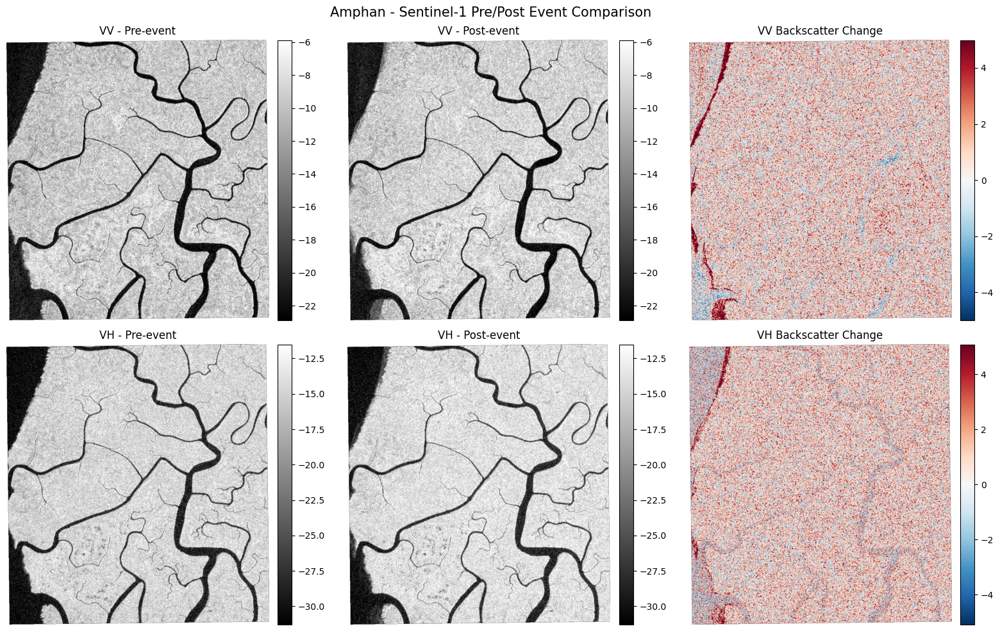


Comparison saved at:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/logs/amphan_pre_post_comparison.png

AMPHAN VISUAL COMPARISON COMPLETED!


In [ ]:

# ==========================================
# VISUAL COMPARISON: AMPHAN PRE AND POST EVENT
# ==========================================

import rasterio
import numpy as np
import matplotlib.pyplot as plt

# 1. Read both images

with rasterio.open(pre_path) as src:
    pre = src.read().astype(np.float32)

with rasterio.open(post_path) as src:
    post = src.read().astype(np.float32)


# 2. Create common valid-data mask

valid = (
    np.isfinite(pre[0]) &
    np.isfinite(pre[1]) &
    np.isfinite(post[0]) &
    np.isfinite(post[1])
)

print("COMMON VALID PIXELS:", int(valid.sum()))

# 3. Calculate backscatter differences

vv_change = np.where(
    valid,
    post[0] - pre[0],
    np.nan
)

vh_change = np.where(
    valid,
    post[1] - pre[1],
    np.nan
)

# 4. Shared display ranges for fair comparison

def get_limits(a, b):

    combined = np.concatenate([
        a[valid],
        b[valid]
    ])

    return np.percentile(combined, [2, 98])


vv_min, vv_max = get_limits(pre[0], post[0])
vh_min, vh_max = get_limits(pre[1], post[1])

vv_diff_limit = np.nanpercentile(
    np.abs(vv_change), 98
)

vh_diff_limit = np.nanpercentile(
    np.abs(vh_change), 98
)

# 5. Plot comparison

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

plots = [

    (pre[0], "VV - Pre-event", "gray", vv_min, vv_max),
    (post[0], "VV - Post-event", "gray", vv_min, vv_max),
    (vv_change, "VV Backscatter Change", "RdBu_r",
     -vv_diff_limit, vv_diff_limit),

    (pre[1], "VH - Pre-event", "gray", vh_min, vh_max),
    (post[1], "VH - Post-event", "gray", vh_min, vh_max),
    (vh_change, "VH Backscatter Change", "RdBu_r",
     -vh_diff_limit, vh_diff_limit)

]

for ax, (data, title, cmap, vmin, vmax) in zip(
    axes.flat, plots
):

    displayed = np.where(valid, data, np.nan)

    im = ax.imshow(
        displayed,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(title)
    ax.axis("off")

    fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.03
    )

plt.suptitle(
    "Amphan - Sentinel-1 Pre/Post Event Comparison",
    fontsize=15
)

plt.tight_layout()

COMPARISON_PATH = (
    LOG_DIR / "amphan_pre_post_comparison.png"
)

plt.savefig(
    COMPARISON_PATH,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("\nComparison saved at:")
print(COMPARISON_PATH)

print("\nAMPHAN VISUAL COMPARISON COMPLETED!")


BEST GLOBAL MODEL LOADED
Checkpoint epoch: 23

SATELLITE IMAGE
-----------------------------
Dimensions: 1120 x 1047
Channels: 2
CRS: EPSG:32645

Valid pixels: 1146638
Invalid pixels: 26002

TILES TO PROCESS: 9

STARTING ZERO-SHOT INFERENCE...

AMPHAN ZERO-SHOT RESULTS
--------------------------------
Valid pixels: 1146638
Predicted water pixels: 176285
Predicted water percentage: 15.374 %
Prediction threshold: 0.5


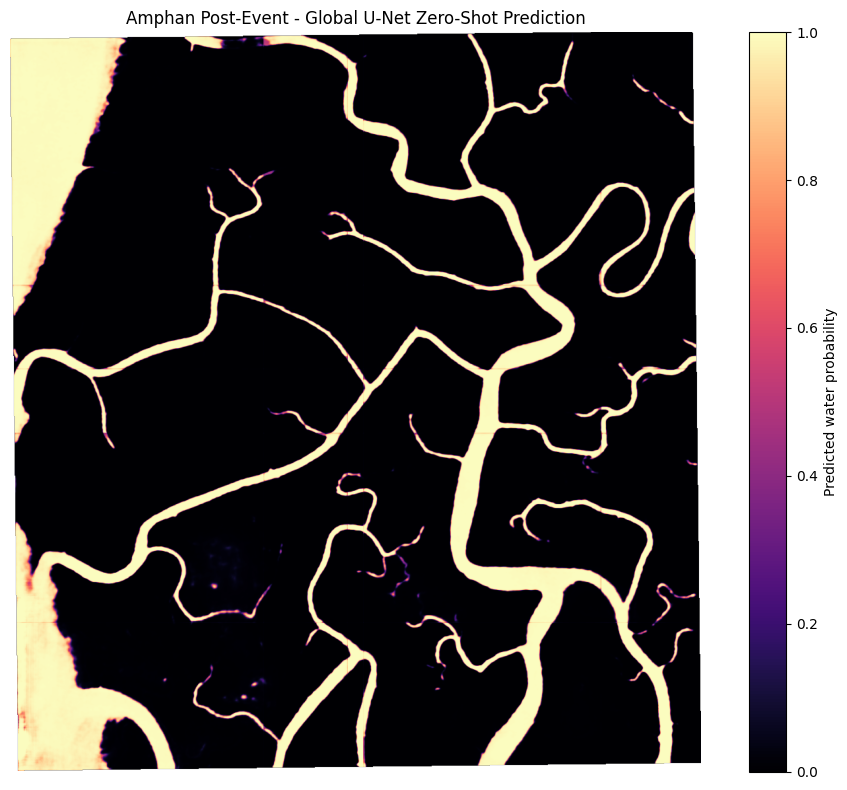


AMPHAN ZERO-SHOT INFERENCE COMPLETED!

Probability GeoTIFF:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_zero_shot/amphan_post_probability.tif

Binary prediction GeoTIFF:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_zero_shot/amphan_post_prediction.tif

Preview:
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_zero_shot/amphan_post_probability.png


In [ ]:

# ============================================================
# AMPHAN ZERO-SHOT FLOOD PREDICTION
# GLOBAL U-NET - EPOCH 23 CHECKPOINT
# ============================================================

import rasterio
import numpy as np
import torch
import matplotlib.pyplot as plt

from pathlib import Path


# 1. INPUT AND OUTPUT PATHS

POST_PATH = Path(
    "/content/drive/MyDrive/FloodProject/test_post_event_s1.tif"
)

RESULT_DIR = (
    PROJECT_DIR / "results" / "amphan_zero_shot"
)

RESULT_DIR.mkdir(parents=True, exist_ok=True)


# 2. ORIGINAL TRAINING NORMALIZATION VALUES
# Channel order: VV, VH

TRAIN_MEAN = np.array(
    [-10.392862, -17.241102],
    dtype=np.float32
)

TRAIN_STD = np.array(
    [4.038801, 4.753971],
    dtype=np.float32
)


# 3. LOAD BEST TRAINED MODEL

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("BEST GLOBAL MODEL LOADED")
print("Checkpoint epoch:", checkpoint["epoch"])


# 4. LOAD POST-EVENT SATELLITE IMAGE

with rasterio.open(POST_PATH) as src:

    satellite = src.read().astype(np.float32)

    profile = src.profile.copy()

    transform = src.transform
    crs = src.crs

height, width = satellite.shape[1:]

print("\nSATELLITE IMAGE")
print("-----------------------------")

print("Dimensions:", height, "x", width)
print("Channels:", satellite.shape[0])
print("CRS:", crs)


# 5. CREATE COMMON VALIDITY MASK

valid = np.isfinite(satellite).all(axis=0)

print("\nValid pixels:", int(valid.sum()))
print("Invalid pixels:", int((~valid).sum()))


# 6. NORMALIZE USING TRAINING STATISTICS

# Replace missing values with their training mean.
# After normalization, these positions become zero.

filled = np.where(
    valid[np.newaxis, :, :],
    satellite,
    TRAIN_MEAN[:, np.newaxis, np.newaxis]
)

normalized = (
    filled - TRAIN_MEAN[:, np.newaxis, np.newaxis]
) / TRAIN_STD[:, np.newaxis, np.newaxis]


# 7. PREPARE OVERLAPPING TILES

TILE_SIZE = 512
STRIDE = 384

def tile_positions(length):

    positions = list(
        range(
            0,
            max(length - TILE_SIZE + 1, 1),
            STRIDE
        )
    )

    final_position = length - TILE_SIZE

    if positions[-1] != final_position:
        positions.append(final_position)

    return positions


y_positions = tile_positions(height)
x_positions = tile_positions(width)

print("\nTILES TO PROCESS:",
      len(y_positions) * len(x_positions))


# 8. RUN ZERO-SHOT INFERENCE

probability_sum = np.zeros(
    (height, width),
    dtype=np.float32
)

overlap_count = np.zeros(
    (height, width),
    dtype=np.uint16
)

print("\nSTARTING ZERO-SHOT INFERENCE...")

model.eval()

with torch.inference_mode():

    for y in y_positions:

        for x in x_positions:

            tile = normalized[
                :,
                y:y + TILE_SIZE,
                x:x + TILE_SIZE
            ]

            tile_tensor = torch.from_numpy(
                np.ascontiguousarray(tile)
            ).unsqueeze(0).to(device)

            logits = model(tile_tensor)

            probabilities = torch.sigmoid(
                logits
            )[0, 0].float().cpu().numpy()

            probability_sum[
                y:y + TILE_SIZE,
                x:x + TILE_SIZE
            ] += probabilities

            overlap_count[
                y:y + TILE_SIZE,
                x:x + TILE_SIZE
            ] += 1


# 9. MERGE OVERLAPPING PREDICTIONS

if np.any(overlap_count == 0):
    raise RuntimeError("Some image pixels were not processed.")

probability = (
    probability_sum /
    overlap_count.astype(np.float32)
)

# Invalid pixels must not be interpreted as water.
probability[~valid] = np.nan

THRESHOLD = 0.5

binary_prediction = (
    probability >= THRESHOLD
).astype(np.uint8)

# Use 255 as nodata in the binary output.
binary_prediction[~valid] = 255


# 10. CALCULATE BASIC PREDICTION STATISTICS

predicted_water = int(
    ((binary_prediction == 1) & valid).sum()
)

valid_count = int(valid.sum())

water_percentage = (
    100 * predicted_water / valid_count
    if valid_count > 0 else 0
)

print("\nAMPHAN ZERO-SHOT RESULTS")
print("--------------------------------")

print("Valid pixels:", valid_count)
print("Predicted water pixels:", predicted_water)

print(
    "Predicted water percentage:",
    round(water_percentage, 3),
    "%"
)

print("Prediction threshold:", THRESHOLD)


# 11. SAVE PROBABILITY GEOTIFF

probability_path = (
    RESULT_DIR / "amphan_post_probability.tif"
)

prob_profile = profile.copy()

prob_profile.update(
    count=1,
    dtype="float32",
    nodata=-9999.0,
    compress="deflate"
)

with rasterio.open(
    probability_path,
    "w",
    **prob_profile
) as dst:

    dst.write(
        np.where(
            valid,
            probability,
            -9999.0
        ).astype(np.float32),
        1
    )


# 12. SAVE BINARY PREDICTION GEOTIFF

binary_path = (
    RESULT_DIR / "amphan_post_prediction.tif"
)

binary_profile = profile.copy()

binary_profile.update(
    count=1,
    dtype="uint8",
    nodata=255,
    compress="deflate"
)

with rasterio.open(
    binary_path,
    "w",
    **binary_profile
) as dst:

    dst.write(
        binary_prediction,
        1
    )


# 13. CREATE VISUALIZATION

plt.figure(figsize=(10, 8))

plt.imshow(
    np.ma.masked_invalid(probability),
    cmap="magma",
    vmin=0,
    vmax=1
)

plt.colorbar(
    label="Predicted water probability"
)

plt.title(
    "Amphan Post-Event - Global U-Net Zero-Shot Prediction"
)

plt.axis("off")
plt.tight_layout()

preview_path = (
    RESULT_DIR / "amphan_post_probability.png"
)

plt.savefig(
    preview_path,
    dpi=250,
    bbox_inches="tight"
)

plt.show()


# 14. FINAL OUTPUT

print("\n========================================")
print("AMPHAN ZERO-SHOT INFERENCE COMPLETED!")
print("========================================")

print("\nProbability GeoTIFF:")
print(probability_path)

print("\nBinary prediction GeoTIFF:")
print(binary_path)

print("\nPreview:")
print(preview_path)


Best checkpoint epoch: 23

Pre-event image: 1047 x 1120
Valid pixels: 1146638

Running pre-event inference...

AMPHAN PRE/POST MODEL COMPARISON
Common valid pixels: 1146638
Pre-event predicted water: 16.037 %
Post-event predicted water: 15.374 %
Pixels with probability increase >= 0.25: 1826
Pixels with probability decrease <= -0.25: 12667
Mean probability change: -0.00695


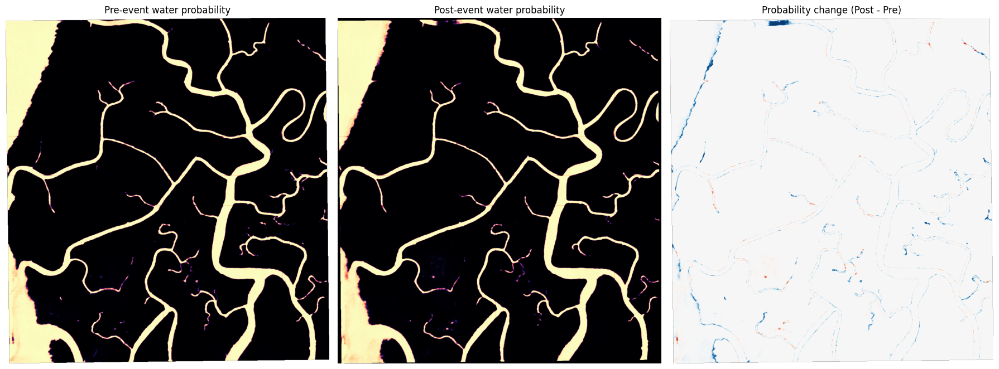


Pre-event prediction saved: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_zero_shot/amphan_pre_probability.tif
Change map saved: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_zero_shot/amphan_probability_change.tif
Comparison saved: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_zero_shot/amphan_zero_shot_comparison.png

PRE/POST ZERO-SHOT COMPARISON COMPLETED!


In [ ]:

# ============================================================
# AMPHAN PRE-EVENT ZERO-SHOT INFERENCE
# AND PRE/POST PROBABILITY COMPARISON
# ============================================================

import rasterio
import numpy as np
import torch
import matplotlib.pyplot as plt

from pathlib import Path

# 1. FILE PATHS

PRE_PATH = Path(
    "/content/drive/MyDrive/FloodProject/test_pre_event_s1.tif"
)

POST_PROB_PATH = (
    RESULT_DIR / "amphan_post_probability.tif"
)

PRE_PROB_PATH = (
    RESULT_DIR / "amphan_pre_probability.tif"
)

CHANGE_PATH = (
    RESULT_DIR / "amphan_probability_change.tif"
)

# 2. TRAINING NORMALIZATION VALUES

TRAIN_MEAN = np.array(
    [-10.392862, -17.241102],
    dtype=np.float32
)

TRAIN_STD = np.array(
    [4.038801, 4.753971],
    dtype=np.float32
)

# 3. LOAD BEST MODEL

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best checkpoint epoch:", checkpoint["epoch"])


# 4. LOAD PRE-EVENT IMAGE

with rasterio.open(PRE_PATH) as src:

    pre_image = src.read().astype(np.float32)
    profile = src.profile.copy()

height, width = pre_image.shape[1:]

valid = np.isfinite(pre_image).all(axis=0)

print("\nPre-event image:", width, "x", height)
print("Valid pixels:", int(valid.sum()))


# 5. APPLY ORIGINAL TRAINING NORMALIZATION

filled = np.where(
    valid[np.newaxis, :, :],
    pre_image,
    TRAIN_MEAN[:, np.newaxis, np.newaxis]
)

normalized = (
    filled - TRAIN_MEAN[:, np.newaxis, np.newaxis]
) / TRAIN_STD[:, np.newaxis, np.newaxis]


# 6. CREATE TILE POSITIONS

TILE_SIZE = 512
STRIDE = 384

def get_positions(length):

    positions = list(
        range(
            0,
            max(length - TILE_SIZE + 1, 1),
            STRIDE
        )
    )

    last = length - TILE_SIZE

    if positions[-1] != last:
        positions.append(last)

    return positions


ys = get_positions(height)
xs = get_positions(width)

# 7. RUN PRE-EVENT INFERENCE

prob_sum = np.zeros(
    (height, width),
    dtype=np.float32
)

overlap = np.zeros(
    (height, width),
    dtype=np.uint16
)

print("\nRunning pre-event inference...")

with torch.inference_mode():

    for y in ys:

        for x in xs:

            tile = normalized[
                :,
                y:y + TILE_SIZE,
                x:x + TILE_SIZE
            ]

            tensor = torch.from_numpy(
                np.ascontiguousarray(tile)
            ).unsqueeze(0).to(device)

            logits = model(tensor)

            prob = torch.sigmoid(
                logits
            )[0, 0].float().cpu().numpy()

            prob_sum[
                y:y + TILE_SIZE,
                x:x + TILE_SIZE
            ] += prob

            overlap[
                y:y + TILE_SIZE,
                x:x + TILE_SIZE
            ] += 1


# 8. MERGE TILE PREDICTIONS

if np.any(overlap == 0):
    raise RuntimeError("Unprocessed image pixels detected.")

pre_probability = prob_sum / overlap.astype(np.float32)

pre_probability[~valid] = np.nan


# 9. SAVE PRE-EVENT PROBABILITY MAP

prob_profile = profile.copy()

prob_profile.update(
    count=1,
    dtype="float32",
    nodata=-9999.0,
    compress="deflate"
)

with rasterio.open(
    PRE_PROB_PATH,
    "w",
    **prob_profile
) as dst:

    dst.write(
        np.where(
            valid,
            pre_probability,
            -9999.0
        ).astype(np.float32),
        1
    )


# 10. LOAD EXISTING POST-EVENT PROBABILITY MAP

with rasterio.open(POST_PROB_PATH) as src:

    post_probability = src.read(1)

    post_valid = (
        np.isfinite(post_probability) &
        (post_probability != -9999.0)
    )

    post_transform = src.transform
    post_crs = src.crs


# 11. VERIFY GRID ALIGNMENT

with rasterio.open(PRE_PATH) as src:

    assert src.transform == post_transform
    assert src.crs == post_crs

assert pre_probability.shape == post_probability.shape

common_valid = valid & post_valid

if common_valid.sum() == 0:
    raise RuntimeError("No common valid pixels.")


# 12. CALCULATE POST-MINUS-PRE CHANGE

change = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

change[common_valid] = (
    post_probability[common_valid] -
    pre_probability[common_valid]
)


# 13. SAVE CHANGE MAP

change_profile = prob_profile.copy()

with rasterio.open(
    CHANGE_PATH,
    "w",
    **change_profile
) as dst:

    dst.write(
        np.where(
            common_valid,
            change,
            -9999.0
        ).astype(np.float32),
        1
    )


# 14. CALCULATE SUMMARY STATISTICS

THRESHOLD = 0.5

pre_water = (
    (pre_probability >= THRESHOLD) & common_valid
)

post_water = (
    (post_probability >= THRESHOLD) & common_valid
)

water_increase = (
    (change >= 0.25) & common_valid
)

water_decrease = (
    (change <= -0.25) & common_valid
)

n = int(common_valid.sum())

print("\n========================================")
print("AMPHAN PRE/POST MODEL COMPARISON")
print("========================================")

print("Common valid pixels:", n)

print(
    "Pre-event predicted water:",
    round(100 * pre_water.sum() / n, 3), "%"
)

print(
    "Post-event predicted water:",
    round(100 * post_water.sum() / n, 3), "%"
)

print(
    "Pixels with probability increase >= 0.25:",
    int(water_increase.sum())
)

print(
    "Pixels with probability decrease <= -0.25:",
    int(water_decrease.sum())
)

print(
    "Mean probability change:",
    round(float(np.nanmean(change)), 5)
)


# 15. VISUALISE THREE MAPS

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 7)
)

axes[0].imshow(
    np.ma.masked_invalid(pre_probability),
    cmap="magma",
    vmin=0,
    vmax=1
)
axes[0].set_title("Pre-event water probability")

axes[1].imshow(
    np.ma.masked_invalid(post_probability),
    cmap="magma",
    vmin=0,
    vmax=1
)
axes[1].set_title("Post-event water probability")

axes[2].imshow(
    np.ma.masked_invalid(change),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)
axes[2].set_title("Probability change (Post - Pre)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

comparison_path = (
    RESULT_DIR / "amphan_zero_shot_comparison.png"
)

plt.savefig(
    comparison_path,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("\nPre-event prediction saved:", PRE_PROB_PATH)
print("Change map saved:", CHANGE_PATH)
print("Comparison saved:", comparison_path)

print("\nPRE/POST ZERO-SHOT COMPARISON COMPLETED!")


AMPHAN BINARY TRANSITION ANALYSIS

 Persistent non-water
Pixels: 961056
Percentage: 83.815 %

 Persistent water
Pixels: 174595
Percentage: 15.227 %

 Newly predicted water
Pixels: 1690
Percentage: 0.147 %

 Water no longer predicted
Pixels: 9297
Percentage: 0.811 %

PRE/POST PREDICTION OVERLAP
--------------------------------
Jaccard similarity: 0.9408
Pre-event water pixels: 183892
Post-event water pixels: 176285
Net pixel change: -7607

PREDICTED AREAS
--------------------------------
Persistent non-water : 96.1056 km²
Persistent water : 17.4595 km²
Newly predicted water : 0.169 km²
Water no longer predicted : 0.9297 km²


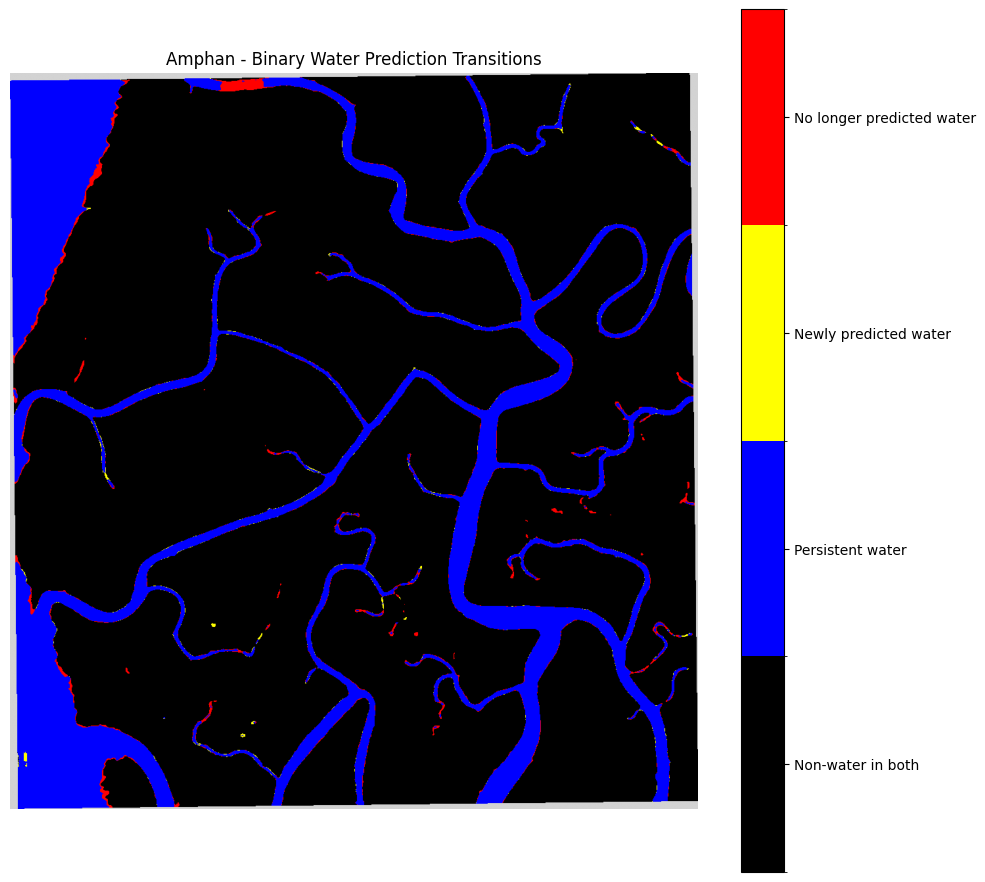


Transition PNG: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_zero_shot/amphan_water_transition_map.png
Transition GeoTIFF: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_zero_shot/amphan_water_transition_map.tif

BINARY TRANSITION ANALYSIS COMPLETED!


In [ ]:

# =====================================================
# AMPHAN ZERO-SHOT BINARY WATER TRANSITION ANALYSIS
# =====================================================

import rasterio
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm

# 1. LOAD PROBABILITY MAPS

PRE_FILE = RESULT_DIR / "amphan_pre_probability.tif"

POST_FILE = RESULT_DIR / "amphan_post_probability.tif"

with rasterio.open(PRE_FILE) as src:

    pre_prob = src.read(1)

    profile = src.profile.copy()
    transform = src.transform
    crs = src.crs

with rasterio.open(POST_FILE) as src:

    post_prob = src.read(1)

    assert src.transform == transform
    assert src.crs == crs

# 2. COMMON VALID PIXELS

valid = (
    np.isfinite(pre_prob) &
    np.isfinite(post_prob) &
    (pre_prob != -9999) &
    (post_prob != -9999)
)

# 3. APPLY IDENTICAL THRESHOLD

THRESHOLD = 0.5

pre_water = pre_prob >= THRESHOLD
post_water = post_prob >= THRESHOLD

# 4. IDENTIFY FOUR TRANSITION CATEGORIES

persistent_water = valid & pre_water & post_water

newly_predicted_water = valid & (~pre_water) & post_water

disappeared_water = valid & pre_water & (~post_water)

persistent_nonwater = valid & (~pre_water) & (~post_water)

# 5. COUNT PIXELS

categories = {

    "Persistent non-water": persistent_nonwater,
    "Persistent water": persistent_water,
    "Newly predicted water": newly_predicted_water,
    "Water no longer predicted": disappeared_water

}

total_valid = int(valid.sum())

print("AMPHAN BINARY TRANSITION ANALYSIS")
print("=" * 50)

for name, mask in categories.items():

    count = int(mask.sum())

    percentage = 100 * count / total_valid

    print("\n", name)

    print("Pixels:", count)

    print("Percentage:", round(percentage, 3), "%")


# 6. COMPARE PRE/POST WATER MASKS

intersection = int(
    (persistent_water).sum()
)

union = int(
    (valid & (pre_water | post_water)).sum()
)

jaccard = intersection / union if union else np.nan

print("\nPRE/POST PREDICTION OVERLAP")
print("--------------------------------")

print("Jaccard similarity:", round(jaccard, 5))

print(
    "Pre-event water pixels:",
    int((valid & pre_water).sum())
)

print(
    "Post-event water pixels:",
    int((valid & post_water).sum())
)

print(
    "Net pixel change:",
    int(
        (valid & post_water).sum() -
        (valid & pre_water).sum()
    )
)


# 7. CALCULATE AREA IN SQUARE KILOMETRES

pixel_area = abs(
    transform.a * transform.e -
    transform.b * transform.d
)

pixel_area_km2 = pixel_area / 1_000_000

print("\nPREDICTED AREAS")
print("--------------------------------")

for name, mask in categories.items():

    area = mask.sum() * pixel_area_km2

    print(name, ":", round(float(area), 4), "km²")


# 8. CREATE TRANSITION MAP

# 0 = Non-water in both
# 1 = Water in both
# 2 = Newly predicted water after event
# 3 = Water predicted only before event
# 255 = Invalid

transition = np.full(
    pre_prob.shape,
    255,
    dtype=np.uint8
)

transition[persistent_nonwater] = 0
transition[persistent_water] = 1
transition[newly_predicted_water] = 2
transition[disappeared_water] = 3

# 9. VISUALISE

cmap = ListedColormap([
    "black",
    "blue",
    "yellow",
    "red"
])

cmap.set_bad("lightgray")

norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    cmap.N
)

display_map = np.ma.masked_where(
    ~valid,
    transition.astype(float)
)

plt.figure(figsize=(10, 9))

plt.imshow(
    display_map,
    cmap=cmap,
    norm=norm
)

colorbar = plt.colorbar(
    ticks=[0, 1, 2, 3]
)

colorbar.ax.set_yticklabels([
    "Non-water in both",
    "Persistent water",
    "Newly predicted water",
    "No longer predicted water"
])

plt.title("Amphan - Binary Water Prediction Transitions")

plt.axis("off")
plt.tight_layout()

TRANSITION_PATH = (
    RESULT_DIR / "amphan_water_transition_map.png"
)

plt.savefig(
    TRANSITION_PATH,
    dpi=250,
    bbox_inches="tight"
)

plt.show()


# 10. SAVE GEOTIFF

output_profile = profile.copy()

output_profile.update(
    count=1,
    dtype="uint8",
    nodata=255,
    compress="deflate"
)

TRANSITION_TIF = (
    RESULT_DIR / "amphan_water_transition_map.tif"
)

with rasterio.open(
    TRANSITION_TIF,
    "w",
    **output_profile
) as dst:

    dst.write(transition, 1)

print("\nTransition PNG:", TRANSITION_PATH)
print("Transition GeoTIFF:", TRANSITION_TIF)

print("\nBINARY TRANSITION ANALYSIS COMPLETED!")



 NEWLY PREDICTED WATER
Number of separate clusters: 794
Largest cluster: 65
Clusters containing >= 100 pixels: 0
Median cluster size: 1.0

TOP 10 CLUSTERS
             category  component  pixels  area_km2     center_x     center_y
NEWLY PREDICTED WATER        745      65    0.0065 675845.00000 2.412441e+06
NEWLY PREDICTED WATER        398      38    0.0038 677080.00000 2.416708e+06
NEWLY PREDICTED WATER         28      36    0.0036 685163.88889 2.422001e+06
NEWLY PREDICTED WATER         42      34    0.0034 685496.17647 2.421780e+06
NEWLY PREDICTED WATER        614      31    0.0031 678707.25806 2.414448e+06
NEWLY PREDICTED WATER        729      28    0.0028 679155.35714 2.412770e+06
NEWLY PREDICTED WATER        626      26    0.0026 679418.84615 2.414273e+06
NEWLY PREDICTED WATER        630      23    0.0023 685882.82609 2.414287e+06
NEWLY PREDICTED WATER         30      23    0.0023 684000.65217 2.421984e+06
NEWLY PREDICTED WATER        564      20    0.0020 681274.50000 2.414832e+

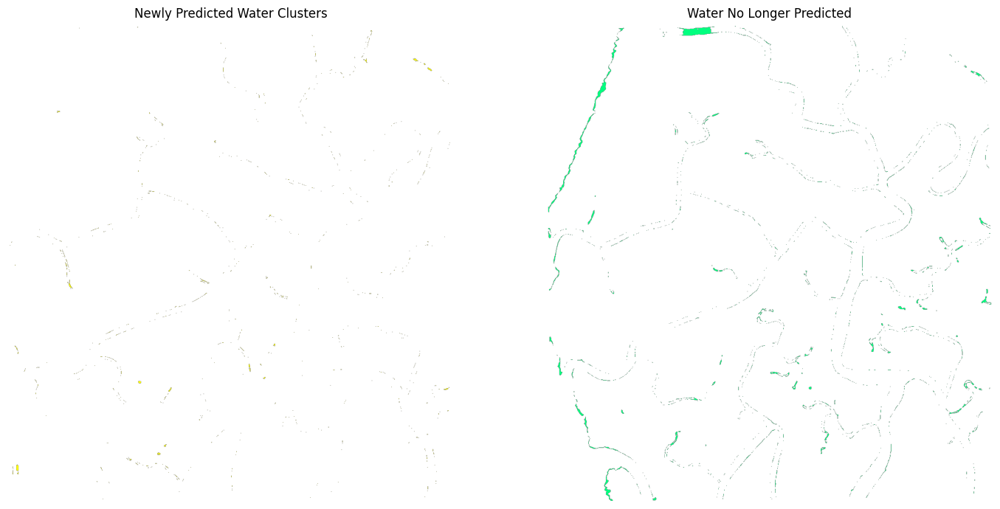


COMPONENT ANALYSIS SAVED!
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_zero_shot/amphan_transition_components.csv
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_zero_shot/amphan_transition_clusters.png


In [ ]:

# ==========================================
# AMPHAN TRANSITION CONNECTED COMPONENT ANALYSIS
# ==========================================

import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import label

from rasterio.transform import xy
from pathlib import Path

# 1. LOAD PROBABILITY MAPS

RESULT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_zero_shot"
)

with rasterio.open(
    RESULT_DIR / "amphan_pre_probability.tif"
) as src:

    pre_prob = src.read(1)
    transform = src.transform
    profile = src.profile.copy()

with rasterio.open(
    RESULT_DIR / "amphan_post_probability.tif"
) as src:

    post_prob = src.read(1)

assert pre_prob.shape == post_prob.shape

# 2. COMMON VALIDITY MASK

valid = (
    np.isfinite(pre_prob) &
    np.isfinite(post_prob) &
    (pre_prob != -9999) &
    (post_prob != -9999)
)

# 3. CREATE TRANSITION MASKS

threshold = 0.5

new_water = (
    valid &
    (pre_prob < threshold) &
    (post_prob >= threshold)
)

lost_water = (
    valid &
    (pre_prob >= threshold) &
    (post_prob < threshold)
)

# 4. CALCULATE PIXEL AREA

pixel_area_km2 = abs(
    transform.a * transform.e -
    transform.b * transform.d
) / 1_000_000

# 5. CONNECTED COMPONENT ANALYSIS
# Eight-connectivity: diagonal neighbours are connected.

structure = np.ones((3, 3), dtype=np.uint8)


def analyze_components(mask, category):

    labels, number = label(
        mask,
        structure=structure
    )

    sizes = np.bincount(labels.ravel())[1:]

    order = np.argsort(sizes)[::-1]

    records = []

    for index in order:

        component_id = index + 1
        pixel_count = int(sizes[index])

        rows, cols = np.where(
            labels == component_id
        )

        mean_row = float(rows.mean())
        mean_col = float(cols.mean())

        longitude_or_easting, latitude_or_northing = xy(
            transform,
            mean_row,
            mean_col
        )

        records.append({

            "category": category,
            "component": int(component_id),
            "pixels": pixel_count,

            "area_km2": (
                pixel_count * pixel_area_km2
            ),

            "center_x": longitude_or_easting,
            "center_y": latitude_or_northing

        })

    df = pd.DataFrame(records)

    print("\n", category)
    print("=" * 45)

    print("Number of separate clusters:", number)

    if number > 0:

        print("Largest cluster:", int(sizes.max()))

        print(
            "Clusters containing >= 100 pixels:",
            int((sizes >= 100).sum())
        )

        print(
            "Median cluster size:",
            float(np.median(sizes))
        )

        print("\nTOP 10 CLUSTERS")

        print(
            df.head(10).round(5).to_string(index=False)
        )

    else:

        print("No clusters found.")

    return df, labels


# 6. ANALYZE NEW AND DISAPPEARED WATER

new_df, new_labels = analyze_components(
    new_water,
    "NEWLY PREDICTED WATER"
)

lost_df, lost_labels = analyze_components(
    lost_water,
    "WATER NO LONGER PREDICTED"
)

# 7. SAVE COMPONENT RESULTS

component_df = pd.concat(
    [new_df, lost_df],
    ignore_index=True
)

COMPONENT_PATH = (
    RESULT_DIR / "amphan_transition_components.csv"
)

component_df.to_csv(
    COMPONENT_PATH,
    index=False
)

# 8. VISUALIZE CLUSTERS

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 7)
)

axes[0].imshow(
    np.where(new_water, 1, np.nan),
    cmap="autumn",
    vmin=0,
    vmax=1
)

axes[0].set_title("Newly Predicted Water Clusters")

axes[1].imshow(
    np.where(lost_water, 1, np.nan),
    cmap="winter",
    vmin=0,
    vmax=1
)

axes[1].set_title("Water No Longer Predicted")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

CLUSTER_MAP = (
    RESULT_DIR / "amphan_transition_clusters.png"
)

plt.savefig(
    CLUSTER_MAP,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("\nCOMPONENT ANALYSIS SAVED!")
print(COMPONENT_PATH)
print(CLUSTER_MAP)


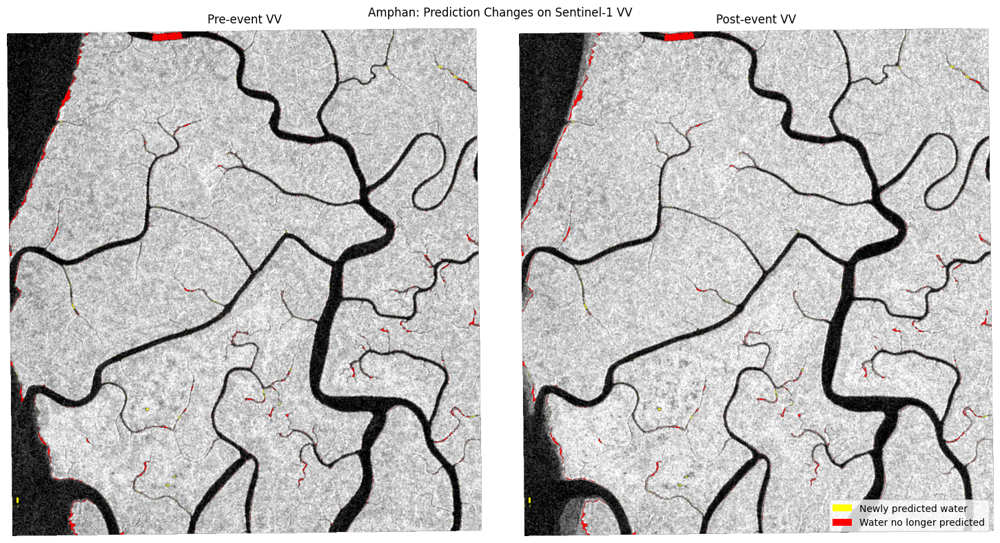

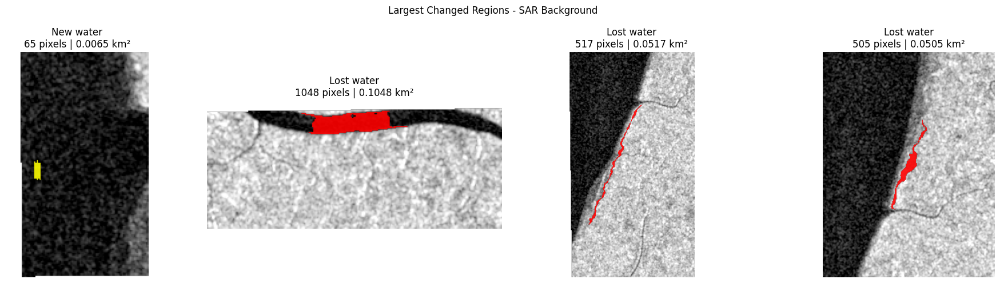


CHANGED REGION DIAGNOSTICS
New-water components: 794
New components with <= 5 pixels: 751
Largest new component: 65

Lost-water components: 1882
Lost components with >= 100 pixels: 11
Largest lost component: 1048

SAR OVERLAY INSPECTION COMPLETED!


In [ ]:

# =====================================================
# AMPHAN: SAR OVERLAY AND CHANGED-REGION INSPECTION
# =====================================================

import rasterio
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import label
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from pathlib import Path

# 1. FILE PATHS

PRE_PATH = Path(
    "/content/drive/MyDrive/FloodProject/test_pre_event_s1.tif"
)

POST_PATH = Path(
    "/content/drive/MyDrive/FloodProject/test_post_event_s1.tif"
)

PRE_PROB = RESULT_DIR / "amphan_pre_probability.tif"
POST_PROB = RESULT_DIR / "amphan_post_probability.tif"

# 2. LOAD VV BACKSCATTER

with rasterio.open(PRE_PATH) as src:
    pre_vv = src.read(1)
    transform = src.transform

with rasterio.open(POST_PATH) as src:
    post_vv = src.read(1)

# 3. LOAD MODEL PROBABILITIES

with rasterio.open(PRE_PROB) as src:
    pre_prob = src.read(1)

with rasterio.open(POST_PROB) as src:
    post_prob = src.read(1)

# 4. COMMON VALIDITY MASK

valid = (
    np.isfinite(pre_vv) &
    np.isfinite(post_vv) &
    np.isfinite(pre_prob) &
    np.isfinite(post_prob) &
    (pre_prob != -9999) &
    (post_prob != -9999)
)

# 5. IDENTIFY CHANGED PREDICTIONS

new_water = (
    valid &
    (pre_prob < 0.5) &
    (post_prob >= 0.5)
)

lost_water = (
    valid &
    (pre_prob >= 0.5) &
    (post_prob < 0.5)
)

# 6. CONNECTED COMPONENTS

structure = np.ones((3, 3), dtype=np.uint8)

new_labels, new_count = label(
    new_water,
    structure=structure
)

lost_labels, lost_count = label(
    lost_water,
    structure=structure
)

def get_components(labels, count):

    sizes = np.bincount(labels.ravel())[1:]

    order = np.argsort(sizes)[::-1] + 1

    return [
        (int(i), int(sizes[i - 1]))
        for i in order[:count]
        if sizes[i - 1] > 0
    ]

top_new = get_components(new_labels, 3)
top_lost = get_components(lost_labels, 3)

# 7. DISPLAY LIMITS

combined = np.concatenate([
    pre_vv[valid],
    post_vv[valid]
])

vmin, vmax = np.percentile(
    combined, [2, 98]
)

# Overlay helper

def add_overlays(ax, new_mask, lost_mask):

    yellow = np.ma.masked_where(
        ~new_mask,
        np.ones(new_mask.shape)
    )

    red = np.ma.masked_where(
        ~lost_mask,
        np.ones(lost_mask.shape)
    )

    ax.imshow(
        yellow,
        cmap=ListedColormap(["yellow"]),
        vmin=0,
        vmax=1,
        alpha=0.95
    )

    ax.imshow(
        red,
        cmap=ListedColormap(["red"]),
        vmin=0,
        vmax=1,
        alpha=0.95
    )


# 8. FULL-IMAGE OVERLAY

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 8)
)

for ax, background, title in [
    (axes[0], pre_vv, "Pre-event VV"),
    (axes[1], post_vv, "Post-event VV")
]:

    background = np.where(
        valid,
        background,
        np.nan
    )

    ax.imshow(
        background,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )

    add_overlays(
        ax,
        new_water,
        lost_water
    )

    ax.set_title(title)
    ax.axis("off")

legend = [
    Patch(facecolor="yellow", label="Newly predicted water"),
    Patch(facecolor="red", label="Water no longer predicted")
]

axes[1].legend(
    handles=legend,
    loc="lower right"
)

plt.suptitle(
    "Amphan: Prediction Changes on Sentinel-1 VV"
)

plt.tight_layout()

plt.show()


# 9. INSPECT FOUR LARGEST CHANGED COMPONENTS

selected = [
    ("New water", new_labels, top_new[:1], "yellow"),
    ("Lost water", lost_labels, top_lost[:3], "red")
]

items = []

for kind, component_labels, components, color in selected:

    for component_id, pixel_count in components:

        rows, cols = np.where(
            component_labels == component_id
        )

        items.append((
            kind,
            component_labels,
            component_id,
            pixel_count,
            rows,
            cols,
            color
        ))

fig, axes = plt.subplots(
    1,
    max(1, len(items)),
    figsize=(5 * max(1, len(items)), 5)
)

if len(items) == 1:
    axes = [axes]

for ax, item in zip(axes, items):

    kind, component_labels, component_id, pixel_count, rows, cols, color = item

    padding = 80

    r0 = max(0, int(rows.min()) - padding)
    r1 = min(pre_vv.shape[0], int(rows.max()) + padding + 1)

    c0 = max(0, int(cols.min()) - padding)
    c1 = min(pre_vv.shape[1], int(cols.max()) + padding + 1)

    ax.imshow(
        post_vv[r0:r1, c0:c1],
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )

    component_mask = (
        component_labels[r0:r1, c0:c1] == component_id
    )

    overlay = np.ma.masked_where(
        ~component_mask,
        np.ones(component_mask.shape)
    )

    ax.imshow(
        overlay,
        cmap=ListedColormap([color]),
        vmin=0,
        vmax=1,
        alpha=0.9
    )

    area = pixel_count * 0.0001

    ax.set_title(
        f"{kind}\n{pixel_count} pixels | {area:.4f} km²"
    )

    ax.axis("off")

plt.suptitle(
    "Largest Changed Regions - SAR Background"
)

plt.tight_layout()

plt.show()


# 10. SMALL-CLUSTER STATISTICS

new_sizes = np.bincount(new_labels.ravel())[1:]
lost_sizes = np.bincount(lost_labels.ravel())[1:]

print("\nCHANGED REGION DIAGNOSTICS")
print("=" * 45)

print("New-water components:", new_count)

print(
    "New components with <= 5 pixels:",
    int((new_sizes <= 5).sum())
)

print("Largest new component:", int(new_sizes.max()))

print("\nLost-water components:", lost_count)

print(
    "Lost components with >= 100 pixels:",
    int((lost_sizes >= 100).sum())
)

print("Largest lost component:", int(lost_sizes.max()))

print("\nSAR OVERLAY INSPECTION COMPLETED!")


AMPHAN THRESHOLD SENSITIVITY
 Threshold  Pre_water_km2  Post_water_km2  New_water_km2  Lost_water_km2  Net_change_km2  Jaccard
       0.3        18.9819         18.1966         0.1713          0.9566         -0.7853   0.9411
       0.4        18.6684         17.9063         0.1726          0.9347         -0.7621   0.9412
       0.5        18.3892         17.6285         0.1690          0.9297         -0.7607   0.9408
       0.6        18.1056         17.3514         0.1649          0.9191         -0.7542   0.9407
       0.7        17.8198         17.0577         0.1601          0.9222         -0.7621   0.9398


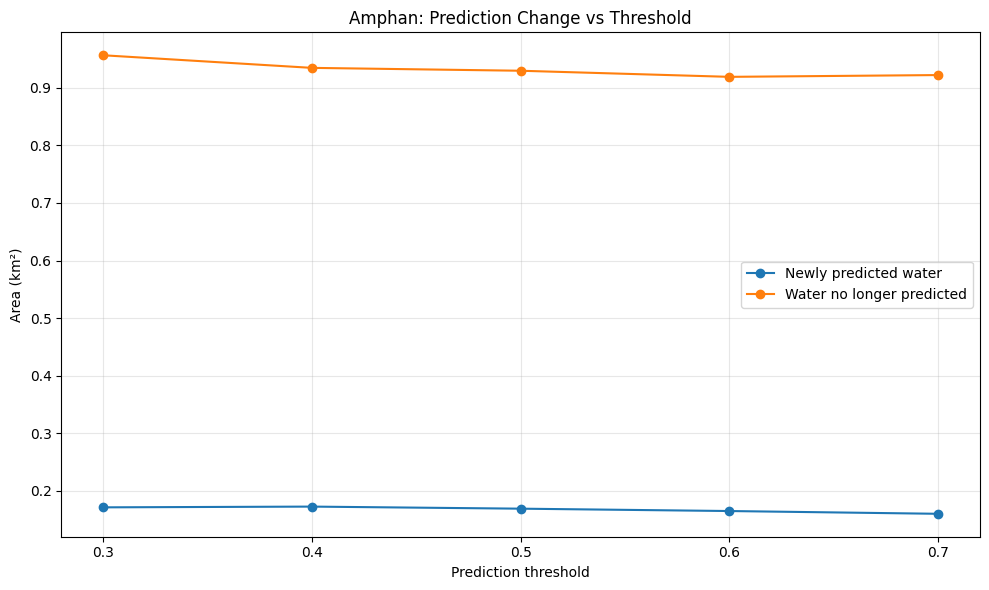


THRESHOLD ANALYSIS COMPLETED!


In [ ]:

# ==========================================
# AMPHAN THRESHOLD SENSITIVITY ANALYSIS
# ==========================================

import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

RESULT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_zero_shot"
)

# 1. LOAD PROBABILITY MAPS

with rasterio.open(
    RESULT_DIR / "amphan_pre_probability.tif"
) as src:

    pre = src.read(1)
    transform = src.transform

with rasterio.open(
    RESULT_DIR / "amphan_post_probability.tif"
) as src:

    post = src.read(1)

# 2. COMMON VALID PIXELS

valid = (
    np.isfinite(pre) &
    np.isfinite(post) &
    (pre != -9999) &
    (post != -9999)
)

total = int(valid.sum())

# 3. PIXEL AREA

pixel_area_km2 = abs(
    transform.a * transform.e -
    transform.b * transform.d
) / 1_000_000

# 4. TEST DIFFERENT THRESHOLDS

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for threshold in thresholds:

    pre_water = valid & (pre >= threshold)

    post_water = valid & (post >= threshold)

    persistent = pre_water & post_water

    newly_detected = (~pre_water) & post_water & valid

    disappeared = pre_water & (~post_water) & valid

    union = int((pre_water | post_water).sum())

    intersection = int(persistent.sum())

    jaccard = (
        intersection / union
        if union > 0 else np.nan
    )

    results.append({

        "Threshold": threshold,

        "Pre_water_km2": (
            pre_water.sum() * pixel_area_km2
        ),

        "Post_water_km2": (
            post_water.sum() * pixel_area_km2
        ),

        "New_water_km2": (
            newly_detected.sum() * pixel_area_km2
        ),

        "Lost_water_km2": (
            disappeared.sum() * pixel_area_km2
        ),

        "Net_change_km2": (
            (post_water.sum() - pre_water.sum())
            * pixel_area_km2
        ),

        "Jaccard": jaccard

    })


# 5. DISPLAY RESULTS

df = pd.DataFrame(results)

print("AMPHAN THRESHOLD SENSITIVITY")
print("=" * 65)

print(
    df.round(4).to_string(index=False)
)

# 6. PLOT NEW AND LOST WATER AREAS

plt.figure(figsize=(10, 6))

plt.plot(
    df["Threshold"],
    df["New_water_km2"],
    marker="o",
    label="Newly predicted water"
)

plt.plot(
    df["Threshold"],
    df["Lost_water_km2"],
    marker="o",
    label="Water no longer predicted"
)

plt.xlabel("Prediction threshold")

plt.ylabel("Area (km²)")

plt.title(
    "Amphan: Prediction Change vs Threshold"
)

plt.xticks(thresholds)

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "amphan_threshold_sensitivity.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

# 7. SAVE TABLE

df.to_csv(
    RESULT_DIR / "amphan_threshold_sensitivity.csv",
    index=False
)

print("\nTHRESHOLD ANALYSIS COMPLETED!")



In [ ]:

# ==========================================
# MEMBER A: UPDATED FLOOD DATASET
# CLIPPING + NORMALIZATION + NO-DATA MASKING
# ==========================================

import json
import numpy as np
import pandas as pd
import torch
import rasterio

from pathlib import Path
from torch.utils.data import Dataset


# 1. PROJECT PATHS

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

S1_DIR = PROJECT_DIR / "data/raw/S1Hand"
LABEL_DIR = PROJECT_DIR / "data/LabelHand"

CLEAN_DIR = PROJECT_DIR / "data/processed/clean_splits"


# 2. LOAD FINAL PREPROCESSING STATISTICS

with open(
    PROJECT_DIR / "data/processed/normalization_stats_clipped.json",
    "r"
) as f:
    stats = json.load(f)

MEAN = np.array(stats["mean"], dtype=np.float32)
STD = np.array(stats["std"], dtype=np.float32)

CLIP_MIN = np.array(stats["clip_min"], dtype=np.float32)
CLIP_MAX = np.array(stats["clip_max"], dtype=np.float32)

assert np.all(STD > 0)
assert np.all(CLIP_MIN < CLIP_MAX)


# 3. LOAD CLEANED TRAINING DATA

train_df = pd.read_csv(
    CLEAN_DIR / "train_clean.csv",
    dtype=str
)


# 4. DEFINE UPDATED DATASET

class FloodDatasetClipped(Dataset):

    def __init__(self, dataframe):

        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = S1_DIR / row["satellite_image"].strip()
        label_path = LABEL_DIR / row["flood_label"].strip()


        # READ SENTINEL-1 IMAGE

        with rasterio.open(image_path) as src:

            image = src.read().astype(np.float32)
            nodata = src.nodata

        if image.ndim != 3 or image.shape[0] != 2:
            raise ValueError(
                f"Expected 2 SAR bands: {image_path.name}"
            )


        # IDENTIFY VALID SAR PIXELS

        valid_sar = np.isfinite(image).all(axis=0)

        if nodata is not None and np.isfinite(nodata):

            valid_sar &= np.all(
                image != nodata,
                axis=0
            )


        # READ FLOOD LABEL

        with rasterio.open(label_path) as src:

            label = src.read(1)

        if label.shape != image.shape[1:]:
            raise ValueError(
                f"Image-label shape mismatch: {image_path.name}"
            )


        # VALID LABELS ARE 0 (NON-WATER) OR 1 (WATER)

        valid_labels = np.isin(label, [0, 1])

        valid_mask = valid_sar & valid_labels


        # CLIP VV AND VH BEFORE NORMALIZATION

        image = np.clip(
            image,
            CLIP_MIN[:, None, None],
            CLIP_MAX[:, None, None]
        )


        # NORMALIZE USING TRAINING STATISTICS

        image = (
            image - MEAN[:, None, None]
        ) / STD[:, None, None]


        # REPLACE INVALID SAR PIXELS WITH ZERO

        image[:, ~valid_sar] = 0.0


        # CREATE BINARY FLOOD TARGET

        target = np.where(
            valid_mask,
            label == 1,
            False
        ).astype(np.float32)


        # CONVERT TO PYTORCH TENSORS

        image = torch.from_numpy(
            np.ascontiguousarray(image)
        )

        target = torch.from_numpy(
            np.ascontiguousarray(target[None])
        )

        valid_mask = torch.from_numpy(
            np.ascontiguousarray(valid_mask[None])
        )

        return image, target, valid_mask


# 5. CREATE UPDATED TRAINING DATASET

clipped_train_dataset = FloodDatasetClipped(train_df)


# 6. TEST ONE SAMPLE

image, target, mask = clipped_train_dataset[0]

print("UPDATED DATASET TEST")
print("--------------------------------")

print("Training images:", len(clipped_train_dataset))

print("Image shape:", image.shape)
print("Target shape:", target.shape)
print("Mask shape:", mask.shape)

print("Image dtype:", image.dtype)
print("Target dtype:", target.dtype)

print("Valid pixels:", mask.sum().item())

print(
    "Unique target values:",
    torch.unique(target[mask]).tolist()
)

print(
    "Image contains only finite values:",
    torch.isfinite(image).all().item()
)

print("\nUPDATED DATASET WORKING!")


UPDATED DATASET TEST
--------------------------------
Training images: 251
Image shape: torch.Size([2, 512, 512])
Target shape: torch.Size([1, 512, 512])
Mask shape: torch.Size([1, 512, 512])
Image dtype: torch.float32
Target dtype: torch.float32
Valid pixels: 259269
Unique target values: [0.0, 1.0]
Image contains only finite values: True

UPDATED DATASET WORKING!


In [ ]:

# ==========================================
# MEMBER A: DATA AUGMENTATION
# ==========================================

import torch
from torch.utils.data import Dataset


class FloodDatasetAugmented(FloodDatasetClipped):

    def __init__(
        self,
        dataframe,
        augment=False,
        crop_size=256
    ):

        super().__init__(dataframe)

        self.augment = augment
        self.crop_size = crop_size


    def __getitem__(self, index):

        # Load clipped and normalized data
        image, target, valid_mask = super().__getitem__(index)

        if not self.augment:
            return image, target, valid_mask

        # Random 256 x 256 crop
        _, height, width = image.shape

        if height < self.crop_size or width < self.crop_size:
            raise ValueError("Image smaller than crop size")

        top = torch.randint(
            0, height - self.crop_size + 1, (1,)
        ).item()

        left = torch.randint(
            0, width - self.crop_size + 1, (1,)
        ).item()

        image = image[
            :, top:top+self.crop_size,
            left:left+self.crop_size
        ]

        target = target[
            :, top:top+self.crop_size,
            left:left+self.crop_size
        ]

        valid_mask = valid_mask[
            :, top:top+self.crop_size,
            left:left+self.crop_size
        ]

        # Horizontal flip
        if torch.rand(1).item() < 0.5:

            image = torch.flip(image, dims=[2])
            target = torch.flip(target, dims=[2])
            valid_mask = torch.flip(valid_mask, dims=[2])

        # Vertical flip
        if torch.rand(1).item() < 0.5:

            image = torch.flip(image, dims=[1])
            target = torch.flip(target, dims=[1])
            valid_mask = torch.flip(valid_mask, dims=[1])

        # Random rotation: 0, 90, 180 or 270 degrees
        k = torch.randint(0, 4, (1,)).item()

        image = torch.rot90(image, k, dims=[1, 2])
        target = torch.rot90(target, k, dims=[1, 2])
        valid_mask = torch.rot90(valid_mask, k, dims=[1, 2])

        return image, target, valid_mask


# ==========================================
# TEST AUGMENTATION
# ==========================================

aug_train_dataset = FloodDatasetAugmented(
    train_df,
    augment=True
)

image, target, mask = aug_train_dataset[0]

print("AUGMENTATION TEST")
print("--------------------------------")

print("Training images:", len(aug_train_dataset))
print("Image shape:", image.shape)
print("Target shape:", target.shape)
print("Mask shape:", mask.shape)

print("Valid pixels:", mask.sum().item())

print(
    "Image finite:",
    torch.isfinite(image).all().item()
)

print(
    "Target values:",
    torch.unique(target[mask]).tolist()
)

print("\nDATA AUGMENTATION WORKING!")


AUGMENTATION TEST
--------------------------------
Training images: 251
Image shape: torch.Size([2, 256, 256])
Target shape: torch.Size([1, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Valid pixels: 65536
Image finite: True
Target values: [0.0]

DATA AUGMENTATION WORKING!


In [ ]:

# ==========================================
# MEMBER A: AUGMENTATION QUALITY AUDIT
# ==========================================

import numpy as np
import torch

N_SAMPLES = 128

rng = np.random.default_rng(42)
torch.manual_seed(42)

indices = rng.integers(
    0,
    len(aug_train_dataset),
    size=N_SAMPLES
)

water_crops = 0
empty_water_crops = 0

total_valid = 0
total_water = 0

for idx in indices:

    image, target, mask = aug_train_dataset[int(idx)]

    valid = mask.bool()

    valid_count = int(valid.sum().item())

    water_count = int(
        ((target > 0.5) & valid).sum().item()
    )

    total_valid += valid_count
    total_water += water_count

    if water_count > 0:
        water_crops += 1
    else:
        empty_water_crops += 1

print("AUGMENTATION QUALITY AUDIT")
print("--------------------------------")

print("Crops examined:", N_SAMPLES)
print("Crops containing water:", water_crops)
print("Crops without water:", empty_water_crops)

print(
    "Water-containing crop percentage:",
    round(100 * water_crops / N_SAMPLES, 2), "%"
)

print(
    "Overall water pixel percentage:",
    round(100 * total_water / max(total_valid, 1), 4), "%"
)

print("\nAUGMENTATION AUDIT COMPLETED!")


AUGMENTATION QUALITY AUDIT
--------------------------------
Crops examined: 128
Crops containing water: 100
Crops without water: 28
Water-containing crop percentage: 78.12 %
Overall water pixel percentage: 9.9322 %

AUGMENTATION AUDIT COMPLETED!


In [ ]:

# ==========================================
# MEMBER A: FINAL DATASET AND DATALOADERS
# ==========================================

import pandas as pd
from torch.utils.data import DataLoader

# 1. LOAD CLEANED CSV FILES

CLEAN_DIR = PROJECT_DIR / "data/processed/clean_splits"

train_df = pd.read_csv(
    CLEAN_DIR / "train_clean.csv",
    dtype=str
)

valid_df = pd.read_csv(
    CLEAN_DIR / "valid_clean.csv",
    dtype=str
)

# Use the 88-image evaluable test split
test_df = pd.read_csv(
    CLEAN_DIR / "test_evaluable.csv",
    dtype=str
)


# 2. CREATE DATASETS

train_dataset = FloodDatasetAugmented(
    train_df,
    augment=True,
    crop_size=256
)

valid_dataset = FloodDatasetAugmented(
    valid_df,
    augment=False
)

test_dataset = FloodDatasetAugmented(
    test_df,
    augment=False
)


# 3. CREATE DATALOADERS

TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)


# 4. TEST TRAINING BATCH

images, labels, masks = next(iter(train_loader))

print("TRAINING BATCH")
print("--------------------------------")

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Masks:", masks.shape)

print("Valid pixels:", masks.sum().item())

print(
    "Unique labels:",
    torch.unique(labels[masks.bool()]).tolist()
)

print(
    "Finite images:",
    torch.isfinite(images).all().item()
)


# 5. TEST VALIDATION BATCH

val_images, val_labels, val_masks = next(iter(valid_loader))

print("\nVALIDATION BATCH")
print("--------------------------------")

print("Images:", val_images.shape)
print("Labels:", val_labels.shape)
print("Masks:", val_masks.shape)


# 6. TEST TESTING BATCH

test_images, test_labels, test_masks = next(iter(test_loader))

print("\nTEST BATCH")
print("--------------------------------")

print("Images:", test_images.shape)
print("Labels:", test_labels.shape)
print("Masks:", test_masks.shape)


# 7. FINAL SUMMARY

print("\nDATASET SUMMARY")
print("--------------------------------")

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Testing images:", len(test_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Testing batches:", len(test_loader))

print("Training batch size:", TRAIN_BATCH_SIZE)
print("Evaluation batch size:", EVAL_BATCH_SIZE)

print("\nFINAL DATALOADERS CREATED!")


TRAINING BATCH
--------------------------------
Images: torch.Size([16, 2, 256, 256])
Labels: torch.Size([16, 1, 256, 256])
Masks: torch.Size([16, 1, 256, 256])
Valid pixels: 984339
Unique labels: [0.0, 1.0]
Finite images: True

VALIDATION BATCH
--------------------------------
Images: torch.Size([2, 2, 512, 512])
Labels: torch.Size([2, 1, 512, 512])
Masks: torch.Size([2, 1, 512, 512])

TEST BATCH
--------------------------------
Images: torch.Size([2, 2, 512, 512])
Labels: torch.Size([2, 1, 512, 512])
Masks: torch.Size([2, 1, 512, 512])

DATASET SUMMARY
--------------------------------
Training images: 251
Validation images: 86
Testing images: 88
Training batches: 16
Validation batches: 43
Testing batches: 44
Training batch size: 16
Evaluation batch size: 2

FINAL DATALOADERS CREATED!


In [ ]:

# ==========================================
# MEMBER A: COMPLETE DATASET INTEGRITY AUDIT
# ==========================================

splits = {
    "Training": train_df,
    "Validation": valid_df,
    "Testing": test_df
}

for split_name, dataframe in splits.items():

    dataset = FloodDatasetClipped(dataframe)

    empty_images = 0
    water_images = 0
    nonwater_images = 0

    total_valid = 0
    total_water = 0

    print(f"\nAUDITING {split_name.upper()}...")

    for i in range(len(dataset)):

        image, target, mask = dataset[i]

        valid = mask.bool()

        valid_count = int(valid.sum().item())

        water_count = int(
            ((target > 0.5) & valid).sum().item()
        )

        total_valid += valid_count
        total_water += water_count

        if valid_count == 0:
            empty_images += 1
        elif water_count > 0:
            water_images += 1
        else:
            nonwater_images += 1

        if not torch.isfinite(image).all():
            raise ValueError(
                f"Non-finite image in {split_name}: {i}"
            )

    water_percentage = (
        100 * total_water / max(total_valid, 1)
    )

    print("--------------------------------")
    print("Total images:", len(dataset))
    print("Zero-valid-pixel images:", empty_images)
    print("Images containing water:", water_images)
    print("Images without water:", nonwater_images)
    print("Total valid pixels:", f"{total_valid:,}")
    print("Total water pixels:", f"{total_water:,}")
    print("Water percentage:", round(water_percentage, 4), "%")

print("\nCOMPLETE DATASET AUDIT FINISHED!")



AUDITING TRAINING...
--------------------------------
Total images: 251
Zero-valid-pixel images: 0
Images containing water: 219
Images without water: 32
Total valid pixels: 57,279,257
Total water pixels: 5,446,678
Water percentage: 9.509 %

AUDITING VALIDATION...
--------------------------------
Total images: 86
Zero-valid-pixel images: 0
Images containing water: 77
Images without water: 9
Total valid pixels: 20,274,154
Total water pixels: 2,231,206
Water percentage: 11.0052 %

AUDITING TESTING...
--------------------------------
Total images: 88
Zero-valid-pixel images: 0
Images containing water: 82
Images without water: 6
Total valid pixels: 20,443,959
Total water pixels: 2,515,008
Water percentage: 12.302 %

COMPLETE DATASET AUDIT FINISHED!


In [ ]:

# ==========================================
# MEMBER A: T4 GPU MEMORY TEST
# ==========================================

import torch
import gc
import segmentation_models_pytorch as smp

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is not available!")

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

print("GPU:", torch.cuda.get_device_name(0))

free, total = torch.cuda.mem_get_info()

print("Total GPU memory:", round(total / 1024**3, 2), "GB")
print("Free GPU memory:", round(free / 1024**3, 2), "GB")


# Create a temporary U-Net
test_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=2,
    classes=1,
    activation=None
).to(device)

test_optimizer = torch.optim.Adam(
    test_model.parameters(),
    lr=0.0001
)

test_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)


# Load one actual training batch
images, targets, masks = next(iter(train_loader))

images = images.to(device)
targets = targets.to(device)
masks = masks.to(device)

print("\nTesting batch:", images.shape)

test_model.train()
test_optimizer.zero_grad(set_to_none=True)

# Actual forward and backward pass
with torch.autocast(
    device_type="cuda",
    dtype=torch.float16
):

    logits = test_model(images)

    loss, bce, dice = bce_dice_loss(
        logits,
        targets,
        masks
    )

if not torch.isfinite(loss).item():
    raise RuntimeError("Non-finite test loss!")

test_scaler.scale(loss).backward()
test_scaler.step(test_optimizer)
test_scaler.update()

peak_memory = torch.cuda.max_memory_allocated()

print("\nGPU TRAINING TEST")
print("--------------------------------")
print("Loss:", round(loss.item(), 5))
print("BCE:", round(bce.item(), 5))
print("Dice:", round(dice.item(), 5))
print("Peak allocated GPU memory:",
      round(peak_memory / 1024**3, 2), "GB")

print("\nFORWARD AND BACKWARD PASS SUCCESSFUL!")


# Release temporary model
del test_model, test_optimizer, test_scaler
del images, targets, masks, logits, loss, bce, dice

gc.collect()
torch.cuda.empty_cache()

print("\nTemporary model released.")


GPU: Tesla T4
Total GPU memory: 14.56 GB
Free GPU memory: 13.11 GB

Testing batch: torch.Size([16, 2, 256, 256])

GPU TRAINING TEST
--------------------------------
Loss: 0.95354
BCE: 0.97066
Dice: 0.93643
Peak allocated GPU memory: 2.15 GB

FORWARD AND BACKWARD PASS SUCCESSFUL!

Temporary model released.


In [ ]:

# ==========================================
# MEMBER A: FINAL MODEL INITIALIZATION
# ==========================================

import torch
import segmentation_models_pytorch as smp

from pathlib import Path

# 1. REPRODUCIBILITY
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# 2. DEVICE
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 3. FRESH U-NET
final_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=2,
    classes=1,
    activation=None
).to(device)

# 4. ADAM OPTIMIZER
final_optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=0.0001
)

# 5. MIXED PRECISION
final_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

# 6. NEW CHECKPOINT PATHS
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
LOG_DIR = PROJECT_DIR / "logs"

CHECKPOINT_DIR.mkdir(exist_ok=True)
LOG_DIR.mkdir(exist_ok=True)

FINAL_BEST_PATH = (
    CHECKPOINT_DIR / "best_unet_resnet34_final_iou.pth"
)

FINAL_LATEST_PATH = (
    CHECKPOINT_DIR / "latest_unet_resnet34_final_iou.pth"
)

FINAL_HISTORY_PATH = (
    LOG_DIR / "training_history_final_iou.csv"
)

# 7. MODEL SUMMARY
parameters = sum(
    p.numel()
    for p in final_model.parameters()
    if p.requires_grad
)

print("FINAL U-NET INITIALIZED")
print("--------------------------------")

print("Architecture: U-Net")
print("Encoder: ResNet34")
print("Pretrained weights: ImageNet")
print("Input channels: 2 (VV + VH)")
print("Output channels: 1")
print("Optimizer: Adam")
print("Learning rate:", final_optimizer.param_groups[0]["lr"])
print("Batch size:", TRAIN_BATCH_SIZE)
print("Device:", device)

print("Trainable parameters:", f"{parameters:,}")

print("\nBest checkpoint:", FINAL_BEST_PATH)
print("Latest checkpoint:", FINAL_LATEST_PATH)
print("Training history:", FINAL_HISTORY_PATH)

print("\nREADY FOR FINAL TRAINING!")


FINAL U-NET INITIALIZED
--------------------------------
Architecture: U-Net
Encoder: ResNet34
Pretrained weights: ImageNet
Input channels: 2 (VV + VH)
Output channels: 1
Optimizer: Adam
Learning rate: 0.0001
Batch size: 16
Device: cuda
Trainable parameters: 24,433,233

Best checkpoint: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/checkpoints/best_unet_resnet34_final_iou.pth
Latest checkpoint: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/checkpoints/latest_unet_resnet34_final_iou.pth
Training history: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/logs/training_history_final_iou.csv

READY FOR FINAL TRAINING!


In [ ]:

# ==========================================================
# MEMBER A: FINAL U-NET TRAINING
# CROSS-EVENT FLOOD MAPPING
# ==========================================================

import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np

from tqdm.auto import tqdm


# ==========================================================
# 1. TRAINING CONFIGURATION
# ==========================================================

NUM_EPOCHS = 40
EARLY_STOPPING_PATIENCE = 7
MIN_DELTA = 0.0001

PREDICTION_THRESHOLD = 0.5

best_val_iou = -1.0
epochs_without_improvement = 0

history_records = []

torch.cuda.empty_cache()


# ==========================================================
# 2. ROBUST MASKED BCE + DICE LOSS
# ==========================================================

def final_bce_dice_loss(logits, targets, valid_masks):

    logits = logits.float()
    targets = targets.float()

    valid = valid_masks.bool()
    valid_float = valid.float()

    # Replace invalid targets before calculating BCE
    safe_targets = torch.where(
        valid,
        targets,
        torch.zeros_like(targets)
    )

    # Binary cross-entropy
    bce_map = F.binary_cross_entropy_with_logits(
        logits,
        safe_targets,
        reduction="none"
    )

    bce = (
        (bce_map * valid_float).sum()
        / valid_float.sum().clamp_min(1)
    )

    # Dice loss
    probabilities = torch.sigmoid(logits)

    intersection = (
        probabilities * safe_targets * valid_float
    ).sum(dim=(1, 2, 3))

    denominator = (
        (probabilities + safe_targets) * valid_float
    ).sum(dim=(1, 2, 3))

    dice_score = (
        (2.0 * intersection + 1.0)
        / (denominator + 1.0)
    )

    dice = (1.0 - dice_score).mean()

    total = 0.5 * bce + 0.5 * dice

    return total, bce, dice


# ==========================================================
# 3. LEARNING RATE SCHEDULER
# ==========================================================

final_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    final_optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=0.000001
)


# ==========================================================
# 4. TRAINING START
# ==========================================================

print("STARTING FINAL U-NET TRAINING")
print("================================")

print("Maximum epochs:", NUM_EPOCHS)
print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Batch size:", TRAIN_BATCH_SIZE)
print("Optimizer: Adam")
print("Monitoring metric: Validation IoU")

print("\n")


# ==========================================================
# 5. EPOCH LOOP
# ==========================================================

for epoch in range(1, NUM_EPOCHS + 1):

    # --------------------------------------
    # TRAINING
    # --------------------------------------

    final_model.train()

    train_loss_sum = 0.0
    train_count = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{NUM_EPOCHS} - Training"
    )

    for images, labels, masks in train_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        final_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            logits = final_model(images)

            loss, bce, dice = final_bce_dice_loss(
                logits,
                labels,
                masks
            )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Invalid training loss at epoch {epoch}"
            )

        final_scaler.scale(loss).backward()

        final_scaler.step(final_optimizer)
        final_scaler.update()

        batch_size = images.size(0)

        train_loss_sum += loss.item() * batch_size
        train_count += batch_size

    train_loss = train_loss_sum / train_count


    # --------------------------------------
    # VALIDATION
    # --------------------------------------

    final_model.eval()

    valid_loss_sum = 0.0
    valid_count = 0

    TP = 0
    FP = 0
    FN = 0
    TN = 0

    valid_bar = tqdm(
        valid_loader,
        desc=f"Epoch {epoch}/{NUM_EPOCHS} - Validation"
    )

    with torch.inference_mode():

        for images, labels, masks in valid_bar:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                logits = final_model(images)

            loss, _, _ = final_bce_dice_loss(
                logits,
                labels,
                masks
            )

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    f"Invalid validation loss at epoch {epoch}"
                )

            batch_size = images.size(0)

            valid_loss_sum += loss.item() * batch_size
            valid_count += batch_size

            # Calculate binary predictions
            predictions = (
                torch.sigmoid(logits.float())
                >= PREDICTION_THRESHOLD
            )

            truth = labels >= 0.5
            valid = masks.bool()

            TP += (
                predictions & truth & valid
            ).sum().item()

            FP += (
                predictions & ~truth & valid
            ).sum().item()

            FN += (
                ~predictions & truth & valid
            ).sum().item()

            TN += (
                ~predictions & ~truth & valid
            ).sum().item()


    valid_loss = valid_loss_sum / valid_count

    # Global pixel-level validation metrics
    val_iou = TP / max(TP + FP + FN, 1)

    val_dice = (
        2 * TP / max(2 * TP + FP + FN, 1)
    )

    val_precision = TP / max(TP + FP, 1)

    val_recall = TP / max(TP + FN, 1)

    val_accuracy = (
        (TP + TN) / max(TP + TN + FP + FN, 1)
    )


    # --------------------------------------
    # UPDATE SCHEDULER
    # --------------------------------------

    final_scheduler.step(val_iou)

    current_lr = final_optimizer.param_groups[0]["lr"]


    # --------------------------------------
    # RECORD HISTORY
    # --------------------------------------

    record = {

        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": valid_loss,
        "validation_iou": val_iou,
        "validation_dice": val_dice,
        "validation_precision": val_precision,
        "validation_recall": val_recall,
        "validation_accuracy": val_accuracy,
        "learning_rate": current_lr

    }

    history_records.append(record)

    history_df = pd.DataFrame(history_records)

    history_df.to_csv(
        FINAL_HISTORY_PATH,
        index=False
    )


    # --------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------

    improved = val_iou > best_val_iou + MIN_DELTA

    if improved:

        best_val_iou = val_iou
        epochs_without_improvement = 0

        best_checkpoint = {

            "epoch": epoch,

            "model_state_dict": final_model.state_dict(),

            "optimizer_state_dict": final_optimizer.state_dict(),

            "scheduler_state_dict": final_scheduler.state_dict(),

            "scaler_state_dict": final_scaler.state_dict(),

            "best_validation_iou": best_val_iou,

            "validation_loss": valid_loss,

            "normalization_mean": MEAN.tolist(),

            "normalization_std": STD.tolist(),

            "clip_min": CLIP_MIN.tolist(),

            "clip_max": CLIP_MAX.tolist(),

            "architecture": "Unet",

            "encoder": "resnet34",

            "input_channels": 2,

            "output_channels": 1,

            "prediction_threshold": PREDICTION_THRESHOLD

        }

        torch.save(
            best_checkpoint,
            FINAL_BEST_PATH
        )

        print("\nBEST MODEL UPDATED AND SAVED!")

    else:

        epochs_without_improvement += 1


    # --------------------------------------
    # SAVE LATEST CHECKPOINT
    # --------------------------------------

    latest_checkpoint = {

        "epoch": epoch,

        "model_state_dict": final_model.state_dict(),

        "optimizer_state_dict": final_optimizer.state_dict(),

        "scheduler_state_dict": final_scheduler.state_dict(),

        "scaler_state_dict": final_scaler.state_dict(),

        "best_validation_iou": best_val_iou,

        "history": history_records

    }

    torch.save(
        latest_checkpoint,
        FINAL_LATEST_PATH
    )


    # --------------------------------------
    # DISPLAY RESULTS
    # --------------------------------------

    print("\n================================")
    print(f"EPOCH {epoch}/{NUM_EPOCHS} COMPLETED")
    print("================================")

    print("Training loss:", round(train_loss, 5))
    print("Validation loss:", round(valid_loss, 5))

    print("Validation IoU:", round(val_iou, 5))
    print("Validation Dice:", round(val_dice, 5))

    print("Precision:", round(val_precision, 5))
    print("Recall:", round(val_recall, 5))
    print("Accuracy:", round(val_accuracy, 5))

    print("Best validation IoU:", round(best_val_iou, 5))
    print("Learning rate:", current_lr)

    print(
        "Early stopping counter:",
        epochs_without_improvement,
        "/",
        EARLY_STOPPING_PATIENCE
    )


    # --------------------------------------
    # EARLY STOPPING
    # --------------------------------------

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:

        print("\nEARLY STOPPING TRIGGERED!")
        break


# ==========================================================
# 6. RESTORE BEST CHECKPOINT
# ==========================================================

if not FINAL_BEST_PATH.exists():

    raise RuntimeError(
        "No best checkpoint was created!"
    )

best_checkpoint = torch.load(
    FINAL_BEST_PATH,
    map_location=device,
    weights_only=False
)

final_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

final_model.eval()


# ==========================================================
# 7. FINAL SUMMARY
# ==========================================================

print("\n================================")
print("FINAL TRAINING COMPLETED!")
print("================================")

print("Epochs completed:", len(history_records))

print(
    "Best epoch:",
    best_checkpoint["epoch"]
)

print(
    "Best validation IoU:",
    round(best_checkpoint["best_validation_iou"], 5)
)

print("\nBest model:", FINAL_BEST_PATH)
print("Latest model:", FINAL_LATEST_PATH)
print("Training history:", FINAL_HISTORY_PATH)

print("\nFINAL U-NET TRAINING SUCCESSFUL!")


STARTING FINAL U-NET TRAINING
Maximum epochs: 40
Training images: 251
Validation images: 86
Batch size: 16
Optimizer: Adam
Monitoring metric: Validation IoU




Epoch 1/40 - Training:   0%|          | 0/16 [00:00<?, ?it/s]

Epoch 1/40 - Validation:   0%|          | 0/43 [00:00<?, ?it/s]


BEST MODEL UPDATED AND SAVED!

EPOCH 1/40 COMPLETED
Training loss: 0.80259
Validation loss: 0.92447
Validation IoU: 0.18699
Validation Dice: 0.31507
Precision: 0.18826
Recall: 0.96514
Accuracy: 0.53819
Best validation IoU: 0.18699
Learning rate: 0.0001
Early stopping counter: 0 / 7


Epoch 2/40 - Training:   0%|          | 0/16 [00:00<?, ?it/s]

Epoch 2/40 - Validation:   0%|          | 0/43 [00:00<?, ?it/s]

... (78 outputs left out)


EPOCH 28/40 COMPLETED
Training loss: 0.49547
Validation loss: 0.46669
Validation IoU: 0.61678
Validation Dice: 0.76297
Precision: 0.78371
Recall: 0.7433
Accuracy: 0.94917
Best validation IoU: 0.63866
Learning rate: 1.25e-05
Early stopping counter: 6 / 7


Epoch 29/40 - Training:   0%|          | 0/16 [00:00<?, ?it/s]

Epoch 29/40 - Validation:   0%|          | 0/43 [00:00<?, ?it/s]


EPOCH 29/40 COMPLETED
Training loss: 0.50234
Validation loss: 0.46758
Validation IoU: 0.61063
Validation Dice: 0.75825
Precision: 0.80314
Recall: 0.71811
Accuracy: 0.94961
Best validation IoU: 0.63866
Learning rate: 1.25e-05
Early stopping counter: 7 / 7

EARLY STOPPING TRIGGERED!

FINAL TRAINING COMPLETED!
Epochs completed: 29
Best epoch: 22
Best validation IoU: 0.63866

Best model: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/checkpoints/best_unet_resnet34_final_iou.pth
Latest model: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/checkpoints/latest_unet_resnet34_final_iou.pth
Training history: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/logs/training_history_final_iou.csv

FINAL U-NET TRAINING SUCCESSFUL!


In [ ]:

# ==========================================================
# MEMBER A: FINAL UNSEEN TEST EVALUATION
# ==========================================================

import torch
import numpy as np
import pandas as pd
import json

from tqdm.auto import tqdm


# 1. LOAD BEST CHECKPOINT

checkpoint = torch.load(
    FINAL_BEST_PATH,
    map_location=device,
    weights_only=False
)

final_model.load_state_dict(
    checkpoint["model_state_dict"]
)

final_model.eval()

TEST_THRESHOLD = float(
    checkpoint.get("prediction_threshold", 0.5)
)

print("BEST FINAL CHECKPOINT LOADED")
print("Best epoch:", checkpoint["epoch"])
print("Prediction threshold:", TEST_THRESHOLD)


# 2. INITIALISE GLOBAL COUNTS

TP = 0
FP = 0
TN = 0
FN = 0

per_image_records = []
image_index = 0


# 3. TEST INFERENCE

print("\nEVALUATING UNSEEN TEST IMAGES...")

with torch.inference_mode():

    test_bar = tqdm(
        test_loader,
        desc="Final test evaluation"
    )

    for images, labels, masks in test_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            logits = final_model(images)

        probabilities = torch.sigmoid(logits.float())

        predictions = probabilities >= TEST_THRESHOLD

        truth = labels >= 0.5
        valid = masks.bool()


        # GLOBAL BATCH CONFUSION COUNTS

        TP += int(
            (predictions & truth & valid).sum().item()
        )

        FP += int(
            (predictions & ~truth & valid).sum().item()
        )

        TN += int(
            (~predictions & ~truth & valid).sum().item()
        )

        FN += int(
            (~predictions & truth & valid).sum().item()
        )


        # PER-IMAGE METRICS

        for j in range(images.size(0)):

            p = predictions[j] & valid[j]
            t = truth[j] & valid[j]
            v = valid[j]

            tp = int((p & t).sum().item())
            fp = int((p & ~t).sum().item())
            tn = int((~p & ~t & v).sum().item())
            fn = int((~p & t).sum().item())

            valid_pixels = int(v.sum().item())

            actual_water = tp + fn
            predicted_water = tp + fp

            union = tp + fp + fn

            iou = (
                tp / union
                if union > 0 else np.nan
            )

            dice = (
                2 * tp / (2 * tp + fp + fn)
                if (2 * tp + fp + fn) > 0 else np.nan
            )

            precision = (
                tp / predicted_water
                if predicted_water > 0 else 0.0
            )

            recall = (
                tp / actual_water
                if actual_water > 0 else np.nan
            )

            accuracy = (
                (tp + tn) / valid_pixels
                if valid_pixels > 0 else np.nan
            )

            specificity = (
                tn / (tn + fp)
                if (tn + fp) > 0 else np.nan
            )

            filename = test_df.iloc[
                image_index
            ]["satellite_image"]

            per_image_records.append({

                "image": filename,

                "tp": tp,
                "fp": fp,
                "tn": tn,
                "fn": fn,

                "actual_water_pixels": actual_water,
                "predicted_water_pixels": predicted_water,

                "valid_pixels": valid_pixels,

                "iou": iou,
                "dice": dice,
                "precision": precision,
                "recall": recall,
                "accuracy": accuracy,
                "specificity": specificity

            })

            image_index += 1


# 4. CALCULATE GLOBAL METRICS

global_iou = TP / max(TP + FP + FN, 1)

global_dice = (
    2 * TP / max(2 * TP + FP + FN, 1)
)

global_precision = TP / max(TP + FP, 1)

global_recall = TP / max(TP + FN, 1)

global_accuracy = (
    (TP + TN) / max(TP + TN + FP + FN, 1)
)

global_specificity = TN / max(TN + FP, 1)


# 5. PER-IMAGE SUMMARY

per_image_df = pd.DataFrame(per_image_records)

positive_df = per_image_df[
    per_image_df["actual_water_pixels"] > 0
]

negative_df = per_image_df[
    per_image_df["actual_water_pixels"] == 0
]

false_alarm_df = negative_df[
    negative_df["predicted_water_pixels"] > 0
]


# 6. SAVE RESULTS

global_results = {

    "checkpoint_epoch": int(checkpoint["epoch"]),
    "prediction_threshold": TEST_THRESHOLD,

    "images_evaluated": int(image_index),

    "confusion_matrix": {
        "TP": int(TP),
        "FP": int(FP),
        "TN": int(TN),
        "FN": int(FN)
    },

    "metrics": {
        "IoU": float(global_iou),
        "Dice": float(global_dice),
        "Precision": float(global_precision),
        "Recall": float(global_recall),
        "Accuracy": float(global_accuracy),
        "Specificity": float(global_specificity)
    },

    "image_summary": {
        "water_positive_images": int(len(positive_df)),
        "water_negative_images": int(len(negative_df)),
        "negative_images_with_false_alarms": int(len(false_alarm_df)),
        "false_positive_pixels_in_negative_images": int(
            false_alarm_df["fp"].sum()
        )
    }

}

FINAL_TEST_JSON = (
    LOG_DIR / "global_test_metrics_final_iou.json"
)

PER_IMAGE_CSV = (
    LOG_DIR / "per_image_test_metrics_final_iou.csv"
)

with open(FINAL_TEST_JSON, "w") as f:
    json.dump(global_results, f, indent=4)

per_image_df.to_csv(
    PER_IMAGE_CSV,
    index=False
)


# 7. DISPLAY FINAL RESULTS

print("\n================================")
print("FINAL GLOBAL TEST RESULTS")
print("================================")

print("Best checkpoint epoch:", checkpoint["epoch"])

print("\nCONFUSION MATRIX")
print("--------------------------------")

print("True Positives:", TP)
print("False Positives:", FP)
print("True Negatives:", TN)
print("False Negatives:", FN)

print("\nGLOBAL EVALUATION METRICS")
print("--------------------------------")

print("IoU:", round(global_iou, 5))
print("Dice:", round(global_dice, 5))
print("Precision:", round(global_precision, 5))
print("Recall:", round(global_recall, 5))
print("Accuracy:", round(global_accuracy, 5))
print("Specificity:", round(global_specificity, 5))

print("\nPER-IMAGE SUMMARY")
print("--------------------------------")

print("Images evaluated:", image_index)
print("Images containing water:", len(positive_df))
print("Images without labelled water:", len(negative_df))
print("Negative images with false alarms:", len(false_alarm_df))

print(
    "Macro IoU (water-positive images):",
    round(positive_df["iou"].mean(), 5)
)

print("\nRESULTS SAVED")
print("--------------------------------")

print(FINAL_TEST_JSON)
print(PER_IMAGE_CSV)

print("\nFINAL TEST EVALUATION COMPLETED!")


BEST FINAL CHECKPOINT LOADED
Best epoch: 22
Prediction threshold: 0.5

EVALUATING UNSEEN TEST IMAGES...


Final test evaluation:   0%|          | 0/44 [00:00<?, ?it/s]


FINAL GLOBAL TEST RESULTS
Best checkpoint epoch: 22

CONFUSION MATRIX
--------------------------------
True Positives: 1915790
False Positives: 496933
True Negatives: 17432018
False Negatives: 599218

GLOBAL EVALUATION METRICS
--------------------------------
IoU: 0.63606
Dice: 0.77755
Precision: 0.79404
Recall: 0.76174
Accuracy: 0.94638
Specificity: 0.97228

PER-IMAGE SUMMARY
--------------------------------
Images evaluated: 88
Images containing water: 82
Images without labelled water: 6
Negative images with false alarms: 6
Macro IoU (water-positive images): 0.41107

RESULTS SAVED
--------------------------------
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/logs/global_test_metrics_final_iou.json
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/logs/per_image_test_metrics_final_iou.csv

FINAL TEST EVALUATION COMPLETED!


In [ ]:

# ==========================================
# MEMBER A: FINAL TEST ERROR ANALYSIS
# ==========================================

import pandas as pd
import numpy as np

# Positive and negative test images
positive_df = per_image_df[
    per_image_df["actual_water_pixels"] > 0
].copy()

negative_df = per_image_df[
    per_image_df["actual_water_pixels"] == 0
].copy()

# 1. WORST WATER-POSITIVE IMAGES
worst_images = positive_df.sort_values(
    "iou",
    ascending=True
)

print("10 WORST WATER-POSITIVE IMAGES")
print("================================")

print(
    worst_images[
        [
            "image",
            "actual_water_pixels",
            "predicted_water_pixels",
            "tp",
            "fp",
            "fn",
            "iou",
            "dice"
        ]
    ].head(10).to_string(index=False)
)


# 2. IMAGES WITH LARGEST FALSE ALARMS

largest_fp = per_image_df.sort_values(
    "fp",
    ascending=False
)

print("\n10 IMAGES WITH LARGEST FALSE POSITIVES")
print("================================")

print(
    largest_fp[
        [
            "image",
            "actual_water_pixels",
            "predicted_water_pixels",
            "fp",
            "iou"
        ]
    ].head(10).to_string(index=False)
)


# 3. ALL WATER-NEGATIVE IMAGES

print("\nWATER-NEGATIVE IMAGE AUDIT")
print("================================")

print(
    negative_df[
        [
            "image",
            "predicted_water_pixels",
            "fp",
            "tn"
        ]
    ].to_string(index=False)
)


# 4. ADDITIONAL SUMMARY

print("\nERROR ANALYSIS SUMMARY")
print("================================")

print("Positive images:", len(positive_df))
print("Negative images:", len(negative_df))

print(
    "Median positive-image IoU:",
    round(positive_df["iou"].median(), 5)
)

print(
    "Images with IoU below 0.1:",
    int((positive_df["iou"] < 0.1).sum())
)

print(
    "Total false-positive pixels in negative images:",
    int(negative_df["fp"].sum())
)


# 5. SAVE REPORTS

worst_images.to_csv(
    LOG_DIR / "worst_positive_images_final.csv",
    index=False
)

largest_fp.to_csv(
    LOG_DIR / "largest_false_alarms_final.csv",
    index=False
)

negative_df.to_csv(
    LOG_DIR / "negative_image_audit_final.csv",
    index=False
)

print("\nERROR ANALYSIS REPORTS SAVED!")


10 WORST WATER-POSITIVE IMAGES
                      image  actual_water_pixels  predicted_water_pixels  tp    fp   fn      iou     dice
    Ghana_141271_S1Hand.tif                 1636                      37   0    37 1636 0.000000 0.000000
    India_772630_S1Hand.tif                 1345                       4   0     4 1345 0.000000 0.000000
    Mekong_45934_S1Hand.tif                  296                       0   0     0  296 0.000000 0.000000
  Paraguay_80102_S1Hand.tif                   22                      58   0    58   22 0.000000 0.000000
   Somalia_60129_S1Hand.tif                  677                      35   0    35  677 0.000000 0.000000
  Somalia_166342_S1Hand.tif                   12                   13006   0 13006   12 0.000000 0.000000
Sri-Lanka_450918_S1Hand.tif                 4277                       4   4     0 4273 0.000935 0.001869
   Mekong_254910_S1Hand.tif                  135                   13190  41 13149   94 0.003086 0.006154
  Somalia_69906

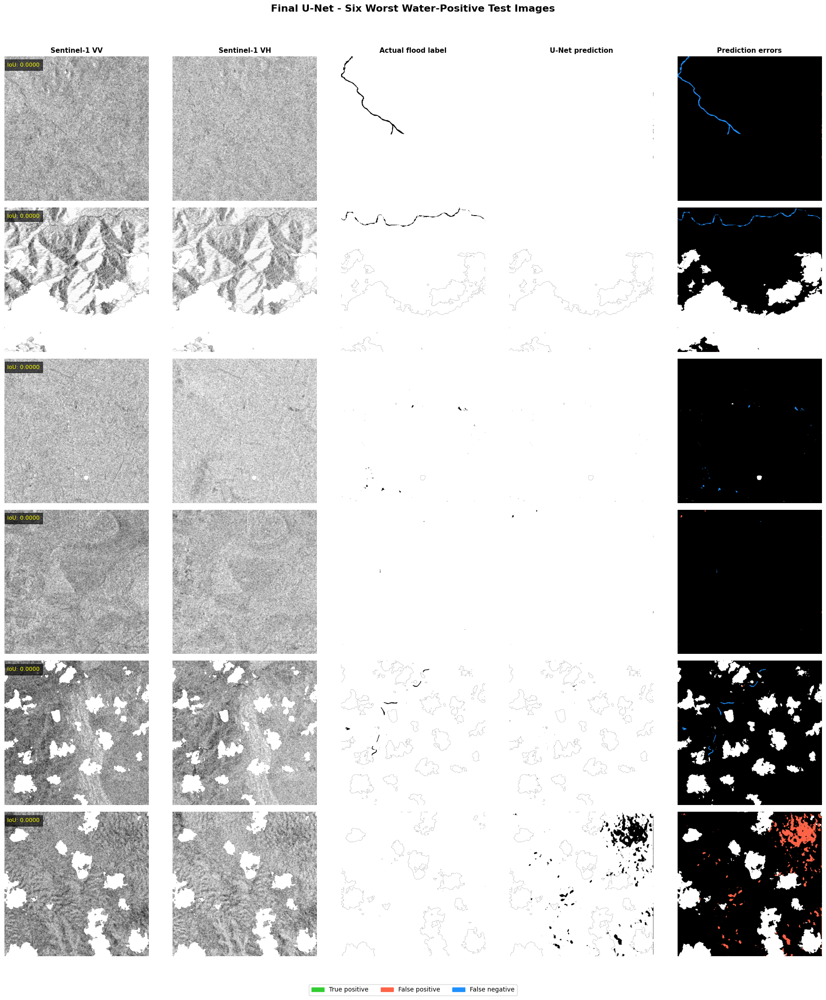

Saved: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/logs/worst_positive_visuals_final.png


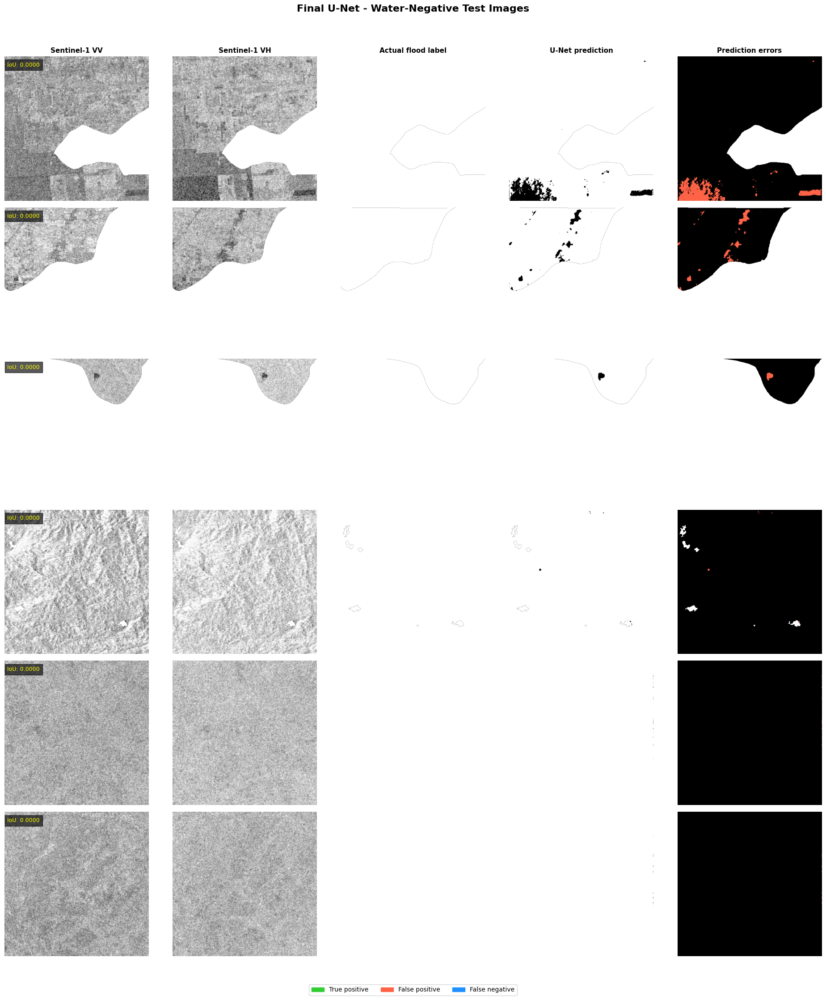

Saved: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/logs/water_negative_visuals_final.png

FINAL VISUAL ERROR ANALYSIS COMPLETED!


In [ ]:

# ==========================================================
# MEMBER A: FINAL TEST VISUAL ERROR ANALYSIS
# ==========================================================

import matplotlib.pyplot as plt
import numpy as np
import torch

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


# 1. LOAD BEST MODEL

checkpoint = torch.load(
    FINAL_BEST_PATH,
    map_location=device,
    weights_only=False
)

final_model.load_state_dict(
    checkpoint["model_state_dict"]
)

final_model.eval()

threshold = checkpoint.get(
    "prediction_threshold", 0.5
)

visual_dataset = FloodDatasetClipped(test_df)

# Match filenames to their test dataset indices
filename_to_index = {
    str(name).strip(): i
    for i, name in enumerate(test_df["satellite_image"])
}


# 2. ERROR MAP COLOURS

error_cmap = ListedColormap([
    "black",       # No error / background
    "limegreen",   # True positive
    "tomato",      # False positive
    "dodgerblue"   # False negative
])


# 3. VISUALIZATION FUNCTION

def visualize_errors(selected_df, title, output_name):

    n = len(selected_df)

    fig, axes = plt.subplots(
        n, 5,
        figsize=(19, 3.8 * n),
        squeeze=False
    )

    column_titles = [
        "Sentinel-1 VV",
        "Sentinel-1 VH",
        "Actual flood label",
        "U-Net prediction",
        "Prediction errors"
    ]

    for col, name in enumerate(column_titles):
        axes[0, col].set_title(
            name,
            fontsize=11,
            fontweight="bold"
        )

    for row_index, (_, row) in enumerate(
        selected_df.iterrows()
    ):

        filename = str(row["image"]).strip()

        if filename not in filename_to_index:
            raise ValueError(
                f"Image not found: {filename}"
            )

        idx = filename_to_index[filename]

        # Load preprocessed full-resolution sample
        image, target, mask = visual_dataset[idx]

        images = image.unsqueeze(0).to(device)

        # Model inference
        with torch.inference_mode():

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                logits = final_model(images)

            probability = torch.sigmoid(
                logits.float()
            )[0, 0].cpu().numpy()

        prediction = probability >= threshold

        actual = target[0].numpy() >= 0.5
        valid = mask[0].numpy().astype(bool)

        # Recover clipped dB values for display
        sar = (
            image.numpy() * STD[:, None, None]
            + MEAN[:, None, None]
        )

        vv = np.ma.masked_where(
            ~valid, sar[0]
        )

        vh = np.ma.masked_where(
            ~valid, sar[1]
        )

        actual_display = np.ma.masked_where(
            ~valid, actual.astype(float)
        )

        prediction_display = np.ma.masked_where(
            ~valid, prediction.astype(float)
        )

        # TP / FP / FN
        error_map = np.zeros(
            valid.shape,
            dtype=np.uint8
        )

        error_map[prediction & actual & valid] = 1
        error_map[prediction & ~actual & valid] = 2
        error_map[~prediction & actual & valid] = 3

        error_display = np.ma.masked_where(
            ~valid, error_map
        )

        # Draw panels
        panels = [
            (vv, "gray", -25, -2),
            (vh, "gray", -35, -9),
            (actual_display, "gray_r", 0, 1),
            (prediction_display, "gray_r", 0, 1),
        ]

        for col, (data, cmap, vmin, vmax) in enumerate(panels):

            axes[row_index, col].imshow(
                data,
                cmap=cmap,
                vmin=vmin,
                vmax=vmax
            )

            axes[row_index, col].axis("off")

        axes[row_index, 4].imshow(
            error_display,
            cmap=error_cmap,
            vmin=0,
            vmax=3
        )

        axes[row_index, 4].axis("off")

        # Image information
        axes[row_index, 0].set_ylabel(
            filename,
            fontsize=9,
            rotation=0,
            labelpad=105,
            va="center"
        )

        axes[row_index, 0].text(
            0.02, 0.96,
            f"IoU: {row['iou']:.4f}",
            transform=axes[row_index, 0].transAxes,
            color="yellow",
            fontsize=9,
            va="top",
            bbox=dict(facecolor="black", alpha=0.65)
        )

    fig.suptitle(
        title,
        fontsize=16,
        fontweight="bold"
    )

    legend = [
        Patch(color="limegreen", label="True positive"),
        Patch(color="tomato", label="False positive"),
        Patch(color="dodgerblue", label="False negative")
    ]

    fig.legend(
        handles=legend,
        loc="lower center",
        ncol=3,
        bbox_to_anchor=(0.5, 0.005)
    )

    plt.tight_layout(rect=[0, 0.04, 1, 0.96])

    output_path = LOG_DIR / output_name

    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", output_path)


# 4. SIX WORST WATER-POSITIVE IMAGES

worst_positive = per_image_df[
    per_image_df["actual_water_pixels"] > 0
].sort_values("iou").head(6)

visualize_errors(
    worst_positive,
    "Final U-Net - Six Worst Water-Positive Test Images",
    "worst_positive_visuals_final.png"
)


# 5. ALL WATER-NEGATIVE IMAGES

negative_images = per_image_df[
    per_image_df["actual_water_pixels"] == 0
].sort_values("fp", ascending=False)

visualize_errors(
    negative_images,
    "Final U-Net - Water-Negative Test Images",
    "water_negative_visuals_final.png"
)


print("\nFINAL VISUAL ERROR ANALYSIS COMPLETED!")


FINAL MODEL LOADED
--------------------------------
Best epoch: 22
Best validation IoU: 0.6386580853014427
Prediction threshold: 0.5

AMPHAN IMAGE INFORMATION
--------------------------------
Dimensions: 1047 x 1120
CRS: EPSG:32645
Pre valid pixels: 1146638
Post valid pixels: 1146638
Common valid pixels: 1146638

RUNNING PRE-EVENT INFERENCE...
Inference tiles: 9
Processed 9/9 tiles

RUNNING POST-EVENT INFERENCE...
Inference tiles: 9
Processed 9/9 tiles

FINAL AMPHAN ZERO-SHOT RESULTS
Best checkpoint epoch: 22
Threshold: 0.5
Common valid pixels: 1146638

PREDICTED WATER
Pre-event pixels: 188837
Pre-event area: 18.8837 km2
Post-event pixels: 179526
Post-event area: 17.9526 km2

TRANSITIONS
Persistent non-water: 956231
Persistent water: 177956
Newly predicted water: 1570
Water no longer predicted: 10881

AREA CHANGES
New water area: 0.157 km2
Lost water area: 1.0881 km2
Net predicted water change: -0.9311 km2
Jaccard similarity: 0.93461


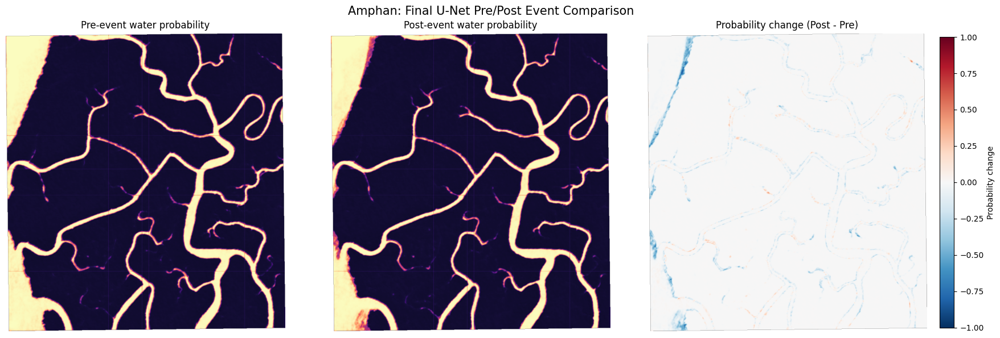


OUTPUT FILES
--------------------------------
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_pre_probability_final.tif
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_post_probability_final.tif
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_pre_prediction_final.tif
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_post_prediction_final.tif
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_transition_final.tif
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_final_comparison.png

FINAL AMPHAN INFERENCE COMPLETED!


In [ ]:

# ==========================================================
# MEMBER A: FINAL AMPHAN ZERO-SHOT INFERENCE
# FINAL CLIPPED U-NET CHECKPOINT
# ==========================================================

import torch
import numpy as np
import rasterio
import json
import matplotlib.pyplot as plt

from pathlib import Path


# ==========================================================
# 1. FILE PATHS
# ==========================================================

PRE_PATH = Path(
    "/content/drive/MyDrive/FloodProject/test_pre_event_s1.tif"
)

POST_PATH = Path(
    "/content/drive/MyDrive/FloodProject/test_post_event_s1.tif"
)

RESULT_DIR = (
    PROJECT_DIR / "results/amphan_final"
)

RESULT_DIR.mkdir(parents=True, exist_ok=True)

PRE_OUTPUT = RESULT_DIR / "amphan_pre_probability_final.tif"
POST_OUTPUT = RESULT_DIR / "amphan_post_probability_final.tif"

PRE_BINARY_OUTPUT = RESULT_DIR / "amphan_pre_prediction_final.tif"
POST_BINARY_OUTPUT = RESULT_DIR / "amphan_post_prediction_final.tif"

TRANSITION_OUTPUT = RESULT_DIR / "amphan_transition_final.tif"

COMPARISON_OUTPUT = RESULT_DIR / "amphan_final_comparison.png"


# ==========================================================
# 2. LOAD MATCHING PREPROCESSING STATISTICS
# ==========================================================

with open(
    PROJECT_DIR / "data/processed/normalization_stats_clipped.json",
    "r"
) as f:

    stats = json.load(f)

MEAN_FINAL = np.asarray(stats["mean"], dtype=np.float32)
STD_FINAL = np.asarray(stats["std"], dtype=np.float32)

CLIP_MIN_FINAL = np.asarray(
    stats["clip_min"], dtype=np.float32
)

CLIP_MAX_FINAL = np.asarray(
    stats["clip_max"], dtype=np.float32
)


# ==========================================================
# 3. LOAD FINAL BEST CHECKPOINT
# ==========================================================

checkpoint = torch.load(
    FINAL_BEST_PATH,
    map_location=device,
    weights_only=False
)

final_model.load_state_dict(
    checkpoint["model_state_dict"]
)

final_model.eval()

THRESHOLD = float(
    checkpoint["prediction_threshold"]
)

print("FINAL MODEL LOADED")
print("--------------------------------")
print("Best epoch:", checkpoint["epoch"])
print("Best validation IoU:",
      checkpoint["best_validation_iou"])
print("Prediction threshold:", THRESHOLD)


# ==========================================================
# 4. READ AND VALIDATE TIFF FILES
# ==========================================================

def read_sar(path):

    with rasterio.open(path) as src:

        image = src.read().astype(np.float32)

        profile = src.profile.copy()

        transform = src.transform
        crs = src.crs
        nodata = src.nodata

    if image.ndim != 3 or image.shape[0] != 2:
        raise ValueError(
            f"Expected two bands (VV, VH): {path}"
        )

    valid = np.isfinite(image).all(axis=0)

    if nodata is not None and np.isfinite(nodata):

        valid &= np.all(
            image != nodata,
            axis=0
        )

    return image, valid, profile


pre_image, pre_valid, pre_profile = read_sar(PRE_PATH)

post_image, post_valid, post_profile = read_sar(POST_PATH)


# Verify matching grids

if pre_image.shape != post_image.shape:
    raise ValueError("Pre/post dimensions do not match!")

if pre_profile["transform"] != post_profile["transform"]:
    raise ValueError("Pre/post transforms do not match!")

if pre_profile["crs"] != post_profile["crs"]:
    raise ValueError("Pre/post CRS does not match!")

HEIGHT, WIDTH = pre_image.shape[1:]

print("\nAMPHAN IMAGE INFORMATION")
print("--------------------------------")
print("Dimensions:", WIDTH, "x", HEIGHT)
print("CRS:", pre_profile["crs"])
print("Pre valid pixels:", int(pre_valid.sum()))
print("Post valid pixels:", int(post_valid.sum()))

common_valid = pre_valid & post_valid

print("Common valid pixels:", int(common_valid.sum()))


# ==========================================================
# 5. APPLY EXACT TRAINING PREPROCESSING
# ==========================================================

def preprocess_sar(image, valid):

    clipped = np.clip(
        image,
        CLIP_MIN_FINAL[:, None, None],
        CLIP_MAX_FINAL[:, None, None]
    )

    normalized = (
        clipped - MEAN_FINAL[:, None, None]
    ) / STD_FINAL[:, None, None]

    normalized[:, ~valid] = 0.0

    return normalized.astype(np.float32)


pre_normalized = preprocess_sar(
    pre_image, pre_valid
)

post_normalized = preprocess_sar(
    post_image, post_valid
)


# ==========================================================
# 6. SLIDING-WINDOW INFERENCE
# ==========================================================

PATCH_SIZE = 512
STRIDE = 384
INFERENCE_BATCH_SIZE = 4


def get_positions(length):

    if length <= PATCH_SIZE:
        return [0]

    positions = list(
        range(
            0,
            length - PATCH_SIZE + 1,
            STRIDE
        )
    )

    last_position = length - PATCH_SIZE

    if positions[-1] != last_position:
        positions.append(last_position)

    return positions


def predict_large_image(image, valid):

    pad_h = max(0, PATCH_SIZE - image.shape[1])
    pad_w = max(0, PATCH_SIZE - image.shape[2])

    padded = np.pad(
        image,
        ((0, 0), (0, pad_h), (0, pad_w)),
        mode="reflect"
    )

    padded_valid = np.pad(
        valid,
        ((0, pad_h), (0, pad_w)),
        mode="constant",
        constant_values=False
    )

    h, w = padded.shape[1:]

    y_positions = get_positions(h)
    x_positions = get_positions(w)

    coordinates = [
        (y, x)
        for y in y_positions
        for x in x_positions
    ]

    probability_sum = np.zeros(
        (h, w),
        dtype=np.float32
    )

    probability_count = np.zeros(
        (h, w),
        dtype=np.float32
    )

    print("Inference tiles:", len(coordinates))

    with torch.inference_mode():

        for start in range(
            0,
            len(coordinates),
            INFERENCE_BATCH_SIZE
        ):

            batch_coords = coordinates[
                start:start + INFERENCE_BATCH_SIZE
            ]

            patches = np.stack([
                padded[
                    :,
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ]
                for y, x in batch_coords
            ])

            tensor = torch.from_numpy(
                np.ascontiguousarray(patches)
            ).to(device)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                logits = final_model(tensor)

            probabilities = torch.sigmoid(
                logits.float()
            ).cpu().numpy()[:, 0]

            for probability, (y, x) in zip(
                probabilities,
                batch_coords
            ):

                probability_sum[
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ] += probability

                probability_count[
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ] += 1

            print(
                f"Processed {min(start + len(batch_coords), len(coordinates))}"
                f"/{len(coordinates)} tiles",
                end="\r"
            )

    print()

    averaged = probability_sum / np.maximum(
        probability_count, 1
    )

    averaged = averaged[:HEIGHT, :WIDTH]

    averaged[~valid] = np.nan

    return averaged


# ==========================================================
# 7. RUN PRE/POST INFERENCE
# ==========================================================

print("\nRUNNING PRE-EVENT INFERENCE...")

pre_probability = predict_large_image(
    pre_normalized,
    pre_valid
)

print("\nRUNNING POST-EVENT INFERENCE...")

post_probability = predict_large_image(
    post_normalized,
    post_valid
)


# ==========================================================
# 8. GENERATE BINARY PREDICTIONS
# ==========================================================

pre_binary = pre_probability >= THRESHOLD

post_binary = post_probability >= THRESHOLD


# ==========================================================
# 9. SAVE GEOTIFF OUTPUTS
# ==========================================================

def save_single_band(path, array, profile, dtype, nodata):

    output_profile = profile.copy()

    output_profile.update(
        driver="GTiff",
        count=1,
        dtype=dtype,
        nodata=nodata,
        compress="deflate"
    )

    with rasterio.open(
        path,
        "w",
        **output_profile
    ) as dst:

        dst.write(
            array.astype(dtype),
            1
        )


save_single_band(
    PRE_OUTPUT,
    np.where(pre_valid, pre_probability, -9999),
    pre_profile,
    "float32",
    -9999
)

save_single_band(
    POST_OUTPUT,
    np.where(post_valid, post_probability, -9999),
    post_profile,
    "float32",
    -9999
)

save_single_band(
    PRE_BINARY_OUTPUT,
    np.where(pre_valid, pre_binary, 255),
    pre_profile,
    "uint8",
    255
)

save_single_band(
    POST_BINARY_OUTPUT,
    np.where(post_valid, post_binary, 255),
    post_profile,
    "uint8",
    255
)


# ==========================================================
# 10. BINARY TRANSITION ANALYSIS
# ==========================================================

transition = np.full(
    common_valid.shape,
    255,
    dtype=np.uint8
)

# 0 = Persistent non-water
# 1 = Persistent water
# 2 = Newly predicted water
# 3 = Water no longer predicted

persistent_nonwater = (
    ~pre_binary & ~post_binary & common_valid
)

persistent_water = (
    pre_binary & post_binary & common_valid
)

new_water = (
    ~pre_binary & post_binary & common_valid
)

lost_water = (
    pre_binary & ~post_binary & common_valid
)

transition[persistent_nonwater] = 0
transition[persistent_water] = 1
transition[new_water] = 2
transition[lost_water] = 3

save_single_band(
    TRANSITION_OUTPUT,
    transition,
    pre_profile,
    "uint8",
    255
)


# ==========================================================
# 11. AREA CALCULATION
# ==========================================================

transform = pre_profile["transform"]
crs = pre_profile["crs"]

if crs is None or not crs.is_projected:
    raise ValueError(
        "Expected projected CRS for square-metre area calculation."
    )

pixel_area_m2 = abs(
    transform.a * transform.e -
    transform.b * transform.d
)

pixel_area_km2 = pixel_area_m2 / 1e6

total_valid = int(common_valid.sum())

pre_water = int((pre_binary & common_valid).sum())
post_water = int((post_binary & common_valid).sum())

new_count = int(new_water.sum())
lost_count = int(lost_water.sum())

persistent_count = int(persistent_water.sum())
nonwater_count = int(persistent_nonwater.sum())


# ==========================================================
# 12. DISPLAY FINAL RESULTS
# ==========================================================

print("\n========================================")
print("FINAL AMPHAN ZERO-SHOT RESULTS")
print("========================================")

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Threshold:", THRESHOLD)
print("Common valid pixels:", total_valid)

print("\nPREDICTED WATER")

print("Pre-event pixels:", pre_water)
print("Pre-event area:",
      round(pre_water * pixel_area_km2, 4), "km2")

print("Post-event pixels:", post_water)
print("Post-event area:",
      round(post_water * pixel_area_km2, 4), "km2")

print("\nTRANSITIONS")

print("Persistent non-water:", nonwater_count)
print("Persistent water:", persistent_count)

print("Newly predicted water:", new_count)
print("Water no longer predicted:", lost_count)

print("\nAREA CHANGES")

print("New water area:",
      round(new_count * pixel_area_km2, 4), "km2")

print("Lost water area:",
      round(lost_count * pixel_area_km2, 4), "km2")

print("Net predicted water change:",
      round(
          (post_water - pre_water) * pixel_area_km2,
          4
      ), "km2")

print(
    "Jaccard similarity:",
    round(
        persistent_count /
        max(pre_water + post_water - persistent_count, 1),
        5
    )
)


# ==========================================================
# 13. COMPARISON FIGURE
# ==========================================================

change = post_probability - pre_probability

change_display = np.ma.masked_where(
    ~common_valid,
    change
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

axes[0].imshow(
    np.ma.masked_where(
        ~common_valid,
        pre_probability
    ),
    cmap="magma",
    vmin=0,
    vmax=1
)

axes[0].set_title("Pre-event water probability")

axes[1].imshow(
    np.ma.masked_where(
        ~common_valid,
        post_probability
    ),
    cmap="magma",
    vmin=0,
    vmax=1
)

axes[1].set_title("Post-event water probability")

im = axes[2].imshow(
    change_display,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

axes[2].set_title("Probability change (Post - Pre)")

for ax in axes:
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes[2],
    fraction=0.046,
    pad=0.04,
    label="Probability change"
)

plt.suptitle(
    "Amphan: Final U-Net Pre/Post Event Comparison",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    COMPARISON_OUTPUT,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


print("\nOUTPUT FILES")
print("--------------------------------")

print(PRE_OUTPUT)
print(POST_OUTPUT)
print(PRE_BINARY_OUTPUT)
print(POST_BINARY_OUTPUT)
print(TRANSITION_OUTPUT)
print(COMPARISON_OUTPUT)

print("\nFINAL AMPHAN INFERENCE COMPLETED!")


RUNNING BLENDED PRE-EVENT INFERENCE...
Processed 9/9 tiles

RUNNING BLENDED POST-EVENT INFERENCE...
Processed 9/9 tiles


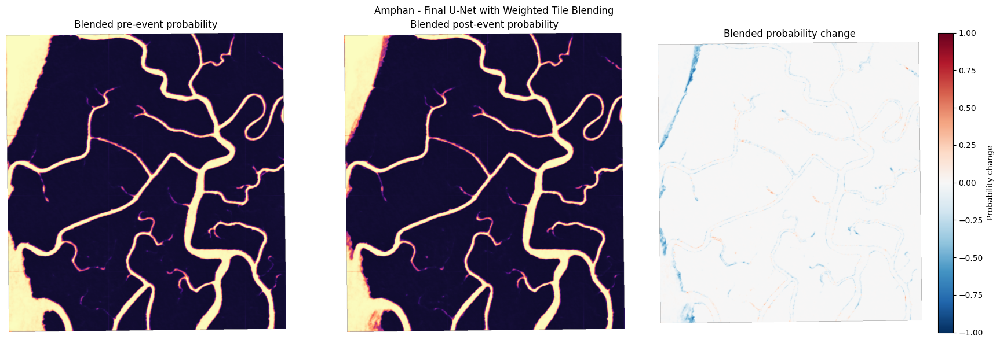


WEIGHTED BLENDED AMPHAN RESULTS
Pre-event predicted water: 18.8729 km2
Post-event predicted water: 17.9365 km2
Persistent water: 17.779 km2
Newly predicted water: 0.1575 km2
Water no longer predicted: 1.0939 km2
Persistent non-water: 95.6334 km2
Net predicted change: -0.9364 km2
Jaccard similarity: 0.93424

SAVED FILES
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_pre_probability_blended.tif
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_post_probability_blended.tif
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_transition_blended.tif
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_final_blended_comparison.png

WEIGHTED BLENDING COMPLETED!


In [ ]:

# ==========================================================
# MEMBER A: SEAM-REDUCED AMPHAN INFERENCE
# GAUSSIAN-CENTRE-WEIGHTED PATCH BLENDING
# ==========================================================

import numpy as np
import torch
import matplotlib.pyplot as plt
import rasterio
from pathlib import Path


# 1. INFERENCE SETTINGS

PATCH_SIZE = 512
STRIDE = 384
BATCH_SIZE = 4

# Centre-weighted blending window
window_1d = np.hanning(PATCH_SIZE).astype(np.float32)

blend_window = np.outer(
    window_1d,
    window_1d
)

# Avoid zero weights at outer image boundaries
blend_window = np.maximum(
    blend_window,
    0.05
)


# 2. SLIDING-WINDOW POSITION FUNCTION

def get_blend_positions(length):

    if length <= PATCH_SIZE:
        return [0]

    positions = list(
        range(0, length - PATCH_SIZE + 1, STRIDE)
    )

    last = length - PATCH_SIZE

    if positions[-1] != last:
        positions.append(last)

    return positions


# 3. WEIGHTED INFERENCE

def predict_blended(image, valid):

    pad_h = max(0, PATCH_SIZE - image.shape[1])
    pad_w = max(0, PATCH_SIZE - image.shape[2])

    padded = np.pad(
        image,
        ((0, 0), (0, pad_h), (0, pad_w)),
        mode="reflect"
    )

    padded_valid = np.pad(
        valid,
        ((0, pad_h), (0, pad_w)),
        mode="constant",
        constant_values=False
    )

    h, w = padded.shape[1:]

    ys = get_blend_positions(h)
    xs = get_blend_positions(w)

    coordinates = [
        (y, x)
        for y in ys
        for x in xs
    ]

    probability_sum = np.zeros(
        (h, w),
        dtype=np.float32
    )

    weight_sum = np.zeros(
        (h, w),
        dtype=np.float32
    )

    with torch.inference_mode():

        for start in range(
            0,
            len(coordinates),
            BATCH_SIZE
        ):

            batch_coords = coordinates[
                start:start + BATCH_SIZE
            ]

            patches = np.stack([
                padded[
                    :,
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ]
                for y, x in batch_coords
            ])

            tensor = torch.from_numpy(
                np.ascontiguousarray(patches)
            ).to(device)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                logits = final_model(tensor)

            probabilities = torch.sigmoid(
                logits.float()
            ).cpu().numpy()[:, 0]

            for probability, (y, x) in zip(
                probabilities,
                batch_coords
            ):

                probability_sum[
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ] += probability * blend_window

                weight_sum[
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ] += blend_window

            print(
                f"Processed {min(start + BATCH_SIZE, len(coordinates))}"
                f"/{len(coordinates)} tiles",
                end="\r"
            )

    print()

    result = probability_sum / np.maximum(
        weight_sum,
        1e-8
    )

    result = result[:HEIGHT, :WIDTH]

    result[~valid] = np.nan

    return result


# 4. RUN INFERENCE AGAIN

print("RUNNING BLENDED PRE-EVENT INFERENCE...")

pre_probability_blended = predict_blended(
    pre_normalized,
    pre_valid
)

print("\nRUNNING BLENDED POST-EVENT INFERENCE...")

post_probability_blended = predict_blended(
    post_normalized,
    post_valid
)


# 5. BINARY PREDICTIONS AND TRANSITIONS

pre_binary_blended = (
    pre_probability_blended >= THRESHOLD
)

post_binary_blended = (
    post_probability_blended >= THRESHOLD
)

common_valid = pre_valid & post_valid

new_water_blended = (
    ~pre_binary_blended
    & post_binary_blended
    & common_valid
)

lost_water_blended = (
    pre_binary_blended
    & ~post_binary_blended
    & common_valid
)

persistent_water_blended = (
    pre_binary_blended
    & post_binary_blended
    & common_valid
)

persistent_nonwater_blended = (
    ~pre_binary_blended
    & ~post_binary_blended
    & common_valid
)


# 6. SAVE BLENDED GEOTIFF FILES

PRE_BLEND_PATH = RESULT_DIR / "amphan_pre_probability_blended.tif"
POST_BLEND_PATH = RESULT_DIR / "amphan_post_probability_blended.tif"

TRANSITION_BLEND_PATH = RESULT_DIR / "amphan_transition_blended.tif"

save_single_band(
    PRE_BLEND_PATH,
    np.where(pre_valid, pre_probability_blended, -9999),
    pre_profile,
    "float32",
    -9999
)

save_single_band(
    POST_BLEND_PATH,
    np.where(post_valid, post_probability_blended, -9999),
    post_profile,
    "float32",
    -9999
)

transition_blended = np.full(
    common_valid.shape,
    255,
    dtype=np.uint8
)

transition_blended[persistent_nonwater_blended] = 0
transition_blended[persistent_water_blended] = 1
transition_blended[new_water_blended] = 2
transition_blended[lost_water_blended] = 3

save_single_band(
    TRANSITION_BLEND_PATH,
    transition_blended,
    pre_profile,
    "uint8",
    255
)


# 7. RECALCULATE AREA STATISTICS

area_km2 = pixel_area_km2

pre_count = int(
    (pre_binary_blended & common_valid).sum()
)

post_count = int(
    (post_binary_blended & common_valid).sum()
)

persistent_count = int(
    persistent_water_blended.sum()
)

new_count = int(
    new_water_blended.sum()
)

lost_count = int(
    lost_water_blended.sum()
)

nonwater_count = int(
    persistent_nonwater_blended.sum()
)

jaccard = persistent_count / max(
    pre_count + post_count - persistent_count,
    1
)


# 8. DISPLAY BLENDED RESULTS

change_blended = (
    post_probability_blended
    - pre_probability_blended
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

axes[0].imshow(
    np.ma.masked_where(
        ~common_valid,
        pre_probability_blended
    ),
    cmap="magma",
    vmin=0,
    vmax=1
)

axes[0].set_title("Blended pre-event probability")

axes[1].imshow(
    np.ma.masked_where(
        ~common_valid,
        post_probability_blended
    ),
    cmap="magma",
    vmin=0,
    vmax=1
)

axes[1].set_title("Blended post-event probability")

im = axes[2].imshow(
    np.ma.masked_where(
        ~common_valid,
        change_blended
    ),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

axes[2].set_title("Blended probability change")

for ax in axes:
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes[2],
    label="Probability change"
)

plt.suptitle(
    "Amphan - Final U-Net with Weighted Tile Blending"
)

plt.tight_layout()

BLENDED_FIGURE = (
    RESULT_DIR / "amphan_final_blended_comparison.png"
)

plt.savefig(
    BLENDED_FIGURE,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# 9. PRINT FINAL BLENDED STATISTICS

print("\n==========================================")
print("WEIGHTED BLENDED AMPHAN RESULTS")
print("==========================================")

print("Pre-event predicted water:",
      round(pre_count * area_km2, 4), "km2")

print("Post-event predicted water:",
      round(post_count * area_km2, 4), "km2")

print("Persistent water:",
      round(persistent_count * area_km2, 4), "km2")

print("Newly predicted water:",
      round(new_count * area_km2, 4), "km2")

print("Water no longer predicted:",
      round(lost_count * area_km2, 4), "km2")

print("Persistent non-water:",
      round(nonwater_count * area_km2, 4), "km2")

print("Net predicted change:",
      round((post_count - pre_count) * area_km2, 4), "km2")

print("Jaccard similarity:", round(jaccard, 5))

print("\nSAVED FILES")
print(PRE_BLEND_PATH)
print(POST_BLEND_PATH)
print(TRANSITION_BLEND_PATH)
print(BLENDED_FIGURE)

print("\nWEIGHTED BLENDING COMPLETED!")



FINAL AMPHAN COMPONENT ANALYSIS

NEWLY PREDICTED WATER
--------------------------------
Separate clusters: 689
Largest cluster: 47
Clusters >= 100 pixels: 0
Median cluster size: 1.0

TOP 10 CLUSTERS
             category  component  pixels  area_km2      center_x     center_y  longitude  latitude
NEWLY PREDICTED WATER        233      47    0.0047 678977.978723 2.418899e+06  88.732106 21.865062
NEWLY PREDICTED WATER        365      43    0.0043 681931.511628 2.416506e+06  88.760415 21.843150
NEWLY PREDICTED WATER        357      42    0.0042 681816.666667 2.416650e+06  88.759320 21.844461
NEWLY PREDICTED WATER        627      32    0.0032 685431.562500 2.412619e+06  88.793832 21.807686
NEWLY PREDICTED WATER        351      32    0.0032 680120.000000 2.416854e+06  88.742931 21.846481
NEWLY PREDICTED WATER        463      31    0.0031 677819.193548 2.415059e+06  88.720481 21.830500
NEWLY PREDICTED WATER         18      26    0.0026 685504.615385 2.421778e+06  88.795572 21.890388
NEWLY PR

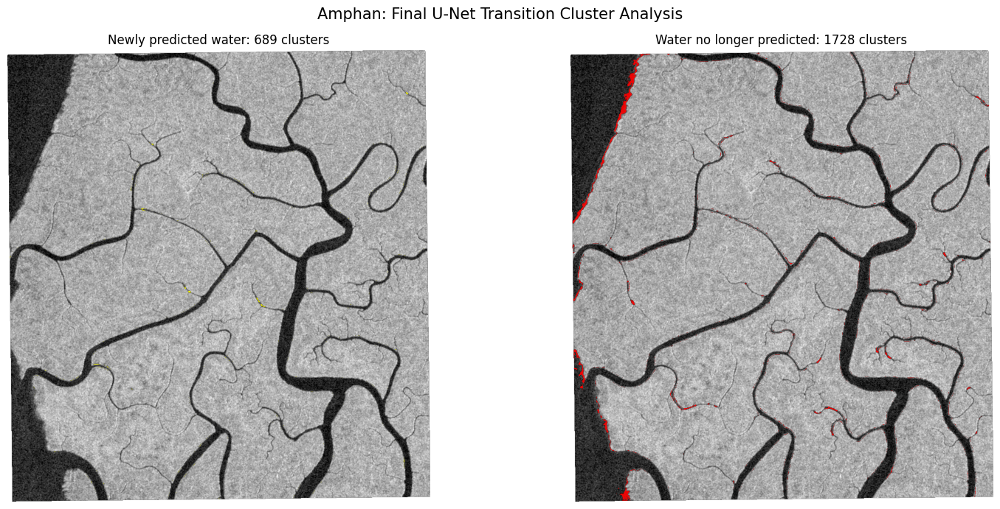


FINAL COMPONENT ANALYSIS SAVED
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_transition_components_final.csv
/content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_transition_clusters_final.png

FINAL AMPHAN CLUSTER ANALYSIS COMPLETED!


In [ ]:

# ==========================================================
# MEMBER A: FINAL AMPHAN TRANSITION CLUSTER ANALYSIS
# WEIGHTED BLENDED PREDICTIONS
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage
from matplotlib.colors import ListedColormap
from pyproj import Transformer


# 1. DEFINE CONNECTIVITY

# 8-connectivity: diagonal neighbours are connected
structure = np.ones((3, 3), dtype=np.uint8)

# Geographic coordinate transformer
transformer = Transformer.from_crs(
    pre_profile["crs"],
    "EPSG:4326",
    always_xy=True
)

affine = pre_profile["transform"]


# 2. COMPONENT ANALYSIS FUNCTION

def analyse_components(mask, category):

    labelled, number = ndimage.label(
        mask.astype(bool),
        structure=structure
    )

    if number == 0:
        print(f"\nNo components found: {category}")
        return [], labelled

    sizes = np.bincount(
        labelled.ravel()
    )

    component_ids = np.arange(1, number + 1)

    counts = sizes[1:]

    centroids = ndimage.center_of_mass(
        mask.astype(np.uint8),
        labelled,
        component_ids
    )

    records = []

    for component, pixels, centroid in zip(
        component_ids,
        counts,
        centroids
    ):

        row, col = centroid

        # Pixel-centre coordinates in projected CRS
        x = (
            affine.c
            + (col + 0.5) * affine.a
            + (row + 0.5) * affine.b
        )

        y = (
            affine.f
            + (col + 0.5) * affine.d
            + (row + 0.5) * affine.e
        )

        lon, lat = transformer.transform(x, y)

        records.append({

            "category": category,
            "component": int(component),
            "pixels": int(pixels),

            "area_km2": float(
                pixels * pixel_area_km2
            ),

            "center_x": float(x),
            "center_y": float(y),

            "longitude": float(lon),
            "latitude": float(lat)

        })

    return records, labelled


# 3. ANALYSE NEWLY PREDICTED WATER

new_records, new_labels = analyse_components(
    new_water_blended,
    "NEWLY PREDICTED WATER"
)


# 4. ANALYSE WATER NO LONGER PREDICTED

lost_records, lost_labels = analyse_components(
    lost_water_blended,
    "WATER NO LONGER PREDICTED"
)


# 5. COMBINE RESULTS

all_records = new_records + lost_records

components_df = pd.DataFrame(all_records)


# 6. SUMMARY REPORT

print("\n==========================================")
print("FINAL AMPHAN COMPONENT ANALYSIS")
print("==========================================")

for category, records in [
    ("NEWLY PREDICTED WATER", new_records),
    ("WATER NO LONGER PREDICTED", lost_records)
]:

    print(f"\n{category}")
    print("--------------------------------")

    if not records:
        print("No clusters.")
        continue

    df = pd.DataFrame(records)

    sizes = df["pixels"]

    print("Separate clusters:", len(df))
    print("Largest cluster:", int(sizes.max()))

    print(
        "Clusters >= 100 pixels:",
        int((sizes >= 100).sum())
    )

    print(
        "Median cluster size:",
        float(sizes.median())
    )

    print("\nTOP 10 CLUSTERS")

    print(
        df.sort_values(
            "pixels",
            ascending=False
        ).head(10).to_string(index=False)
    )


# 7. SAVE CLUSTER CSV

COMPONENT_CSV = (
    RESULT_DIR / "amphan_transition_components_final.csv"
)

components_df.to_csv(
    COMPONENT_CSV,
    index=False
)


# 8. VISUALISE CLUSTERS ON SAR BACKGROUND

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

sar_background = np.ma.masked_where(
    ~common_valid,
    pre_image[0]
)

for ax in axes:

    ax.imshow(
        sar_background,
        cmap="gray",
        vmin=-25,
        vmax=-2
    )

    ax.axis("off")


# Newly predicted water
new_overlay = np.ma.masked_where(
    ~new_water_blended,
    new_water_blended.astype(float)
)

axes[0].imshow(
    new_overlay,
    cmap=ListedColormap(["yellow"]),
    vmin=0,
    vmax=1,
    alpha=0.9
)

axes[0].set_title(
    f"Newly predicted water: {len(new_records)} clusters"
)


# Water no longer predicted
lost_overlay = np.ma.masked_where(
    ~lost_water_blended,
    lost_water_blended.astype(float)
)

axes[1].imshow(
    lost_overlay,
    cmap=ListedColormap(["red"]),
    vmin=0,
    vmax=1,
    alpha=0.9
)

axes[1].set_title(
    f"Water no longer predicted: {len(lost_records)} clusters"
)


plt.suptitle(
    "Amphan: Final U-Net Transition Cluster Analysis",
    fontsize=15
)

plt.tight_layout()

CLUSTER_FIGURE = (
    RESULT_DIR / "amphan_transition_clusters_final.png"
)

plt.savefig(
    CLUSTER_FIGURE,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# 9. FINAL OUTPUT

print("\n==========================================")
print("FINAL COMPONENT ANALYSIS SAVED")
print("==========================================")

print(COMPONENT_CSV)
print(CLUSTER_FIGURE)

print("\nFINAL AMPHAN CLUSTER ANALYSIS COMPLETED!")


FINAL AMPHAN THRESHOLD SENSITIVITY
 threshold  pre_water_km2  post_water_km2  new_water_km2  lost_water_km2  net_change_km2  jaccard  new_clusters  lost_clusters
       0.3        20.7527         19.8424         0.2028          1.1131         -0.9103  0.93721           691           1647
       0.4        19.7335         18.8680         0.1760          1.0415         -0.8655  0.93885           690           1646
       0.5        18.8729         17.9365         0.1575          1.0939         -0.9364  0.93424           689           1728
       0.6        18.0442         17.0151         0.1441          1.1732         -1.0291  0.92757           688           1638
       0.7        17.2356         16.1478         0.1447          1.2325         -1.0878  0.92076           659           1587


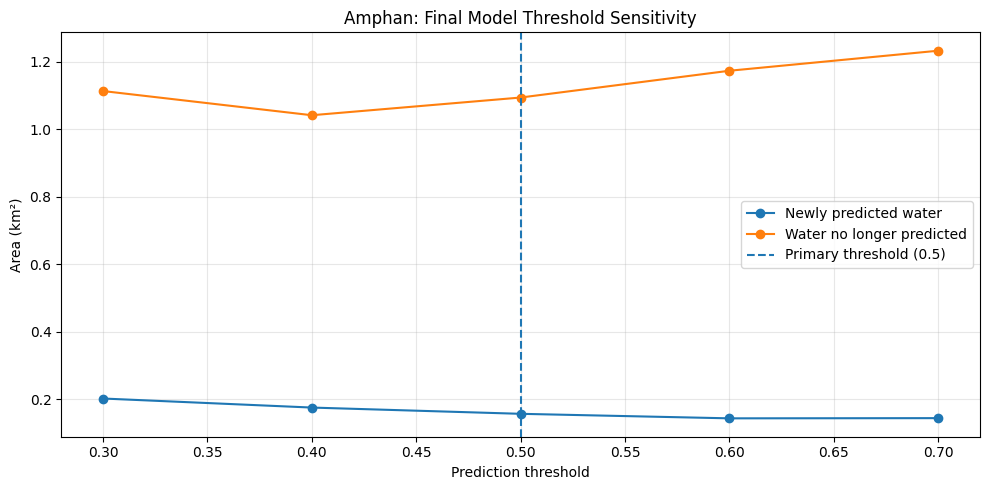

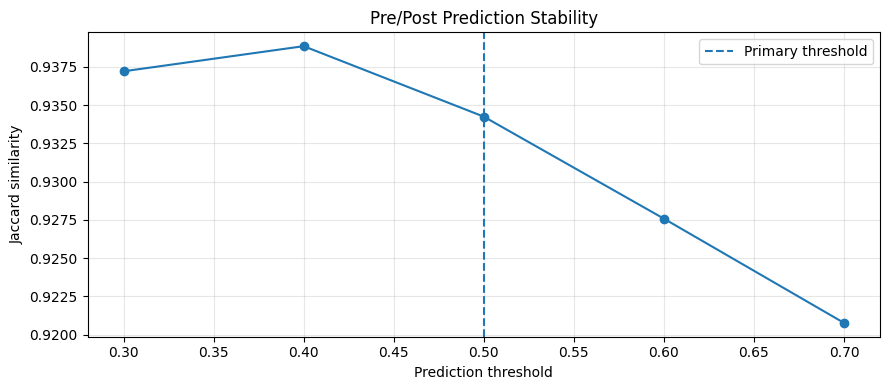


THRESHOLD SENSITIVITY COMPLETED!
Primary threshold: 0.5
CSV: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_threshold_sensitivity_final.csv
Area graph: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_threshold_sensitivity_final.png
Jaccard graph: /content/drive/MyDrive/CrossEventFloodMapping_MemberA/results/amphan_final/amphan_jaccard_sensitivity_final.png


In [ ]:

# ==========================================================
# MEMBER A: FINAL AMPHAN THRESHOLD SENSITIVITY
# WEIGHTED BLENDED PROBABILITIES
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage


# 1. THRESHOLDS

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

structure = np.ones((3, 3), dtype=np.uint8)

records = []


# 2. EVALUATE EACH THRESHOLD

for threshold in thresholds:

    pre_binary = (
        (pre_probability_blended >= threshold)
        & common_valid
    )

    post_binary = (
        (post_probability_blended >= threshold)
        & common_valid
    )

    # Transition classes
    persistent_water = (
        pre_binary & post_binary
    )

    new_water = (
        ~pre_binary & post_binary & common_valid
    )

    lost_water = (
        pre_binary & ~post_binary & common_valid
    )

    # Pixel counts
    pre_count = int(pre_binary.sum())
    post_count = int(post_binary.sum())

    persistent_count = int(persistent_water.sum())
    new_count = int(new_water.sum())
    lost_count = int(lost_water.sum())

    # Jaccard similarity
    union = pre_count + post_count - persistent_count

    jaccard = persistent_count / max(union, 1)

    # Connected components
    _, new_clusters = ndimage.label(
        new_water,
        structure=structure
    )

    _, lost_clusters = ndimage.label(
        lost_water,
        structure=structure
    )

    records.append({

        "threshold": threshold,

        "pre_water_km2":
            pre_count * pixel_area_km2,

        "post_water_km2":
            post_count * pixel_area_km2,

        "new_water_km2":
            new_count * pixel_area_km2,

        "lost_water_km2":
            lost_count * pixel_area_km2,

        "net_change_km2":
            (post_count - pre_count) * pixel_area_km2,

        "jaccard": jaccard,

        "new_clusters": new_clusters,

        "lost_clusters": lost_clusters

    })


# 3. CREATE DATAFRAME

sensitivity_df = pd.DataFrame(records)

print("FINAL AMPHAN THRESHOLD SENSITIVITY")
print("==========================================")

print(
    sensitivity_df.round(5).to_string(index=False)
)


# 4. SAVE CSV

SENSITIVITY_CSV = (
    RESULT_DIR / "amphan_threshold_sensitivity_final.csv"
)

sensitivity_df.to_csv(
    SENSITIVITY_CSV,
    index=False
)


# 5. PLOT AREA CHANGES

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    sensitivity_df["threshold"],
    sensitivity_df["new_water_km2"],
    marker="o",
    label="Newly predicted water"
)

ax.plot(
    sensitivity_df["threshold"],
    sensitivity_df["lost_water_km2"],
    marker="o",
    label="Water no longer predicted"
)

ax.axvline(
    0.5,
    linestyle="--",
    label="Primary threshold (0.5)"
)

ax.set_xlabel("Prediction threshold")
ax.set_ylabel("Area (km²)")

ax.set_title(
    "Amphan: Final Model Threshold Sensitivity"
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

SENSITIVITY_PNG = (
    RESULT_DIR / "amphan_threshold_sensitivity_final.png"
)

plt.savefig(
    SENSITIVITY_PNG,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# 6. PLOT JACCARD STABILITY

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    sensitivity_df["threshold"],
    sensitivity_df["jaccard"],
    marker="o"
)

ax.axvline(
    0.5,
    linestyle="--",
    label="Primary threshold"
)

ax.set_xlabel("Prediction threshold")
ax.set_ylabel("Jaccard similarity")

ax.set_title(
    "Pre/Post Prediction Stability"
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

JACCARD_PNG = (
    RESULT_DIR / "amphan_jaccard_sensitivity_final.png"
)

plt.savefig(
    JACCARD_PNG,
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# 7. FINAL SUMMARY

print("\n==========================================")
print("THRESHOLD SENSITIVITY COMPLETED!")
print("==========================================")

print("Primary threshold: 0.5")

print("CSV:", SENSITIVITY_CSV)
print("Area graph:", SENSITIVITY_PNG)
print("Jaccard graph:", JACCARD_PNG)


In [ ]:

print(
    sensitivity_df.round(5).to_string(index=False)
)


 threshold  pre_water_km2  post_water_km2  new_water_km2  lost_water_km2  net_change_km2  jaccard  new_clusters  lost_clusters
       0.3        20.7527         19.8424         0.2028          1.1131         -0.9103  0.93721           691           1647
       0.4        19.7335         18.8680         0.1760          1.0415         -0.8655  0.93885           690           1646
       0.5        18.8729         17.9365         0.1575          1.0939         -0.9364  0.93424           689           1728
       0.6        18.0442         17.0151         0.1441          1.1732         -1.0291  0.92757           688           1638
       0.7        17.2356         16.1478         0.1447          1.2325         -1.0878  0.92076           659           1587


In [ ]:

# ==========================================================
# MEMBER A: FINAL EXPERIMENT ARTIFACT AUDIT
# ==========================================================

from pathlib import Path
import pandas as pd
import json

ROOT = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

# 1. IMPORTANT FINAL ARTIFACTS

artifacts = {

    "Final best U-Net checkpoint":
        ROOT / "checkpoints/best_unet_resnet34_final_iou.pth",

    "Latest U-Net checkpoint":
        ROOT / "checkpoints/latest_unet_resnet34_final_iou.pth",

    "Final training history":
        ROOT / "logs/training_history_final_iou.csv",

    "Clipped normalization statistics":
        ROOT / "data/processed/normalization_stats_clipped.json",

    "Global test metrics":
        ROOT / "logs/global_test_metrics_final_iou.json",

    "Per-image test metrics":
        ROOT / "logs/per_image_test_metrics_final_iou.csv",

    "Worst positive image visualisation":
        ROOT / "logs/worst_positive_visuals_final.png",

    "Water-negative visualisation":
        ROOT / "logs/water_negative_visuals_final.png",

    "Amphan pre-event probability":
        ROOT / "results/amphan_final/amphan_pre_probability_blended.tif",

    "Amphan post-event probability":
        ROOT / "results/amphan_final/amphan_post_probability_blended.tif",

    "Amphan transition GeoTIFF":
        ROOT / "results/amphan_final/amphan_transition_blended.tif",

    "Amphan final comparison":
        ROOT / "results/amphan_final/amphan_final_blended_comparison.png",

    "Amphan transition components":
        ROOT / "results/amphan_final/amphan_transition_components_final.csv",

    "Amphan cluster visualisation":
        ROOT / "results/amphan_final/amphan_transition_clusters_final.png",

    "Threshold sensitivity CSV":
        ROOT / "results/amphan_final/amphan_threshold_sensitivity_final.csv",

    "Threshold sensitivity graph":
        ROOT / "results/amphan_final/amphan_threshold_sensitivity_final.png",

    "Jaccard sensitivity graph":
        ROOT / "results/amphan_final/amphan_jaccard_sensitivity_final.png"

}


# 2. CHECK EXISTENCE AND FILE SIZES

records = []

for name, path in artifacts.items():

    exists = path.is_file()

    size_mb = (
        round(path.stat().st_size / (1024 ** 2), 3)
        if exists else None
    )

    records.append({

        "Artifact": name,
        "Status": "AVAILABLE" if exists else "MISSING",
        "Size_MB": size_mb,
        "Path": str(path)

    })


manifest = pd.DataFrame(records)


# 3. SAVE MANIFEST

MANIFEST_PATH = ROOT / "member_a_final_artifact_manifest.csv"

manifest.to_csv(
    MANIFEST_PATH,
    index=False
)


# 4. DISPLAY RESULTS

print("MEMBER A FINAL ARTIFACT AUDIT")
print("==========================================")

print(manifest[
    ["Artifact", "Status", "Size_MB"]
].to_string(index=False))

available = sum(
    record["Status"] == "AVAILABLE"
    for record in records
)

missing = len(records) - available

print("\n==========================================")
print("TOTAL ARTIFACTS:", len(records))
print("AVAILABLE:", available)
print("MISSING:", missing)

print("\nMANIFEST SAVED:")
print(MANIFEST_PATH)

if missing == 0:
    print("\nALL FINAL ARTIFACTS VERIFIED!")
else:
    print("\nPLEASE CHECK THE MISSING ARTIFACTS.")


MEMBER A FINAL ARTIFACT AUDIT
                          Artifact    Status  Size_MB
       Final best U-Net checkpoint AVAILABLE  279.910
           Latest U-Net checkpoint AVAILABLE  279.915
            Final training history AVAILABLE    0.004
  Clipped normalization statistics AVAILABLE    0.000
               Global test metrics AVAILABLE    0.001
            Per-image test metrics AVAILABLE    0.014
Worst positive image visualisation AVAILABLE    3.876
      Water-negative visualisation AVAILABLE    2.888
      Amphan pre-event probability AVAILABLE    3.121
     Amphan post-event probability AVAILABLE    3.127
         Amphan transition GeoTIFF AVAILABLE    0.023
           Amphan final comparison AVAILABLE    1.886
      Amphan transition components AVAILABLE    0.224
      Amphan cluster visualisation AVAILABLE    1.481
         Threshold sensitivity CSV AVAILABLE    0.001
       Threshold sensitivity graph AVAILABLE    0.072
         Jaccard sensitivity graph AVAILABLE    0.07

In [1]:
from google.colab import drive
from pathlib import Path

# Connect Google Drive
drive.mount('/content/drive')

# Locate shared Member_A folder
SHARED_MEMBER_DIR = Path(
    "/content/drive/MyDrive/Member_A"
)

# Verify access
print("Shared folder exists:", SHARED_MEMBER_DIR.exists())

if SHARED_MEMBER_DIR.exists():
    print("\nShared folder contents:")
    for item in sorted(SHARED_MEMBER_DIR.iterdir()):
        print("-", item.name)
else:
    print("Folder not found. We will troubleshoot the shortcut.")

Mounted at /content/drive
Shared folder exists: True

Shared folder contents:
- 01_Notebooks
- 02_Model_Checkpoints
- 03_Training_Logs
- 04_Test_Evaluation
- 05_Amphan_Results
- 06_Documentation


In [2]:
from pathlib import Path

# Original project directory
SOURCE_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

# Shared project directory
DEST_DIR = Path(
    "/content/drive/MyDrive/Member_A"
)

print("ORIGINAL PROJECT:", SOURCE_DIR.exists())
print("SHARED PROJECT:", DEST_DIR.exists())

# Inspect important source folders
folders = [
    "checkpoints",
    "logs",
    "data/processed",
    "results/amphan_final"
]

for folder in folders:

    path = SOURCE_DIR / folder

    print(f"\n--- {folder} ---")

    if path.exists():
        for file in sorted(path.iterdir()):
            if file.is_file():
                print(file.name)
    else:
        print("Folder not found!")

ORIGINAL PROJECT: True
SHARED PROJECT: True

--- checkpoints ---
best_unet_resnet34.pth
best_unet_resnet34_clean.pth
best_unet_resnet34_final_iou.pth
latest_unet_resnet34_clean.pth
latest_unet_resnet34_final_iou.pth

--- logs ---
amphan_pre_post_comparison.png
global_test_metrics.json
global_test_metrics_final_iou.json
largest_false_alarms_final.csv
negative_image_audit_final.csv
per_image_test_metrics.csv
per_image_test_metrics_final_iou.csv
test_error_audit.csv
training_history.csv
training_history_clean.csv
training_history_final_iou.csv
training_validation_loss.png
water_negative_visuals_final.png
worst_five_images.png
worst_positive_images_final.csv
worst_positive_visuals_final.png

--- data/processed ---
normalization_stats.json
normalization_stats_clipped.json

--- results/amphan_final ---
amphan_final_blended_comparison.png
amphan_final_comparison.png
amphan_jaccard_sensitivity_final.png
amphan_post_prediction_final.tif
amphan_post_probability_blended.tif
amphan_post_probabilit

In [3]:
from pathlib import Path
import uuid

DEST_DIR = Path("/content/drive/MyDrive/Member_A")

# Create a temporary test file
test_file = DEST_DIR / f".write_test_{uuid.uuid4().hex}.tmp"

try:
    test_file.write_text("Drive write test successful!")

    print("WRITE ACCESS: SUCCESS")

    # Remove only the temporary file created by this test
    test_file.unlink()

    print("Temporary test file removed.")

except Exception as e:
    print("WRITE ACCESS FAILED:")
    print(repr(e))

WRITE ACCESS: SUCCESS
Temporary test file removed.


In [4]:

from pathlib import Path
import shutil

# ==========================================
# MEMBER A: TRANSFER FINAL PROJECT ARTIFACTS
# ==========================================

SOURCE_DIR = Path(
    "/content/drive/MyDrive/CrossEventFloodMapping_MemberA"
)

DEST_DIR = Path(
    "/content/drive/MyDrive/Member_A"
)

copied = []
skipped = []
missing = []

def copy_artifact(relative_path, destination_folder):

    source = SOURCE_DIR / relative_path
    destination = DEST_DIR / destination_folder / source.name

    if not source.is_file():
        missing.append(str(relative_path))
        print("MISSING:", relative_path)
        return

    if destination.exists():

        if destination.stat().st_size == source.stat().st_size:
            skipped.append(source.name)
            print("ALREADY PRESENT:", source.name)
            return

        print("CONFLICT - NOT OVERWRITTEN:", source.name)
        return

    shutil.copy2(source, destination)

    copied.append(source.name)
    print("COPIED:", source.name)


# 1. FINAL MODEL CHECKPOINTS

print("\n1. MODEL CHECKPOINTS")

for filename in [
    "best_unet_resnet34_final_iou.pth",
    "latest_unet_resnet34_final_iou.pth"
]:
    copy_artifact(
        Path("checkpoints") / filename,
        "02_Model_Checkpoints"
    )


# 2. TRAINING LOGS AND NORMALIZATION

print("\n2. TRAINING LOGS")

for filename in [
    "training_history_final_iou.csv",
    "global_test_metrics_final_iou.json",
]:
    # Test metrics are transferred separately below.
    if filename == "training_history_final_iou.csv":
        copy_artifact(
            Path("logs") / filename,
            "03_Training_Logs"
        )

copy_artifact(
    Path("data/processed/normalization_stats_clipped.json"),
    "03_Training_Logs"
)

# Optional final artifact manifest
manifest = SOURCE_DIR / "member_a_final_artifact_manifest.csv"

if manifest.is_file():
    copy_artifact(
        Path("member_a_final_artifact_manifest.csv"),
        "03_Training_Logs"
    )


# 3. TEST EVALUATION

print("\n3. TEST EVALUATION")

evaluation_files = [
    "global_test_metrics_final_iou.json",
    "per_image_test_metrics_final_iou.csv",
    "largest_false_alarms_final.csv",
    "negative_image_audit_final.csv",
    "worst_positive_images_final.csv",
    "worst_positive_visuals_final.png",
    "water_negative_visuals_final.png"
]

for filename in evaluation_files:
    copy_artifact(
        Path("logs") / filename,
        "04_Test_Evaluation"
    )


# 4. ALL FINAL AMPHAN OUTPUTS

print("\n4. AMPHAN RESULTS")

amphan_source = SOURCE_DIR / "results/amphan_final"
amphan_destination = DEST_DIR / "05_Amphan_Results"

for source in sorted(amphan_source.iterdir()):

    if source.is_file():
        destination = amphan_destination / source.name

        if destination.exists():

            if destination.stat().st_size == source.stat().st_size:
                skipped.append(source.name)
                print("ALREADY PRESENT:", source.name)
                continue

            print("CONFLICT - NOT OVERWRITTEN:", source.name)
            continue

        shutil.copy2(source, destination)
        copied.append(source.name)
        print("COPIED:", source.name)


# 5. FINAL VERIFICATION

print("\n================================")
print("TRANSFER SUMMARY")
print("================================")

print("New files copied:", len(copied))
print("Existing identical files skipped:", len(skipped))
print("Missing source files:", len(missing))

print("\nDESTINATION FOLDER SUMMARY")

for folder in sorted(DEST_DIR.iterdir()):

    if folder.is_dir():
        files = [f for f in folder.iterdir() if f.is_file()]
        total_size = sum(f.stat().st_size for f in files)

        print(
            f"{folder.name}: {len(files)} files, "
            f"{total_size / (1024**2):.2f} MB"
        )

print("\nARTIFACT TRANSFER FINISHED!")



1. MODEL CHECKPOINTS
COPIED: best_unet_resnet34_final_iou.pth
COPIED: latest_unet_resnet34_final_iou.pth

2. TRAINING LOGS
COPIED: training_history_final_iou.csv
COPIED: normalization_stats_clipped.json
COPIED: member_a_final_artifact_manifest.csv

3. TEST EVALUATION
COPIED: global_test_metrics_final_iou.json
COPIED: per_image_test_metrics_final_iou.csv
COPIED: largest_false_alarms_final.csv
COPIED: negative_image_audit_final.csv
COPIED: worst_positive_images_final.csv
COPIED: worst_positive_visuals_final.png
COPIED: water_negative_visuals_final.png

4. AMPHAN RESULTS
COPIED: amphan_final_blended_comparison.png
COPIED: amphan_final_comparison.png
COPIED: amphan_jaccard_sensitivity_final.png
COPIED: amphan_post_prediction_final.tif
COPIED: amphan_post_probability_blended.tif
COPIED: amphan_post_probability_final.tif
COPIED: amphan_pre_prediction_final.tif
COPIED: amphan_pre_probability_blended.tif
COPIED: amphan_pre_probability_final.tif
COPIED: amphan_threshold_sensitivity_final.csv
C